# DATA PREPARATION

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

In [3]:
df_customers_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_customers_dataset.csv')
df_geolocation_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_geolocation_dataset.csv')
df_order_items_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_order_items_dataset.csv')
df_order_payments_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_order_payments_dataset.csv')
df_order_reviews_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_order_reviews_dataset.csv')
df_orders_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_orders_dataset.csv')
df_products_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_products_dataset.csv')
df_sellers_ori=pd.read_csv('/content/drive/MyDrive/Validasi/olist_sellers_dataset.csv')
df_product_category_name_translation_ori=pd.read_csv('/content/drive/MyDrive/Validasi/product_category_name_translation.csv')

## CUSTOMERS

In [4]:
df_customers_ori.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [5]:
df_customers_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [6]:
df_customers_dc = df_customers_ori[
    [
        'customer_id',
        'customer_unique_id',
        'customer_state'
    ]
].copy()

In [7]:
#Standarisasi customer_state
df_customers_dc['customer_state'] = (
    df_customers_dc['customer_state']
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
)

In [8]:
print('Missing value:')
print(df_customers_dc.isnull().sum())

Missing value:
customer_id           0
customer_unique_id    0
customer_state        0
dtype: int64


In [9]:
df_customers_dc = df_customers_ori.copy()

In [10]:
duplicate_customers = (
    df_customers_dc
    .duplicated(
        subset=['customer_id'],
        keep=False
    )
)

print(
    'Jumlah duplikasi customer_id:',
    duplicate_customers.sum()
)

df_customers_dc[
    duplicate_customers
].sort_values('customer_id')

Jumlah duplikasi customer_id: 0


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state


In [11]:
df_customers_dc = df_customers_dc[
    ['customer_id', 'customer_unique_id', 'customer_state']
]

In [12]:
df_customers_dc.isnull().sum()

,0
customer_id,0
customer_unique_id,0
customer_state,0


In [13]:
print('Nilai customer_state:')
print(sorted(df_customers_dc['customer_state'].unique()))

Nilai customer_state:
['AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF', 'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA', 'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO', 'RR', 'RS', 'SC', 'SE', 'SP', 'TO']


In [14]:
#Validasi customer_state
valid_customer_states = {
    'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF',
    'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA',
    'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO',
    'RR', 'RS', 'SC', 'SE', 'SP', 'TO'
}

invalid_customer_states = df_customers_dc[
    ~df_customers_dc['customer_state'].isin(
        valid_customer_states
    )
]

print(
    'Jumlah customer state tidak valid:',
    len(invalid_customer_states)
)

Jumlah customer state tidak valid: 0


In [15]:
print('Jumlah baris:', len(df_customers_dc))

print('\nMissing value:')
print(df_customers_dc.isnull().sum())

print(
    '\nDuplikasi customer_id:',
    df_customers_dc
    .duplicated(subset=['customer_id'])
    .sum()
)

print(
    '\nJumlah customer unik:',
    df_customers_dc['customer_unique_id'].nunique()
)

print(
    '\nJumlah customer state:',
    df_customers_dc['customer_state'].nunique()
)

df_customers_dc.info()

Jumlah baris: 99441

Missing value:
customer_id           0
customer_unique_id    0
customer_state        0
dtype: int64

Duplikasi customer_id: 0

Jumlah customer unik: 96096

Jumlah customer state: 27
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         99441 non-null  object
 1   customer_unique_id  99441 non-null  object
 2   customer_state      99441 non-null  object
dtypes: object(3)
memory usage: 2.3+ MB


## GEOLOCATION

In [16]:
df_geolocation_ori.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [17]:
df_geolocation_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [18]:
df_geolocation_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [19]:
df_geolocation_ori.columns

Index(['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng',
       'geolocation_city', 'geolocation_state'],
      dtype='object')

In [20]:
df_geolocation_ori[df_geolocation_ori.columns[1]].value_counts()

,count
geolocation_lat,
-27.102099,314
-23.495901,190
-23.506049,141
-23.490618,127
-23.005514,102
...,...
-22.596805,1
-22.879978,1
-23.104188,1


In [21]:
df_geolocation_ori[df_geolocation_ori.columns[2]].value_counts()

,count
geolocation_lng,
-48.629613,314
-46.874687,190
-46.717377,141
-46.869004,127
-43.375964,102
...,...
-48.801392,1
-48.453340,1
-48.461358,1


In [22]:
df_geolocation_ori[df_geolocation_ori.columns[3]].value_counts()

,count
geolocation_city,
sao paulo,135800
rio de janeiro,62151
belo horizonte,27805
são paulo,24918
curitiba,16593
...,...
tres irmaos,1
morro chato,1
valao do barro,1


In [23]:
df_geolocation_ori[df_geolocation_ori.columns[4]].value_counts()

,count
geolocation_state,
SP,404268
MG,126336
RJ,121169
RS,61851
PR,57859
SC,38328
BA,36045
GO,20139
ES,16748


Insight:
Tabel geolocation tidak akan digunakan untuk analisis kita karena isi tabel geolocation tidak terlalu berkontribusi langsung terhadap sales performance. Untuk informasi mengenai location, kita sudah bisa mengambil nya dari tabel customers atau seller.

## PRODUCTS

In [24]:
df_products_ori.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [25]:
df_products_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [26]:
df_products_dc = df_products_ori[
    ['product_id', 'product_category_name']
].copy()

In [27]:
df_products_dc.head()

,product_id,product_category_name
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria
1,3aa071139cb16b67ca9e5dea641aaa2f,artes
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer
3,cef67bcfe19066a932b7673e239eb23d,bebes
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas


In [28]:
df_products_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   product_id             32951 non-null  object
 1   product_category_name  32341 non-null  object
dtypes: object(2)
memory usage: 515.0+ KB


Dari tabel products, kolom yang dipakai dan berhubungan dengan analisis sales performance yang masuk kedalam KPI utama analisis hanya kolom product_id dan product_category_name. untuk kolom 2-8 tidak masuk dalam analisis dan akan di drop

In [29]:
#Mengisi data yang kosong pada product category name dengan 'unknown'
df_products_dc['product_category_name'] = (
    df_products_dc['product_category_name']
    .fillna('unknown')
    .str.strip()
    .str.lower()
    .replace('', 'unknown')
)

In [30]:
print('Missing value:')
print(df_products_dc.isnull().sum())

print(
    '\nJumlah kategori unknown:',
    (df_products_dc['product_category_name'] == 'unknown').sum()
)

Missing value:
product_id               0
product_category_name    0
dtype: int64

Jumlah kategori unknown: 610


In [31]:
#Pemeriksaan nilai kategori
print(
    'Jumlah kategori unik:',
    df_products_dc['product_category_name'].nunique()
)

print('\nDaftar kategori:')
print(
    df_products_dc['product_category_name']
    .value_counts()
    .sort_index()
)

Jumlah kategori unik: 74

Daftar kategori:
product_category_name
agro_industria_e_comercio      74
alimentos                      82
alimentos_bebidas             104
artes                          55
artes_e_artesanato             19
                             ... 
tablets_impressao_imagem        9
telefonia                    1134
telefonia_fixa                116
unknown                       610
utilidades_domesticas        2335
Name: count, Length: 74, dtype: int64


In [32]:
duplicate_products = (
    df_products_dc
    .duplicated(
        subset=['product_id'],
        keep=False
    )
)

print(
    'Jumlah baris duplikat:',
    duplicate_products.sum()
)

df_products_dc[
    duplicate_products
].sort_values('product_id')

Jumlah baris duplikat: 0


,product_id,product_category_name


In [33]:
df_products_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   product_id             32951 non-null  object
 1   product_category_name  32951 non-null  object
dtypes: object(2)
memory usage: 515.0+ KB


In [34]:
print('Jumlah baris:', len(df_products_dc))

print('\nMissing value:')
print(df_products_dc.isnull().sum())

print(
    '\nDuplikasi product_id:',
    df_products_dc
    .duplicated(subset=['product_id'])
    .sum()
)

print('\nTipe data:')
df_products_dc.info()

Jumlah baris: 32951

Missing value:
product_id               0
product_category_name    0
dtype: int64

Duplikasi product_id: 0

Tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   product_id             32951 non-null  object
 1   product_category_name  32951 non-null  object
dtypes: object(2)
memory usage: 515.0+ KB


## SELLERS

In [35]:
df_sellers_ori.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [36]:
df_sellers_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [37]:
df_sellers_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [38]:
df_sellers_dc = df_sellers_ori[
    ['seller_id', 'seller_state']
].copy()

In [39]:
#Standarisasi seller_state
df_sellers_dc['seller_state'] = (
    df_sellers_dc['seller_state']
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
)

In [40]:
#Validasi seller_state
valid_seller_states = {
    'AC', 'AL', 'AM', 'AP', 'BA', 'CE', 'DF',
    'ES', 'GO', 'MA', 'MG', 'MS', 'MT', 'PA',
    'PB', 'PE', 'PI', 'PR', 'RJ', 'RN', 'RO',
    'RR', 'RS', 'SC', 'SE', 'SP', 'TO'
}

invalid_seller_states = df_sellers_dc[
    ~df_sellers_dc['seller_state'].isin(
        valid_seller_states
    )
]

print(
    'Jumlah seller state tidak valid:',
    len(invalid_seller_states)
)

print(
    'Jumlah seller state yang tersedia:',
    df_sellers_dc['seller_state'].nunique()
)

Jumlah seller state tidak valid: 0
Jumlah seller state yang tersedia: 23


In [41]:
print('Missing value:')
print(df_sellers_dc.isnull().sum())

Missing value:
seller_id       0
seller_state    0
dtype: int64


In [42]:
df_sellers_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   seller_id     3095 non-null   object
 1   seller_state  3095 non-null   object
dtypes: object(2)
memory usage: 48.5+ KB


In [43]:
df_sellers_dc.isnull().sum()

,0
seller_id,0
seller_state,0


Kolom 'seller_zip_code_prefix' akan di drop, karena tidak akan masuk dalam analisis sales performance dan tidak berkontribusi dalam KPI utama nantinya

Sama seperti kolom 'seller_zip_code_prefix', akan di drop karena tidak akan masuk dalam analisis sales performance dan tidak berkontribusi dalam KPI utama nantinya

In [44]:
duplicate_sellers = (
    df_sellers_dc
    .duplicated(
        subset=['seller_id'],
        keep=False
    )
)

print(
    'Jumlah duplikasi seller_id:',
    duplicate_sellers.sum()
)

df_sellers_dc[
    duplicate_sellers
].sort_values('seller_id')

Jumlah duplikasi seller_id: 0


,seller_id,seller_state


In [45]:
df_sellers_dc.head()

,seller_id,seller_state
0,3442f8959a84dea7ee197c632cb2df15,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,SP


In [46]:
df_sellers_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   seller_id     3095 non-null   object
 1   seller_state  3095 non-null   object
dtypes: object(2)
memory usage: 48.5+ KB


In [47]:
print('Jumlah baris:', len(df_sellers_dc))

print('\nMissing value:')
print(df_sellers_dc.isnull().sum())

print(
    '\nDuplikasi seller_id:',
    df_sellers_dc
    .duplicated(subset=['seller_id'])
    .sum()
)

print(
    '\nJumlah seller state:',
    df_sellers_dc['seller_state'].nunique()
)

df_sellers_dc.info()

Jumlah baris: 3095

Missing value:
seller_id       0
seller_state    0
dtype: int64

Duplikasi seller_id: 0

Jumlah seller state: 23
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   seller_id     3095 non-null   object
 1   seller_state  3095 non-null   object
dtypes: object(2)
memory usage: 48.5+ KB


## PRODUCT CATEGORY NAME TRANSLATION

In [48]:
df_product_category_name_translation_ori.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [49]:
df_product_category_name_translation_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [50]:
df_product_category_name_translation_dc = df_product_category_name_translation_ori.copy()

In [51]:
# Standarisasi penulisan
for column in [
    'product_category_name',
    'product_category_name_english'
]:
    df_product_category_name_translation_dc[column] = (
        df_product_category_name_translation_dc[column]
        .str.strip()
        .str.lower()
        .replace('', pd.NA)
    )

In [52]:
df_product_category_name_translation_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          71 non-null     object
 1   product_category_name_english  71 non-null     object
dtypes: object(2)
memory usage: 1.2+ KB


In [53]:
df_product_category_name_translation_dc.isnull().sum()

,0
product_category_name,0
product_category_name_english,0


In [54]:
df_product_category_name_translation_dc[df_product_category_name_translation_dc.columns[1]].value_counts()

,count
product_category_name_english,
health_beauty,1
computers_accessories,1
auto,1
bed_bath_table,1
furniture_decor,1
...,...
flowers,1
arts_and_craftmanship,1
diapers_and_hygiene,1


In [55]:
for column in [
    'product_category_name',
    'product_category_name_english'
]:
    print(f'\nNilai pada {column}:')
    print(
        df_product_category_name_translation_dc[column]
        .value_counts(dropna=False)
        .sort_index()
    )


Nilai pada product_category_name:
product_category_name
agro_industria_e_comercio    1
alimentos                    1
alimentos_bebidas            1
artes                        1
artes_e_artesanato           1
                            ..
sinalizacao_e_seguranca      1
tablets_impressao_imagem     1
telefonia                    1
telefonia_fixa               1
utilidades_domesticas        1
Name: count, Length: 71, dtype: int64

Nilai pada product_category_name_english:
product_category_name_english
agro_industry_and_commerce    1
air_conditioning              1
art                           1
arts_and_craftmanship         1
audio                         1
                             ..
stationery                    1
tablets_printing_image        1
telephony                     1
toys                          1
watches_gifts                 1
Name: count, Length: 71, dtype: int64


In [56]:
duplicate_translation = (
    df_product_category_name_translation_dc
    .duplicated(
        subset=['product_category_name'],
        keep=False
    )
)

print('Jumlah baris duplikat:', duplicate_translation.sum())

df_product_category_name_translation_dc[
    duplicate_translation
].sort_values('product_category_name')

Jumlah baris duplikat: 0


,product_category_name,product_category_name_english


Berikutnya yaitu pengecekan apakah semua kategori dalam tabel products tersedia dalam tabel ini

In [57]:
untranslated_categories = set(
    df_products_dc.loc[
        df_products_dc['product_category_name'] != 'unknown',
        'product_category_name'
    ]
) - set(
    df_product_category_name_translation_dc['product_category_name']
)

In [58]:
print('Kategori yang tidak memiliki terjemahan:')
print(untranslated_categories)

Kategori yang tidak memiliki terjemahan:
{'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


In [59]:
additional_translation = pd.DataFrame({
    'product_category_name': [
        'pc_gamer',
        'portateis_cozinha_e_preparadores_de_alimentos'
    ],
    'product_category_name_english': [
        'pc_gamer',
        'portable_kitchen_and_food_preparers'
    ]
})

df_product_category_name_translation_dc = pd.concat(
    [
        df_product_category_name_translation_dc,
        additional_translation
    ],
    ignore_index=True
)

In [60]:
df_product_category_name_translation_dc = (
    df_product_category_name_translation_dc
    .drop_duplicates(
        subset=['product_category_name'],
        keep='last'
    )
    .reset_index(drop=True)
)

In [61]:
print(
    'Jumlah baris:',
    len(df_product_category_name_translation_dc)
)

print('\nMissing value:')
print(
    df_product_category_name_translation_dc
    .isnull()
    .sum()
)

print(
    '\nDuplikasi category:',
    df_product_category_name_translation_dc
    .duplicated(subset=['product_category_name'])
    .sum()
)

df_product_category_name_translation_dc.info()

Jumlah baris: 73

Missing value:
product_category_name            0
product_category_name_english    0
dtype: int64

Duplikasi category: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   product_category_name          73 non-null     object
 1   product_category_name_english  73 non-null     object
dtypes: object(2)
memory usage: 1.3+ KB


## ORDERS

In [62]:
df_orders_ori.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [63]:
df_orders_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [64]:
df_orders_dc = df_orders_ori.copy()

In [65]:
df_orders_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


Insight:
* order_approved_at
* order_delivered_carrier_date: ganti tipe data menjadi date
* order_delivered_customer_date: ganti tipe data menjadi date
* order_estimated_delivery_date: ganti tipe data menjadi date

Kolom yang akan di drop beserta alasannya:
* order_approved_at: Waktu approval pembayaran tidak diperlukan untuk mengukur Sales Performance utama
* order_delivered_carrier_date: Lebih relevan untuk analisis logistik/delivery performance, bukan sales performance utama
* order_delivered_customer_date: Digunakan untuk delivery performance/customer experience, bukan KPI sales utama
* order_estimated_delivery_date: Lebih relevan untuk evaluasi ketepatan pengiriman

In [66]:
#Menghapus kolom
df_orders_dc = df_orders_dc.drop(columns=['order_approved_at',
                                          'order_delivered_carrier_date',
                                          'order_delivered_customer_date',
                                          'order_estimated_delivery_date']
                                 )

In [67]:
df_orders_dc.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp'], dtype='object')

In [68]:
#Ubah tipe data menjadi date time
df_orders_dc['order_purchase_timestamp'] = pd.to_datetime(df_orders_dc['order_purchase_timestamp'])

In [69]:
df_orders_dc['order_purchase_timestamp'].dtype

dtype('<M8[ns]')

In [70]:
#Penambahan kolom waktu
df_orders_dc['order_date'] = (
    df_orders_dc['order_purchase_timestamp'].dt.normalize()
)

df_orders_dc['order_year'] = (
    df_orders_dc['order_purchase_timestamp'].dt.year
)

df_orders_dc['order_month'] = (
    df_orders_dc['order_purchase_timestamp'].dt.month
)

df_orders_dc['month_year'] = (
    df_orders_dc['order_purchase_timestamp']
    .dt.to_period('M')
    .astype(str)
)

In [71]:
df_orders_dc.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_date,0
order_year,0
order_month,0
month_year,0


In [72]:
#Standarisasi order_status
df_orders_dc['order_status'] = (
    df_orders_dc['order_status']
    .str.strip()
    .str.lower()
)

In [73]:
#Validasi nilai order_status
valid_order_status = [
    'created',
    'approved',
    'invoiced',
    'processing',
    'shipped',
    'delivered',
    'unavailable',
    'canceled'
]

invalid_order_status = df_orders_dc[
    ~df_orders_dc['order_status'].isin(valid_order_status)
]

print('Jumlah status tidak valid:', len(invalid_order_status))
invalid_order_status

Jumlah status tidak valid: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_date,order_year,order_month,month_year


In [74]:
#Pembuatan indikator order selesai
df_orders_dc['is_completed'] = (
    df_orders_dc['order_status'] == 'delivered'
)

In [75]:
df_orders_dc[df_orders_dc.columns[1]].value_counts()

,count
customer_id,
edb027a75a1449115f6b43211ae02a24,1
f00bb12620b7b232233cace1b229db18,1
ad312389a098ceff46ce92c4595c06d0,1
a046c690e0564ffde0ce611b5eee2c30,1
3803547f820b1e10b7ad9c7985f06753,1
...,...
503740e9ca751ccdda7ba28e9ab8f608,1
8ab97904e6daea8866dbdbc4fb7aad2c,1
f88197465ea7920adcdbec7375364d82,1


In [76]:
df_orders_dc[df_orders_dc.columns[2]].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [77]:
df_orders_dc[df_orders_dc.columns[3]].value_counts()

,count
order_purchase_timestamp,
2018-08-02 12:06:07,3
2018-04-11 10:48:14,3
2018-08-02 12:05:26,3
2018-02-19 15:37:47,3
2017-11-20 11:46:30,3
...,...
2018-03-17 23:46:08,1
2017-07-12 13:42:13,1
2018-03-31 14:24:53,1


In [78]:
duplicate_orders = df_orders_dc.duplicated(
    subset=['order_id'],
    keep=False
)

print('Jumlah baris duplikat:', duplicate_orders.sum())

df_orders_dc[
    duplicate_orders
].sort_values('order_id')

Jumlah baris duplikat: 0


,order_id,customer_id,order_status,order_purchase_timestamp,order_date,order_year,order_month,month_year,is_completed


In [79]:
print('Jumlah baris:', len(df_orders_dc))

print('\nMissing value:')
print(df_orders_dc.isnull().sum())

print(
    '\nDuplikasi order_id:',
    df_orders_dc.duplicated(subset=['order_id']).sum()
)

print('\nTipe data:')
df_orders_dc.info()

Jumlah baris: 99441

Missing value:
order_id                    0
customer_id                 0
order_status                0
order_purchase_timestamp    0
order_date                  0
order_year                  0
order_month                 0
month_year                  0
is_completed                0
dtype: int64

Duplikasi order_id: 0

Tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   order_id                  99441 non-null  object        
 1   customer_id               99441 non-null  object        
 2   order_status              99441 non-null  object        
 3   order_purchase_timestamp  99441 non-null  datetime64[ns]
 4   order_date                99441 non-null  datetime64[ns]
 5   order_year                99441 non-null  int32         
 6   order_month               99441 non-n

Penambahan kolom is_completed

In [80]:
required_order_columns = [
    'order_id',
    'customer_id',
    'order_status',
    'order_purchase_timestamp'
]

missing_order_columns = [
    column
    for column in required_order_columns
    if column not in df_orders_dc.columns
]

if missing_order_columns:
    raise KeyError(
        f'Kolom orders tidak ditemukan: {missing_order_columns}'
    )

print('Seluruh kolom dasar orders tersedia.')

Seluruh kolom dasar orders tersedia.


In [81]:
df_orders_dc['order_purchase_timestamp'] = pd.to_datetime(
    df_orders_dc['order_purchase_timestamp'],
    errors='coerce'
)

In [82]:
invalid_purchase_timestamp = (
    df_orders_dc['order_purchase_timestamp'].isna().sum()
)

print(
    'Timestamp tidak valid:',
    invalid_purchase_timestamp
)

Timestamp tidak valid: 0


In [83]:
order_new_columns = [
    'is_completed',
    'order_date',
    'order_year',
    'order_month',
    'month_year'
]

print('Missing value kolom baru:')
print(
    df_orders_dc[order_new_columns]
    .isnull()
    .sum()
)

print('\nTipe data:')
print(
    df_orders_dc[order_new_columns]
    .dtypes
)

print('\nRentang tahun:')
print(
    sorted(df_orders_dc['order_year'].unique())
)

print('\nRentang bulan:')
print(
    sorted(df_orders_dc['order_month'].unique())
)

print('\nJumlah berdasarkan is_completed:')
print(
    df_orders_dc['is_completed'].value_counts()
)

Missing value kolom baru:
is_completed    0
order_date      0
order_year      0
order_month     0
month_year      0
dtype: int64

Tipe data:
is_completed              bool
order_date      datetime64[ns]
order_year               int32
order_month              int32
month_year              object
dtype: object

Rentang tahun:
[np.int32(2016), np.int32(2017), np.int32(2018)]

Rentang bulan:
[np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]

Jumlah berdasarkan is_completed:
is_completed
True     96478
False     2963
Name: count, dtype: int64


## ORDER ITEMS

In [84]:
df_order_items_ori.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [85]:
df_order_items_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [86]:
df_order_items_dc = df_order_items_ori.copy()

In [87]:
df_order_items_dc.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [88]:
df_order_items_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


Insight:
Kolom 'shipping_limit_date" akan didrop, karena tidak diperlukan untuk menganalisis sales performance

In [89]:
#Menghapus kolom
df_order_items_dc = df_order_items_dc.drop(columns=['shipping_limit_date'])

In [90]:
df_order_items_dc.head()

,order_id,order_item_id,product_id,seller_id,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14


In [91]:
df_order_items_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_id       112650 non-null  object 
 1   order_item_id  112650 non-null  int64  
 2   product_id     112650 non-null  object 
 3   seller_id      112650 non-null  object 
 4   price          112650 non-null  float64
 5   freight_value  112650 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 5.2+ MB


In [92]:
df_order_items_dc.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
price,0
freight_value,0


In [93]:
df_order_items_dc.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id', 'price',
       'freight_value'],
      dtype='object')

In [94]:
df_order_items_dc[df_order_items_dc.columns[1]].value_counts()

,count
order_item_id,
1,98666
2,9803
3,2287
4,965
5,460
6,256
7,58
8,36
9,28


In [95]:
df_order_items_dc[df_order_items_dc.columns[2]].value_counts()

,count
product_id,
aca2eb7d00ea1a7b8ebd4e68314663af,527
99a4788cb24856965c36a24e339b6058,488
422879e10f46682990de24d770e7f83d,484
389d119b48cf3043d311335e499d9c6b,392
368c6c730842d78016ad823897a372db,388
...,...
038c0dd7c1e48a1588f8919a0c305727,1
aa20709d44e96059764f1b0386d3bcfa,1
9ae3dacfd2327107a1e28274fac25a4e,1


In [96]:
df_order_items_dc[df_order_items_dc.columns[3]].value_counts()

,count
seller_id,
6560211a19b47992c3666cc44a7e94c0,2033
4a3ca9315b744ce9f8e9374361493884,1987
1f50f920176fa81dab994f9023523100,1931
cc419e0650a3c5ba77189a1882b7556a,1775
da8622b14eb17ae2831f4ac5b9dab84a,1551
...,...
6c77cd583b36a13aacccf2b3ee23e233,1
79b93a308a97792cf53ac75f46da00b5,1
04ee0ec01589969663ba5967c0e0bdc0,1


In [97]:
df_order_items_dc[df_order_items_dc.columns[4]].value_counts()

,count
price,
59.90,2481
69.90,1987
49.90,1953
89.90,1548
99.90,1432
...,...
434.99,1
21.74,1
128.01,1


In [98]:
df_order_items_dc[df_order_items_dc.columns[5]].value_counts()

,count
freight_value,
15.10,3707
7.78,2262
14.10,1875
11.85,1846
18.23,1575
...,...
6.54,1
60.95,1
62.41,1


In [99]:
df_order_items_dc[
    ['order_item_id', 'price', 'freight_value']
].describe()

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


In [100]:
print(
    'Order item ID tidak valid:',
    (df_order_items_dc['order_item_id'] < 1).sum()
)

print(
    'Price negatif:',
    (df_order_items_dc['price'] < 0).sum()
)

print(
    'Price nol:',
    (df_order_items_dc['price'] == 0).sum()
)

print(
    'Freight negatif:',
    (df_order_items_dc['freight_value'] < 0).sum()
)

print(
    'Freight nol:',
    (df_order_items_dc['freight_value'] == 0).sum()
)

Order item ID tidak valid: 0
Price negatif: 0
Price nol: 0
Freight negatif: 0
Freight nol: 383


In [101]:
df_order_items_dc[
    (df_order_items_dc['order_item_id'] < 1) |
    (df_order_items_dc['price'] <= 0) |
    (df_order_items_dc['freight_value'] < 0)
]

,order_id,order_item_id,product_id,seller_id,price,freight_value


In [102]:
#Mengecek duplikat pada order_id kepada order_item_id
df_order_items_dc.duplicated(
    subset=['order_id', 'order_item_id']
).sum()

np.int64(0)

In [103]:
print('Jumlah baris:', len(df_order_items_dc))

print('\nMissing value:')
print(df_order_items_dc.isnull().sum())

print(
    '\nDuplikasi order item:',
    df_order_items_dc
    .duplicated(subset=['order_id', 'order_item_id'])
    .sum()
)

print('\nTipe data:')
df_order_items_dc.info()

Jumlah baris: 112650

Missing value:
order_id         0
order_item_id    0
product_id       0
seller_id        0
price            0
freight_value    0
dtype: int64

Duplikasi order item: 0

Tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_id       112650 non-null  object 
 1   order_item_id  112650 non-null  int64  
 2   product_id     112650 non-null  object 
 3   seller_id      112650 non-null  object 
 4   price          112650 non-null  float64
 5   freight_value  112650 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 5.2+ MB


Insight:
Duplikasi diperiksa menggunakan kombinasi order_id dan order_item_id karena satu order dapat memiliki beberapa item, sedangkan pasangan kedua kolom tersebut seharusnya mengidentifikasi setiap item pesanan secara unik.

Penambahan kolom baru

In [104]:
required_item_columns = [
    'order_id',
    'order_item_id',
    'product_id',
    'seller_id',
    'price',
    'freight_value'
]

missing_item_columns = [
    column
    for column in required_item_columns
    if column not in df_order_items_dc.columns
]

if missing_item_columns:
    raise KeyError(
        f'Kolom order items tidak ditemukan: {missing_item_columns}'
    )

print('Seluruh kolom dasar order items tersedia.')

Seluruh kolom dasar order items tersedia.


In [105]:
df_order_items_dc['item_revenue'] = (
    df_order_items_dc['price']
)

In [106]:
df_order_items_dc['total_item_value'] = (
    df_order_items_dc['price'] +
    df_order_items_dc['freight_value']
)

In [107]:
df_order_items_dc['unit_sold'] = 1

In [108]:
item_new_columns = [
    'item_revenue',
    'total_item_value',
    'unit_sold'
]

print('Missing value kolom baru:')
print(
    df_order_items_dc[item_new_columns]
    .isnull()
    .sum()
)

print('\nTipe data:')
print(
    df_order_items_dc[item_new_columns]
    .dtypes
)

print(
    '\nValidasi perhitungan total:',
    (
        df_order_items_dc['total_item_value'].round(2)
        ==
        (
            df_order_items_dc['price'] +
            df_order_items_dc['freight_value']
        ).round(2)
    ).all()
)

print(
    'Seluruh unit_sold bernilai 1:',
    df_order_items_dc['unit_sold'].eq(1).all()
)

Missing value kolom baru:
item_revenue        0
total_item_value    0
unit_sold           0
dtype: int64

Tipe data:
item_revenue        float64
total_item_value    float64
unit_sold             int64
dtype: object

Validasi perhitungan total: True
Seluruh unit_sold bernilai 1: True


## ORDER PAYMENTS

In [109]:
df_order_payments_ori.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [110]:
df_order_payments_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [111]:
df_order_payments_dc = df_order_payments_ori.copy()

In [112]:
#Standarisasi payment_type
df_order_payments_dc['payment_type'] = (
    df_order_payments_dc['payment_type']
    .str.strip()
    .str.lower()
)

In [113]:
df_order_payments_dc.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [114]:
df_order_payments_dc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  object 
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  object 
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), object(2)
memory usage: 4.0+ MB


In [115]:
df_order_payments_dc.columns

Index(['order_id', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value'],
      dtype='object')

In [116]:
df_order_payments_dc.isnull().sum()

,0
order_id,0
payment_sequential,0
payment_type,0
payment_installments,0
payment_value,0


In [117]:
duplicate_payments = (
    df_order_payments_dc
    .duplicated(
        subset=['order_id', 'payment_sequential'],
        keep=False
    )
)

print(
    'Jumlah baris duplikat:',
    duplicate_payments.sum()
)

df_order_payments_dc[
    duplicate_payments
].sort_values(['order_id', 'payment_sequential'])

Jumlah baris duplikat: 0


,order_id,payment_sequential,payment_type,payment_installments,payment_value


In [118]:
df_order_payments_dc[df_order_payments_dc.columns[1]].value_counts()

,count
payment_sequential,
1,99360
2,3039
3,581
4,278
5,170
6,118
7,82
8,54
9,43


In [119]:
df_order_payments_dc[df_order_payments_dc.columns[2]].value_counts()

,count
payment_type,
credit_card,76795
boleto,19784
voucher,5775
debit_card,1529
not_defined,3


In [120]:
df_order_payments_dc[df_order_payments_dc.columns[3]].value_counts()

,count
payment_installments,
1,52546
2,12413
3,10461
4,7098
10,5328
5,5239
8,4268
6,3920
7,1626


In [121]:
df_order_payments_dc[df_order_payments_dc.columns[4]].value_counts()

,count
payment_value,
50.00,324
20.00,274
100.00,255
77.57,250
35.00,165
...,...
19.18,1
713.65,1
366.73,1


In [122]:
df_order_payments_dc[
    [
        'payment_sequential',
        'payment_installments',
        'payment_value'
    ]
].describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


In [123]:
print(
    'Payment sequential tidak valid:',
    (df_order_payments_dc['payment_sequential'] < 1).sum()
)

print(
    'Payment installments nol:',
    (df_order_payments_dc['payment_installments'] == 0).sum()
)

print(
    'Payment installments negatif:',
    (df_order_payments_dc['payment_installments'] < 0).sum()
)

print(
    'Payment value nol:',
    (df_order_payments_dc['payment_value'] == 0).sum()
)

print(
    'Payment value negatif:',
    (df_order_payments_dc['payment_value'] < 0).sum()
)

Payment sequential tidak valid: 0
Payment installments nol: 2
Payment installments negatif: 0
Payment value nol: 9
Payment value negatif: 0


In [124]:
df_order_payments_dc[
    (df_order_payments_dc['payment_installments'] == 0) |
    (df_order_payments_dc['payment_type'] == 'not_defined') |
    (df_order_payments_dc['payment_value'] <= 0)
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.00
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.00
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.00
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.00
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.00
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.00
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.00
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.00


Karena satu order_id bisa muncul beberapa kali akibat pembayaran bertahap atau gabungan metode pembayaran, maka akan di aggregasikan payment_value

In [125]:
df_order_payments_dc[df_order_payments_dc['order_id'].duplicated()]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
1456,683bf306149bb869980b68d48a1bd6ab,1,credit_card,1,8.58
2324,e6a66a8350bb88497954d37688ab123e,2,voucher,1,10.51
2393,8e5148bee82a7e42c5f9ba76161dc51a,1,credit_card,1,0.67
2414,816ccd9d21435796e8ffa9802b2a782f,1,credit_card,1,5.65
2497,2cbcb371aee438c59b722a21d83597e0,2,voucher,1,7.80
...,...,...,...,...,...
103778,fd86c80924b4be8fb7f58c4ecc680dae,1,credit_card,1,76.10
103817,6d4616de4341417e17978fe57aec1c46,1,credit_card,1,19.18
103860,31bc09fdbd701a7a4f9b55b5955b8687,6,voucher,1,77.99
103869,c9b01bef18eb84888f0fd071b8413b38,1,credit_card,6,238.16


In [126]:
df_order_payments_agg = (
    df_order_payments_dc
    .groupby('order_id', as_index=False)
    .agg(
        total_payment_value=('payment_value', 'sum')
    )
)

In [127]:
print(
    'Jumlah order unik sebelum agregasi:',
    df_order_payments_dc['order_id'].nunique()
)

print(
    'Jumlah baris setelah agregasi:',
    len(df_order_payments_agg)
)

print(
    'Duplikasi order_id setelah agregasi:',
    df_order_payments_agg
    .duplicated(subset=['order_id'])
    .sum()
)

print(
    'Total pembayaran tetap sama:',
    round(df_order_payments_dc['payment_value'].sum(), 2)
    ==
    round(df_order_payments_agg['total_payment_value'].sum(), 2)
)

print('\nMissing value:')
print(df_order_payments_agg.isnull().sum())

df_order_payments_agg.info()

Jumlah order unik sebelum agregasi: 99440
Jumlah baris setelah agregasi: 99440
Duplikasi order_id setelah agregasi: 0
Total pembayaran tetap sama: True

Missing value:
order_id               0
total_payment_value    0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99440 entries, 0 to 99439
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             99440 non-null  object 
 1   total_payment_value  99440 non-null  float64
dtypes: float64(1), object(1)
memory usage: 1.5+ MB


## ORDER REVIEWS

In [128]:
df_order_reviews_ori.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [129]:
df_order_reviews_ori.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


Insight:
* review_comment_title
* review_comment_message

Kolom order reviews tidak digunakan dalam analisis kedepannya, karena isi dari kolom order reviews tidak bisa menjawab kebutuhan analisis kita mengenai sales performance

# MERGED

## ORDER ITEMS + ORDERS

In [130]:
# Mengambil hanya order yang sudah selesai/delivered
df_orders_sales = (
    df_orders_dc[
        df_orders_dc['is_completed']
    ]
    .copy()
)

print('Jumlah completed orders:', len(df_orders_sales))

print(
    'Duplikasi order_id:',
    df_orders_sales['order_id'].duplicated().sum()
)

Jumlah completed orders: 96478
Duplikasi order_id: 0


In [131]:
# Memastikan kolom kunci tersedia
required_merge_columns = {
    'df_order_items_dc': [
        'order_id',
        'order_item_id'
    ],
    'df_orders_sales': [
        'order_id',
        'customer_id',
        'is_completed'
    ]
}

for dataframe_name, columns in required_merge_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

print('Seluruh kolom untuk merge pertama tersedia.')

Seluruh kolom untuk merge pertama tersedia.


In [132]:
# Jumlah item yang berasal dari completed orders
expected_item_rows = (
    df_order_items_dc['order_id']
    .isin(df_orders_sales['order_id'])
    .sum()
)

print(
    'Jumlah baris item yang diperkirakan masuk:',
    expected_item_rows
)

Jumlah baris item yang diperkirakan masuk: 110197


In [133]:
df_sales_merged = pd.merge(
    df_order_items_dc,
    df_orders_sales,
    on='order_id',
    how='inner',
    validate='many_to_one',
    indicator=True
)

In [134]:
print('Jumlah baris hasil merge:', len(df_sales_merged))

print('\nStatus merge:')
print(df_sales_merged['_merge'].value_counts())

print(
    '\nJumlah baris sesuai perkiraan:',
    len(df_sales_merged) == expected_item_rows
)

print(
    'Duplikasi pasangan order-item:',
    df_sales_merged
    .duplicated(
        subset=['order_id', 'order_item_id']
    )
    .sum()
)

print(
    'Semua order completed:',
    df_sales_merged['is_completed'].all()
)

print('\nMissing value:')
print(df_sales_merged.isnull().sum())

df_sales_merged.info()

Jumlah baris hasil merge: 110197

Status merge:
_merge
both          110197
left_only          0
right_only         0
Name: count, dtype: int64

Jumlah baris sesuai perkiraan: True
Duplikasi pasangan order-item: 0
Semua order completed: True

Missing value:
order_id                    0
order_item_id               0
product_id                  0
seller_id                   0
price                       0
freight_value               0
item_revenue                0
total_item_value            0
unit_sold                   0
customer_id                 0
order_status                0
order_purchase_timestamp    0
order_date                  0
order_year                  0
order_month                 0
month_year                  0
is_completed                0
_merge                      0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110197 entries, 0 to 110196
Data columns (total 18 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------    

In [135]:
#Menghapus kolom validasi
df_sales_merged = (
    df_sales_merged
    .drop(columns='_merge')
    .reset_index(drop=True)
)

df_sales_merged.head()

,order_id,order_item_id,product_id,seller_id,price,freight_value,item_revenue,total_item_value,unit_sold,customer_id,order_status,order_purchase_timestamp,order_date,order_year,order_month,month_year,is_completed
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,58.90,13.29,58.90,72.19,1,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13,2017,9,2017-09,True
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,239.90,19.93,239.90,259.83,1,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26,2017,4,2017-04,True
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,199.00,17.87,199.00,216.87,1,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14,2018,1,2018-01,True
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,12.99,12.79,12.99,25.78,1,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08,2018,8,2018-08,True
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,199.90,18.14,199.90,218.04,1,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04,2017,2,2017-02,True


Insight:
* item_revenue atau price → digunakan untuk menghitung Total Revenue
* total_item_value → nilai produk ditambah ongkir
* unit_sold → digunakan untuk menghitung jumlah unit terjual
* order_id.nunique() → digunakan untuk menghitung Total Orders

## SALES + CUSTOMERS

In [136]:
# Menyimpan kondisi data sebelum merge
rows_before_customer_merge = len(df_sales_merged)

revenue_before_customer_merge = (
    df_sales_merged['item_revenue'].sum()
)

# Memastikan kolom yang dibutuhkan tersedia
required_customer_merge_columns = {
    'df_sales_merged': [
        'customer_id',
        'order_id',
        'order_item_id',
        'item_revenue'
    ],
    'df_customers_dc': [
        'customer_id',
        'customer_unique_id',
        'customer_state'
    ]
}

for dataframe_name, columns in required_customer_merge_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

print('Seluruh kolom untuk merge customers tersedia.')

Seluruh kolom untuk merge customers tersedia.


In [137]:
duplicate_customer_id = (
    df_customers_dc['customer_id']
    .duplicated()
    .sum()
)

print(
    'Duplikasi customer_id pada customers:',
    duplicate_customer_id
)

if duplicate_customer_id > 0:
    raise ValueError(
        'Merge dihentikan karena customer_id pada '
        'df_customers_dc tidak unik.'
    )

Duplikasi customer_id pada customers: 0


In [138]:
df_sales_customers = pd.merge(
    df_sales_merged,
    df_customers_dc,
    on='customer_id',
    how='left',
    validate='many_to_one',
    indicator='customer_merge'
)

In [139]:
print(
    'Jumlah baris sebelum merge:',
    rows_before_customer_merge
)

print(
    'Jumlah baris setelah merge:',
    len(df_sales_customers)
)

print('\nStatus merge customers:')
print(
    df_sales_customers['customer_merge']
    .value_counts()
)

print(
    '\nJumlah baris tetap:',
    len(df_sales_customers)
    ==
    rows_before_customer_merge
)

print(
    'Revenue tetap sama:',
    round(
        df_sales_customers['item_revenue'].sum(),
        2
    )
    ==
    round(
        revenue_before_customer_merge,
        2
    )
)

print(
    'Duplikasi pasangan order-item:',
    df_sales_customers
    .duplicated(
        subset=['order_id', 'order_item_id']
    )
    .sum()
)

print(
    'Customer tidak ditemukan:',
    (
        df_sales_customers['customer_merge']
        != 'both'
    ).sum()
)

print('\nMissing value kolom customers:')
print(
    df_sales_customers[
        [
            'customer_unique_id',
            'customer_state'
        ]
    ]
    .isnull()
    .sum()
)

Jumlah baris sebelum merge: 110197
Jumlah baris setelah merge: 110197

Status merge customers:
customer_merge
both          110197
left_only          0
right_only         0
Name: count, dtype: int64

Jumlah baris tetap: True
Revenue tetap sama: True
Duplikasi pasangan order-item: 0
Customer tidak ditemukan: 0

Missing value kolom customers:
customer_unique_id    0
customer_state        0
dtype: int64


In [140]:
df_sales_merged = (
    df_sales_customers
    .drop(columns='customer_merge')
    .reset_index(drop=True)
)

print('Ukuran dataframe:', df_sales_merged.shape)

df_sales_merged[
    [
        'order_id',
        'order_item_id',
        'customer_id',
        'customer_unique_id',
        'customer_state',
        'item_revenue'
    ]
].head()

Ukuran dataframe: (110197, 19)


,order_id,order_item_id,customer_id,customer_unique_id,customer_state,item_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,1,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,RJ,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,SP,239.90
2,000229ec398224ef6ca0657da4fc703e,1,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,MG,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,SP,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,199.90


In [141]:
df_sales_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110197 entries, 0 to 110196
Data columns (total 19 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   order_id                  110197 non-null  object        
 1   order_item_id             110197 non-null  int64         
 2   product_id                110197 non-null  object        
 3   seller_id                 110197 non-null  object        
 4   price                     110197 non-null  float64       
 5   freight_value             110197 non-null  float64       
 6   item_revenue              110197 non-null  float64       
 7   total_item_value          110197 non-null  float64       
 8   unit_sold                 110197 non-null  int64         
 9   customer_id               110197 non-null  object        
 10  order_status              110197 non-null  object        
 11  order_purchase_timestamp  110197 non-null  datetime64[ns]
 12  or

## SALES + PRODUCTS

In [142]:
rows_before_product_merge = len(df_sales_merged)

revenue_before_product_merge = (
    df_sales_merged['item_revenue'].sum()
)

print(
    'Jumlah baris sebelum merge:',
    rows_before_product_merge
)

print(
    'Revenue sebelum merge:',
    round(revenue_before_product_merge, 2)
)

Jumlah baris sebelum merge: 110197
Revenue sebelum merge: 13221498.11


In [143]:
required_product_merge_columns = {
    'df_sales_merged': [
        'product_id',
        'order_id',
        'order_item_id',
        'item_revenue'
    ],
    'df_products_dc': [
        'product_id',
        'product_category_name'
    ]
}

for dataframe_name, columns in required_product_merge_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

duplicate_product_id = (
    df_products_dc['product_id']
    .duplicated()
    .sum()
)

print(
    'Duplikasi product_id pada products:',
    duplicate_product_id
)

if duplicate_product_id > 0:
    raise ValueError(
        'Merge dihentikan karena product_id pada '
        'df_products_dc tidak unik.'
    )

print('Seluruh kolom untuk merge products tersedia.')

Duplikasi product_id pada products: 0
Seluruh kolom untuk merge products tersedia.


In [144]:
df_sales_products = pd.merge(
    df_sales_merged,
    df_products_dc,
    on='product_id',
    how='left',
    validate='many_to_one',
    indicator='product_merge'
)

In [145]:
print(
    'Jumlah baris sebelum merge:',
    rows_before_product_merge
)

print(
    'Jumlah baris setelah merge:',
    len(df_sales_products)
)

print('\nStatus merge products:')
print(
    df_sales_products['product_merge']
    .value_counts()
)

print(
    '\nJumlah baris tetap:',
    len(df_sales_products)
    ==
    rows_before_product_merge
)

print(
    'Revenue tetap sama:',
    round(
        df_sales_products['item_revenue'].sum(),
        2
    )
    ==
    round(
        revenue_before_product_merge,
        2
    )
)

print(
    'Duplikasi pasangan order-item:',
    df_sales_products
    .duplicated(
        subset=['order_id', 'order_item_id']
    )
    .sum()
)

print(
    'Product tidak ditemukan:',
    (
        df_sales_products['product_merge']
        != 'both'
    ).sum()
)

print(
    'Missing product category:',
    df_sales_products[
        'product_category_name'
    ].isnull().sum()
)

print(
    'Kategori unknown:',
    (
        df_sales_products['product_category_name']
        == 'unknown'
    ).sum()
)

Jumlah baris sebelum merge: 110197
Jumlah baris setelah merge: 110197

Status merge products:
product_merge
both          110197
left_only          0
right_only         0
Name: count, dtype: int64

Jumlah baris tetap: True
Revenue tetap sama: True
Duplikasi pasangan order-item: 0
Product tidak ditemukan: 0
Missing product category: 0
Kategori unknown: 1537


Insight:
* Product tidak ditemukan: 0 → seluruh product_id berhasil dicocokkan
* Kategori unknown: 1537 → produknya ditemukan, tetapi nama kategorinya memang tidak tersedia pada data asli

In [146]:
df_sales_merged = (
    df_sales_products
    .drop(columns='product_merge')
    .reset_index(drop=True)
)

print(
    'Ukuran dataframe:',
    df_sales_merged.shape
)

df_sales_merged[
    [
        'order_id',
        'order_item_id',
        'product_id',
        'product_category_name',
        'item_revenue'
    ]
].head()

Ukuran dataframe: (110197, 20)


,order_id,order_item_id,product_id,product_category_name,item_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.90
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,perfumaria,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,199.90


## SALES + PRODUCT CATEGORY TRANSLATION

In [147]:
# Membuat tabel translation khusus untuk merge
df_translation_merge = (
    df_product_category_name_translation_dc[
        [
            'product_category_name',
            'product_category_name_english'
        ]
    ]
    .copy()
)

# Menambahkan pemetaan kategori unknown
unknown_translation = pd.DataFrame({
    'product_category_name': ['unknown'],
    'product_category_name_english': ['unknown']
})

df_translation_merge = pd.concat(
    [
        df_translation_merge,
        unknown_translation
    ],
    ignore_index=True
)

# Memastikan setiap kategori hanya memiliki satu terjemahan
df_translation_merge = (
    df_translation_merge
    .drop_duplicates(
        subset=['product_category_name'],
        keep='last'
    )
    .reset_index(drop=True)
)

print(
    'Jumlah baris translation:',
    len(df_translation_merge)
)

print(
    'Duplikasi kategori:',
    df_translation_merge[
        'product_category_name'
    ].duplicated().sum()
)

Jumlah baris translation: 74
Duplikasi kategori: 0


In [148]:
rows_before_translation_merge = len(df_sales_merged)

revenue_before_translation_merge = (
    df_sales_merged['item_revenue'].sum()
)

required_translation_columns = {
    'df_sales_merged': [
        'product_category_name',
        'order_id',
        'order_item_id',
        'item_revenue'
    ],
    'df_translation_merge': [
        'product_category_name',
        'product_category_name_english'
    ]
}

for dataframe_name, columns in required_translation_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

untranslated_categories = (
    set(df_sales_merged['product_category_name'])
    -
    set(df_translation_merge['product_category_name'])
)

print(
    'Kategori yang belum memiliki terjemahan:',
    untranslated_categories
)

Kategori yang belum memiliki terjemahan: set()


In [149]:
df_sales_translation = pd.merge(
    df_sales_merged,
    df_translation_merge,
    on='product_category_name',
    how='left',
    validate='many_to_one',
    indicator='translation_merge'
)

In [150]:
print(
    'Jumlah baris sebelum merge:',
    rows_before_translation_merge
)

print(
    'Jumlah baris setelah merge:',
    len(df_sales_translation)
)

print('\nStatus merge translation:')
print(
    df_sales_translation['translation_merge']
    .value_counts()
)

print(
    '\nJumlah baris tetap:',
    len(df_sales_translation)
    ==
    rows_before_translation_merge
)

print(
    'Revenue tetap sama:',
    round(
        df_sales_translation['item_revenue'].sum(),
        2
    )
    ==
    round(
        revenue_before_translation_merge,
        2
    )
)

print(
    'Duplikasi pasangan order-item:',
    df_sales_translation
    .duplicated(
        subset=['order_id', 'order_item_id']
    )
    .sum()
)

print(
    'Kategori gagal diterjemahkan:',
    (
        df_sales_translation['translation_merge']
        != 'both'
    ).sum()
)

print(
    'Missing kategori Inggris:',
    df_sales_translation[
        'product_category_name_english'
    ].isnull().sum()
)

print(
    'Kategori Inggris unknown:',
    (
        df_sales_translation[
            'product_category_name_english'
        ]
        == 'unknown'
    ).sum()
)

Jumlah baris sebelum merge: 110197
Jumlah baris setelah merge: 110197

Status merge translation:
translation_merge
both          110197
left_only          0
right_only         0
Name: count, dtype: int64

Jumlah baris tetap: True
Revenue tetap sama: True
Duplikasi pasangan order-item: 0
Kategori gagal diterjemahkan: 0
Missing kategori Inggris: 0
Kategori Inggris unknown: 1537


In [151]:
df_sales_merged = (
    df_sales_translation
    .drop(columns='translation_merge')
    .reset_index(drop=True)
)

print(
    'Ukuran dataframe:',
    df_sales_merged.shape
)

df_sales_merged[
    [
        'product_id',
        'product_category_name',
        'product_category_name_english',
        'item_revenue'
    ]
].head()

Ukuran dataframe: (110197, 21)


,product_id,product_category_name,product_category_name_english,item_revenue
0,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,cool_stuff,58.90
1,e5f2d52b802189ee658865ca93d83a8f,pet_shop,pet_shop,239.90
2,c777355d18b72b67abbeef9df44fd0fd,moveis_decoracao,furniture_decor,199.00
3,7634da152a4610f1595efa32f14722fc,perfumaria,perfumery,12.99
4,ac6c3623068f30de03045865e4e10089,ferramentas_jardim,garden_tools,199.90


## SALES + SELLERS

In [152]:
rows_before_seller_merge = len(df_sales_merged)

revenue_before_seller_merge = (
    df_sales_merged['item_revenue'].sum()
)

print(
    'Jumlah baris sebelum merge:',
    rows_before_seller_merge
)

print(
    'Revenue sebelum merge:',
    round(revenue_before_seller_merge, 2)
)

Jumlah baris sebelum merge: 110197
Revenue sebelum merge: 13221498.11


In [153]:
required_seller_merge_columns = {
    'df_sales_merged': [
        'seller_id',
        'order_id',
        'order_item_id',
        'item_revenue'
    ],
    'df_sellers_dc': [
        'seller_id',
        'seller_state'
    ]
}

for dataframe_name, columns in required_seller_merge_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

duplicate_seller_id = (
    df_sellers_dc['seller_id']
    .duplicated()
    .sum()
)

print(
    'Duplikasi seller_id pada sellers:',
    duplicate_seller_id
)

if duplicate_seller_id > 0:
    raise ValueError(
        'Merge dihentikan karena seller_id pada '
        'df_sellers_dc tidak unik.'
    )

print('Seluruh kolom untuk merge sellers tersedia.')

Duplikasi seller_id pada sellers: 0
Seluruh kolom untuk merge sellers tersedia.


In [154]:
df_sales_sellers = pd.merge(
    df_sales_merged,
    df_sellers_dc,
    on='seller_id',
    how='left',
    validate='many_to_one',
    indicator='seller_merge'
)

In [155]:
print(
    'Jumlah baris sebelum merge:',
    rows_before_seller_merge
)

print(
    'Jumlah baris setelah merge:',
    len(df_sales_sellers)
)

print('\nStatus merge sellers:')
print(
    df_sales_sellers['seller_merge']
    .value_counts()
)

print(
    '\nJumlah baris tetap:',
    len(df_sales_sellers)
    ==
    rows_before_seller_merge
)

print(
    'Revenue tetap sama:',
    round(
        df_sales_sellers['item_revenue'].sum(),
        2
    )
    ==
    round(
        revenue_before_seller_merge,
        2
    )
)

print(
    'Duplikasi pasangan order-item:',
    df_sales_sellers
    .duplicated(
        subset=['order_id', 'order_item_id']
    )
    .sum()
)

print(
    'Seller tidak ditemukan:',
    (
        df_sales_sellers['seller_merge']
        != 'both'
    ).sum()
)

print(
    'Missing seller_state:',
    df_sales_sellers[
        'seller_state'
    ].isnull().sum()
)

print(
    'Jumlah seller state:',
    df_sales_sellers[
        'seller_state'
    ].nunique()
)

Jumlah baris sebelum merge: 110197
Jumlah baris setelah merge: 110197

Status merge sellers:
seller_merge
both          110197
left_only          0
right_only         0
Name: count, dtype: int64

Jumlah baris tetap: True
Revenue tetap sama: True
Duplikasi pasangan order-item: 0
Seller tidak ditemukan: 0
Missing seller_state: 0
Jumlah seller state: 22


In [156]:
df_sales_merged = (
    df_sales_sellers
    .drop(columns='seller_merge')
    .reset_index(drop=True)
)

print(
    'Ukuran dataframe:',
    df_sales_merged.shape
)

df_sales_merged[
    [
        'order_id',
        'order_item_id',
        'seller_id',
        'seller_state',
        'customer_state',
        'item_revenue'
    ]
].head()

Ukuran dataframe: (110197, 22)


,order_id,order_item_id,seller_id,seller_state,customer_state,item_revenue
0,00010242fe8c5a6d1ba2dd792cb16214,1,48436dade18ac8b2bce089ec2a041202,SP,RJ,58.90
1,00018f77f2f0320c557190d7a144bdd3,1,dd7ddc04e1b6c2c614352b383efe2d36,SP,SP,239.90
2,000229ec398224ef6ca0657da4fc703e,1,5b51032eddd242adc84c38acab88f23d,MG,MG,199.00
3,00024acbcdf0a6daa1e931b038114c75,1,9d7a1d34a5052409006425275ba1c2b4,SP,SP,12.99
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,df560393f3a51e74553ab94004ba5c87,PR,SP,199.90


## ORDER-LEVEL SALES + PAYMENTS

In [157]:
required_payment_merge_columns = {
    'df_sales_merged': [
        'order_id',
        'order_item_id',
        'item_revenue',
        'freight_value',
        'total_item_value',
        'unit_sold',
        'customer_id',
        'customer_unique_id',
        'customer_state',
        'order_date',
        'order_year',
        'order_month',
        'month_year'
    ],
    'df_order_payments_agg': [
        'order_id',
        'total_payment_value'
    ]
}

for dataframe_name, columns in required_payment_merge_columns.items():
    dataframe = globals()[dataframe_name]

    missing_columns = [
        column
        for column in columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f'{dataframe_name} tidak memiliki kolom: '
            f'{missing_columns}'
        )

print('Seluruh kolom untuk merge payments tersedia.')

Seluruh kolom untuk merge payments tersedia.


In [158]:
duplicate_payment_order = (
    df_order_payments_agg['order_id']
    .duplicated()
    .sum()
)

print(
    'Duplikasi order_id pada payment aggregate:',
    duplicate_payment_order
)

if duplicate_payment_order > 0:
    raise ValueError(
        'Merge dihentikan karena order_id pada '
        'df_order_payments_agg tidak unik.'
    )

print(
    'Jumlah order pada payment aggregate:',
    df_order_payments_agg['order_id'].nunique()
)

Duplikasi order_id pada payment aggregate: 0
Jumlah order pada payment aggregate: 99440


In [159]:
df_order_item_summary = (
    df_sales_merged
    .groupby(
        'order_id',
        as_index=False
    )
    .agg(
        order_revenue=(
            'item_revenue',
            'sum'
        ),
        order_freight_value=(
            'freight_value',
            'sum'
        ),
        calculated_order_value=(
            'total_item_value',
            'sum'
        ),
        total_units=(
            'unit_sold',
            'sum'
        ),
        item_rows=(
            'order_item_id',
            'count'
        )
    )
)

print(
    'Jumlah completed orders:',
    len(df_order_item_summary)
)

print(
    'Duplikasi order_id:',
    df_order_item_summary[
        'order_id'
    ].duplicated().sum()
)

Jumlah completed orders: 96478
Duplikasi order_id: 0


In [160]:
order_dimension_columns = [
    'order_id',
    'customer_id',
    'customer_unique_id',
    'customer_state',
    'order_date',
    'order_year',
    'order_month',
    'month_year'
]

df_order_dimensions = (
    df_sales_merged[
        order_dimension_columns
    ]
    .drop_duplicates(
        subset='order_id'
    )
    .reset_index(drop=True)
)

print(
    'Jumlah baris dimensi order:',
    len(df_order_dimensions)
)

print(
    'Duplikasi order_id:',
    df_order_dimensions[
        'order_id'
    ].duplicated().sum()
)

Jumlah baris dimensi order: 96478
Duplikasi order_id: 0


In [161]:
df_order_sales = pd.merge(
    df_order_dimensions,
    df_order_item_summary,
    on='order_id',
    how='inner',
    validate='one_to_one'
)

print(
    'Ukuran tabel order sales:',
    df_order_sales.shape
)

print(
    'Revenue item dan order sama:',
    round(
        df_sales_merged['item_revenue'].sum(),
        2
    )
    ==
    round(
        df_order_sales['order_revenue'].sum(),
        2
    )
)

print(
    'Total item value tetap sama:',
    round(
        df_sales_merged['total_item_value'].sum(),
        2
    )
    ==
    round(
        df_order_sales[
            'calculated_order_value'
        ].sum(),
        2
    )
)

Ukuran tabel order sales: (96478, 13)
Revenue item dan order sama: True
Total item value tetap sama: True


In [162]:
rows_before_payment_merge = len(df_order_sales)

df_order_payment_merged = pd.merge(
    df_order_sales,
    df_order_payments_agg,
    on='order_id',
    how='left',
    validate='one_to_one',
    indicator='payment_merge'
)

In [163]:
print(
    'Jumlah order sebelum merge:',
    rows_before_payment_merge
)

print(
    'Jumlah order setelah merge:',
    len(df_order_payment_merged)
)

print('\nStatus merge payment:')
print(
    df_order_payment_merged[
        'payment_merge'
    ].value_counts()
)

print(
    '\nJumlah order tetap:',
    len(df_order_payment_merged)
    ==
    rows_before_payment_merge
)

print(
    'Duplikasi order_id:',
    df_order_payment_merged[
        'order_id'
    ].duplicated().sum()
)

print(
    'Order tanpa payment:',
    (
        df_order_payment_merged[
            'payment_merge'
        ]
        != 'both'
    ).sum()
)

print(
    'Missing total_payment_value:',
    df_order_payment_merged[
        'total_payment_value'
    ].isnull().sum()
)

Jumlah order sebelum merge: 96478
Jumlah order setelah merge: 96478

Status merge payment:
payment_merge
both          96477
left_only         1
right_only        0
Name: count, dtype: int64

Jumlah order tetap: True
Duplikasi order_id: 0
Order tanpa payment: 1
Missing total_payment_value: 1


In [164]:
df_order_payment_merged[
    'payment_difference'
] = (
    df_order_payment_merged[
        'total_payment_value'
    ]
    -
    df_order_payment_merged[
        'calculated_order_value'
    ]
)

print(
    'Order dengan payment sesuai:',
    (
        df_order_payment_merged[
            'payment_difference'
        ]
        .abs()
        .round(2)
        == 0
    ).sum()
)

print(
    'Order dengan selisih payment:',
    (
        df_order_payment_merged[
            'payment_difference'
        ]
        .abs()
        .round(2)
        > 0
    ).sum()
)

print('\nRingkasan selisih payment:')
print(
    df_order_payment_merged[
        'payment_difference'
    ].describe()
)

Order dengan payment sesuai: 95908
Order dengan selisih payment: 569

Ringkasan selisih payment:
count    96477.000000
mean         0.029349
std          1.138706
min        -51.620000
25%          0.000000
50%          0.000000
75%          0.000000
max        182.810000
Name: payment_difference, dtype: float64


In [165]:
df_order_payment_merged[
    'has_payment'
] = (
    df_order_payment_merged[
        'payment_merge'
    ]
    == 'both'
)

df_order_payment_merged = (
    df_order_payment_merged
    .drop(columns='payment_merge')
    .reset_index(drop=True)
)

print(
    'Ukuran dataframe order-payment:',
    df_order_payment_merged.shape
)

df_order_payment_merged.head()

Ukuran dataframe order-payment: (96478, 16)


,order_id,customer_id,customer_unique_id,customer_state,order_date,order_year,order_month,month_year,order_revenue,order_freight_value,calculated_order_value,total_units,item_rows,total_payment_value,payment_difference,has_payment
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb,RJ,2017-09-13,2017,9,2017-09,58.90,13.29,72.19,1,1,72.19,0.000000e+00,True
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051,SP,2017-04-26,2017,4,2017-04,239.90,19.93,259.83,1,1,259.83,0.000000e+00,True
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474,MG,2018-01-14,2018,1,2018-01,199.00,17.87,216.87,1,1,216.87,0.000000e+00,True
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622,SP,2018-08-08,2018,8,2018-08,12.99,12.79,25.78,1,1,25.78,0.000000e+00,True
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5,SP,2017-02-04,2017,2,2017-02,199.90,18.14,218.04,1,1,218.04,-2.842171e-14,True


 ### PAYMENT STATUS CLASSIFICATION

In [166]:
required_payment_status_columns = [
    'order_id',
    'calculated_order_value',
    'total_payment_value',
    'payment_difference',
    'has_payment'
]

missing_payment_status_columns = [
    column
    for column in required_payment_status_columns
    if column not in df_order_payment_merged.columns
]

if missing_payment_status_columns:
    raise KeyError(
        'Kolom untuk klasifikasi payment tidak tersedia: '
        f'{missing_payment_status_columns}'
    )

print(
    'Seluruh kolom untuk klasifikasi payment tersedia.'
)

print(
    'Jumlah order sebelum klasifikasi:',
    len(df_order_payment_merged)
)

print(
    'Duplikasi order_id:',
    df_order_payment_merged[
        'order_id'
    ].duplicated().sum()
)

Seluruh kolom untuk klasifikasi payment tersedia.
Jumlah order sebelum klasifikasi: 96478
Duplikasi order_id: 0


In [167]:
df_order_payment_merged[
    'absolute_payment_difference'
] = (
    df_order_payment_merged[
        'payment_difference'
    ]
    .abs()
)

In [168]:
# Default: order memiliki payment, tetapi nilainya berbeda
df_order_payment_merged[
    'payment_status'
] = 'different'

# Payment tidak tersedia
missing_payment_mask = (
    ~df_order_payment_merged['has_payment']
    |
    df_order_payment_merged[
        'total_payment_value'
    ].isnull()
)

df_order_payment_merged.loc[
    missing_payment_mask,
    'payment_status'
] = 'missing_payment'

# Payment tersedia dan nilainya sesuai
matched_payment_mask = (
    df_order_payment_merged['has_payment']
    &
    df_order_payment_merged[
        'payment_difference'
    ]
    .abs()
    .round(2)
    .eq(0)
)

df_order_payment_merged.loc[
    matched_payment_mask,
    'payment_status'
] = 'matched'

In [169]:
df_order_payment_merged[
    'payment_status'
] = pd.Categorical(
    df_order_payment_merged[
        'payment_status'
    ],
    categories=[
        'matched',
        'different',
        'missing_payment'
    ]
)

In [170]:
print('Jumlah berdasarkan payment status:')

print(
    df_order_payment_merged[
        'payment_status'
    ].value_counts(
        dropna=False
    )
)

print(
    '\nTotal hasil klasifikasi:',
    df_order_payment_merged[
        'payment_status'
    ].value_counts(
        dropna=False
    ).sum()
)

print(
    'Sama dengan jumlah order:',
    df_order_payment_merged[
        'payment_status'
    ].value_counts(
        dropna=False
    ).sum()
    ==
    len(df_order_payment_merged)
)

print(
    'Missing payment_status:',
    df_order_payment_merged[
        'payment_status'
    ].isnull().sum()
)

print(
    'Duplikasi order_id:',
    df_order_payment_merged[
        'order_id'
    ].duplicated().sum()
)

Jumlah berdasarkan payment status:
payment_status
matched            95908
different            569
missing_payment        1
Name: count, dtype: int64

Total hasil klasifikasi: 96478
Sama dengan jumlah order: True
Missing payment_status: 0
Duplikasi order_id: 0


In [171]:
print(
    'Status missing tetapi has_payment True:',
    (
        (
            df_order_payment_merged[
                'payment_status'
            ]
            == 'missing_payment'
        )
        &
        (
            df_order_payment_merged[
                'has_payment'
            ]
        )
    ).sum()
)

print(
    'Status matched tetapi payment missing:',
    (
        (
            df_order_payment_merged[
                'payment_status'
            ]
            == 'matched'
        )
        &
        (
            df_order_payment_merged[
                'total_payment_value'
            ].isnull()
        )
    ).sum()
)

print(
    'Status different tetapi selisih nol:',
    (
        (
            df_order_payment_merged[
                'payment_status'
            ]
            == 'different'
        )
        &
        (
            df_order_payment_merged[
                'payment_difference'
            ]
            .abs()
            .round(2)
            .eq(0)
        )
    ).sum()
)

Status missing tetapi has_payment True: 0
Status matched tetapi payment missing: 0
Status different tetapi selisih nol: 0


In [172]:
payment_issues = (
    df_order_payment_merged[
        df_order_payment_merged[
            'payment_status'
        ]
        != 'matched'
    ]
    [
        [
            'order_id',
            'calculated_order_value',
            'total_payment_value',
            'payment_difference',
            'absolute_payment_difference',
            'has_payment',
            'payment_status'
        ]
    ]
    .sort_values(
        'absolute_payment_difference',
        ascending=False,
        na_position='last'
    )
    .reset_index(drop=True)
)

print(
    'Jumlah payment issues:',
    len(payment_issues)
)

payment_issues.head(10)

Jumlah payment issues: 570


,order_id,calculated_order_value,total_payment_value,payment_difference,absolute_payment_difference,has_payment,payment_status
0,ce6d150fb29ada17d2082f4847107665,1403.66,1586.47,182.81,182.81,True,different
1,6e5fe7366a2e1bfbf3257dba0af1267f,287.91,406.92,119.01,119.01,True,different
2,70b742795bc441e94a44a084b6d9ce7a,466.93,578.82,111.89,111.89,True,different
3,996c7e73600ad3723e8627ab7bef81e4,587.90,664.43,76.53,76.53,True,different
4,70b7e94ea46d3e8b5bc12a50186edaf0,213.15,274.84,61.69,61.69,True,different
5,bc2c82b0ef78d2252b6176d1972db7c9,242.01,303.02,61.01,61.01,True,different
6,af9ffff2ce6b3defd34fd4c78857a379,413.17,466.97,53.80,53.80,True,different
7,262118ce178bb3e4590a3adcf6d62e6b,177.74,126.12,-51.62,51.62,True,different
8,bfdb5bbb06458d600a33d61f5f287472,348.93,394.36,45.43,45.43,True,different
9,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,254.45,293.89,39.44,39.44,True,different


Insight:
* `df_sales_merged` memiliki granularity satu item per baris dan digunakan untuk analisis revenue, kategori, seller, unit, dan wilayah.
* `df_order_payment_merged` memiliki granularity satu order per baris dan digunakan untuk AOV serta rekonsiliasi pembayaran.
* `payment_status = matched` menunjukkan nilai payment sesuai dengan calculated order value.
* `payment_status = different` menunjukkan payment tersedia, tetapi terdapat selisih nilai.
* `payment_status = missing_payment` menunjukkan data payment tidak tersedia.
* Missing payment tidak diisi dengan 0 karena nilai 0 dapat memberikan arti bahwa order tidak dibayar.

# FINAL DATAFRAME VALIDATION

In [173]:
print('=== FINAL DATAFRAME SUMMARY ===')

print(
    'df_sales_merged:',
    df_sales_merged.shape
)

print(
    'df_order_payment_merged:',
    df_order_payment_merged.shape
)

print(
    '\nGranularity df_sales_merged:'
    '\nSatu baris = satu item dalam completed order'
)

print(
    '\nGranularity df_order_payment_merged:'
    '\nSatu baris = satu completed order'
)

=== FINAL DATAFRAME SUMMARY ===
df_sales_merged: (110197, 22)
df_order_payment_merged: (96478, 18)

Granularity df_sales_merged:
Satu baris = satu item dalam completed order

Granularity df_order_payment_merged:
Satu baris = satu completed order


In [174]:
required_sales_columns = [
    'order_id',
    'order_item_id',
    'product_id',
    'seller_id',
    'customer_id',
    'customer_unique_id',
    'customer_state',
    'seller_state',
    'product_category_name',
    'product_category_name_english',
    'order_purchase_timestamp',
    'order_date',
    'order_year',
    'order_month',
    'month_year',
    'order_status',
    'is_completed',
    'price',
    'freight_value',
    'item_revenue',
    'total_item_value',
    'unit_sold'
]

missing_sales_columns = [
    column
    for column in required_sales_columns
    if column not in df_sales_merged.columns
]

print(
    'Kolom wajib yang tidak tersedia:',
    missing_sales_columns
)

sales_validation = {
    'jumlah_baris_110197':
        len(df_sales_merged) == 110197,

    'jumlah_kolom_22':
        df_sales_merged.shape[1] == 22,

    'order_item_unik':
        df_sales_merged
        .duplicated(
            subset=[
                'order_id',
                'order_item_id'
            ]
        )
        .sum() == 0,

    'seluruh_order_completed':
        df_sales_merged[
            'is_completed'
        ].all(),

    'jumlah_order_96478':
        df_sales_merged[
            'order_id'
        ].nunique() == 96478,

    'unit_sold_bernilai_satu':
        df_sales_merged[
            'unit_sold'
        ].eq(1).all(),

    'item_revenue_tidak_negatif':
        df_sales_merged[
            'item_revenue'
        ].ge(0).all(),

    'freight_tidak_negatif':
        df_sales_merged[
            'freight_value'
        ].ge(0).all()
}

print('\n=== ITEM-LEVEL VALIDATION ===')

for validation_name, result in sales_validation.items():
    print(
        validation_name,
        ':',
        'PASS' if result else 'FAIL'
    )

Kolom wajib yang tidak tersedia: []

=== ITEM-LEVEL VALIDATION ===
jumlah_baris_110197 : PASS
jumlah_kolom_22 : PASS
order_item_unik : PASS
seluruh_order_completed : PASS
jumlah_order_96478 : PASS
unit_sold_bernilai_satu : PASS
item_revenue_tidak_negatif : PASS
freight_tidak_negatif : PASS


In [175]:
critical_sales_columns = [
    'order_id',
    'order_item_id',
    'product_id',
    'seller_id',
    'customer_id',
    'customer_unique_id',
    'customer_state',
    'seller_state',
    'product_category_name',
    'product_category_name_english',
    'order_purchase_timestamp',
    'item_revenue',
    'total_item_value',
    'unit_sold'
]

print(
    '=== CRITICAL MISSING VALUES: '
    'df_sales_merged ==='
)

print(
    df_sales_merged[
        critical_sales_columns
    ]
    .isnull()
    .sum()
)

print(
    '\nTotal critical missing values:',
    df_sales_merged[
        critical_sales_columns
    ]
    .isnull()
    .sum()
    .sum()
)

=== CRITICAL MISSING VALUES: df_sales_merged ===
order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
customer_id                      0
customer_unique_id               0
customer_state                   0
seller_state                     0
product_category_name            0
product_category_name_english    0
order_purchase_timestamp         0
item_revenue                     0
total_item_value                 0
unit_sold                        0
dtype: int64

Total critical missing values: 0


In [176]:
print('=== ITEM-LEVEL KPI SUMMARY ===')

print(
    'Total Revenue:',
    round(
        df_sales_merged[
            'item_revenue'
        ].sum(),
        2
    )
)

print(
    'Total Orders:',
    df_sales_merged[
        'order_id'
    ].nunique()
)

print(
    'Total Units:',
    df_sales_merged[
        'unit_sold'
    ].sum()
)

print(
    'Total Freight:',
    round(
        df_sales_merged[
            'freight_value'
        ].sum(),
        2
    )
)

print(
    'Kategori unknown:',
    (
        df_sales_merged[
            'product_category_name_english'
        ]
        == 'unknown'
    ).sum()
)

=== ITEM-LEVEL KPI SUMMARY ===
Total Revenue: 13221498.11
Total Orders: 96478
Total Units: 110197
Total Freight: 2198275.64
Kategori unknown: 1537


In [177]:
required_order_payment_columns = [
    'order_id',
    'customer_id',
    'customer_unique_id',
    'customer_state',
    'order_date',
    'order_year',
    'order_month',
    'month_year',
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_units',
    'item_rows',
    'total_payment_value',
    'payment_difference',
    'absolute_payment_difference',
    'has_payment',
    'payment_status'
]

missing_order_payment_columns = [
    column
    for column in required_order_payment_columns
    if column not in df_order_payment_merged.columns
]

print(
    'Kolom wajib yang tidak tersedia:',
    missing_order_payment_columns
)

order_payment_validation = {
    'jumlah_baris_96478':
        len(df_order_payment_merged) == 96478,

    'jumlah_kolom_18':
        df_order_payment_merged.shape[1] == 18,

    'order_id_unik':
        df_order_payment_merged[
            'order_id'
        ].duplicated().sum() == 0,

    'order_revenue_tidak_negatif':
        df_order_payment_merged[
            'order_revenue'
        ].ge(0).all(),

    'calculated_value_tidak_negatif':
        df_order_payment_merged[
            'calculated_order_value'
        ].ge(0).all(),

    'total_units_minimal_satu':
        df_order_payment_merged[
            'total_units'
        ].ge(1).all(),

    'payment_status_tidak_missing':
        df_order_payment_merged[
            'payment_status'
        ].isnull().sum() == 0,

    'hanya_satu_missing_payment':
        (
            df_order_payment_merged[
                'payment_status'
            ]
            == 'missing_payment'
        ).sum() == 1
}

print('\n=== ORDER-LEVEL VALIDATION ===')

for validation_name, result in order_payment_validation.items():
    print(
        validation_name,
        ':',
        'PASS' if result else 'FAIL'
    )

Kolom wajib yang tidak tersedia: []

=== ORDER-LEVEL VALIDATION ===
jumlah_baris_96478 : PASS
jumlah_kolom_18 : PASS
order_id_unik : PASS
order_revenue_tidak_negatif : PASS
calculated_value_tidak_negatif : PASS
total_units_minimal_satu : PASS
payment_status_tidak_missing : PASS
hanya_satu_missing_payment : PASS


In [178]:
cross_dataframe_validation = {
    'order_id_sama':
        set(
            df_sales_merged[
                'order_id'
            ].unique()
        )
        ==
        set(
            df_order_payment_merged[
                'order_id'
            ].unique()
        ),

    'total_revenue_sama':
        round(
            df_sales_merged[
                'item_revenue'
            ].sum(),
            2
        )
        ==
        round(
            df_order_payment_merged[
                'order_revenue'
            ].sum(),
            2
        ),

    'total_freight_sama':
        round(
            df_sales_merged[
                'freight_value'
            ].sum(),
            2
        )
        ==
        round(
            df_order_payment_merged[
                'order_freight_value'
            ].sum(),
            2
        ),

    'total_item_value_sama':
        round(
            df_sales_merged[
                'total_item_value'
            ].sum(),
            2
        )
        ==
        round(
            df_order_payment_merged[
                'calculated_order_value'
            ].sum(),
            2
        ),

    'total_units_sama':
        df_sales_merged[
            'unit_sold'
        ].sum()
        ==
        df_order_payment_merged[
            'total_units'
        ].sum()
}

print(
    '=== CROSS-DATAFRAME VALIDATION ==='
)

for validation_name, result in cross_dataframe_validation.items():
    print(
        validation_name,
        ':',
        'PASS' if result else 'FAIL'
    )

=== CROSS-DATAFRAME VALIDATION ===
order_id_sama : PASS
total_revenue_sama : PASS
total_freight_sama : PASS
total_item_value_sama : PASS
total_units_sama : PASS


In [179]:
all_final_validations = (
    list(sales_validation.values())
    +
    list(order_payment_validation.values())
    +
    list(cross_dataframe_validation.values())
)

if (
    not missing_sales_columns
    and not missing_order_payment_columns
    and all(all_final_validations)
):
    print(
        'FINAL VALIDATION: PASSED'
    )

    print(
        'Kedua dataframe siap digunakan '
        'untuk analisis berikutnya.'
    )
else:
    print(
        'FINAL VALIDATION: FAILED'
    )

    print(
        'Periksa hasil validasi yang '
        'masih berstatus FAIL.'
    )

FINAL VALIDATION: PASSED
Kedua dataframe siap digunakan untuk analisis berikutnya.


# OUTLIER

## OUTLIER PREPARATION

In [180]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [181]:
#Membuat salinan dataframe
df_sales_outlier = (
    df_sales_merged
    .copy()
)

df_order_outlier = (
    df_order_payment_merged
    .copy()
)

print(
    'Ukuran df_sales_outlier:',
    df_sales_outlier.shape
)

print(
    'Ukuran df_order_outlier:',
    df_order_outlier.shape
)

Ukuran df_sales_outlier: (110197, 22)
Ukuran df_order_outlier: (96478, 18)


In [182]:
#Menentukan kolom item-level
item_outlier_columns = [
    'item_revenue',
    'freight_value',
    'total_item_value'
]

missing_item_outlier_columns = [
    column
    for column in item_outlier_columns
    if column not in df_sales_outlier.columns
]

if missing_item_outlier_columns:
    raise KeyError(
        'Kolom item-level tidak tersedia: '
        f'{missing_item_outlier_columns}'
    )

print(
    'Kolom outlier item-level:',
    item_outlier_columns
)

Kolom outlier item-level: ['item_revenue', 'freight_value', 'total_item_value']


In [183]:
#Menentukan kolom order-level
order_outlier_columns = [
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_units',
    'total_payment_value',
    'absolute_payment_difference'
]

missing_order_outlier_columns = [
    column
    for column in order_outlier_columns
    if column not in df_order_outlier.columns
]

if missing_order_outlier_columns:
    raise KeyError(
        'Kolom order-level tidak tersedia: '
        f'{missing_order_outlier_columns}'
    )

print(
    'Kolom outlier order-level:',
    order_outlier_columns
)

Kolom outlier order-level: ['order_revenue', 'order_freight_value', 'calculated_order_value', 'total_units', 'total_payment_value', 'absolute_payment_difference']


In [184]:
#Validasi tipe data
print('=== ITEM-LEVEL DATA TYPES ===')

print(
    df_sales_outlier[
        item_outlier_columns
    ].dtypes
)

print('\n=== ORDER-LEVEL DATA TYPES ===')

print(
    df_order_outlier[
        order_outlier_columns
    ].dtypes
)

non_numeric_item_columns = [
    column
    for column in item_outlier_columns
    if not pd.api.types.is_numeric_dtype(
        df_sales_outlier[column]
    )
]

non_numeric_order_columns = [
    column
    for column in order_outlier_columns
    if not pd.api.types.is_numeric_dtype(
        df_order_outlier[column]
    )
]

print(
    '\nKolom item yang bukan numerik:',
    non_numeric_item_columns
)

print(
    'Kolom order yang bukan numerik:',
    non_numeric_order_columns
)

=== ITEM-LEVEL DATA TYPES ===
item_revenue        float64
freight_value       float64
total_item_value    float64
dtype: object

=== ORDER-LEVEL DATA TYPES ===
order_revenue                  float64
order_freight_value            float64
calculated_order_value         float64
total_units                      int64
total_payment_value            float64
absolute_payment_difference    float64
dtype: object

Kolom item yang bukan numerik: []
Kolom order yang bukan numerik: []


In [185]:
#Pemeriksaan missing values dan infinite values
print('=== ITEM-LEVEL MISSING VALUES ===')

print(
    df_sales_outlier[
        item_outlier_columns
    ]
    .isnull()
    .sum()
)

print('\n=== ORDER-LEVEL MISSING VALUES ===')

print(
    df_order_outlier[
        order_outlier_columns
    ]
    .isnull()
    .sum()
)

print('\n=== ITEM-LEVEL INFINITE VALUES ===')

print(
    np.isinf(
        df_sales_outlier[
            item_outlier_columns
        ]
    )
    .sum()
)

print('\n=== ORDER-LEVEL INFINITE VALUES ===')

print(
    np.isinf(
        df_order_outlier[
            order_outlier_columns
        ]
    )
    .sum()
)

=== ITEM-LEVEL MISSING VALUES ===
item_revenue        0
freight_value       0
total_item_value    0
dtype: int64

=== ORDER-LEVEL MISSING VALUES ===
order_revenue                  0
order_freight_value            0
calculated_order_value         0
total_units                    0
total_payment_value            1
absolute_payment_difference    1
dtype: int64

=== ITEM-LEVEL INFINITE VALUES ===
item_revenue        0
freight_value       0
total_item_value    0
dtype: int64

=== ORDER-LEVEL INFINITE VALUES ===
order_revenue                  0
order_freight_value            0
calculated_order_value         0
total_units                    0
total_payment_value            0
absolute_payment_difference    0
dtype: int64


In [186]:
#Statistik deskriptif item-level
item_distribution_summary = (
    df_sales_outlier[
        item_outlier_columns
    ]
    .describe()
    .T
)

item_distribution_summary[
    'median'
] = (
    df_sales_outlier[
        item_outlier_columns
    ]
    .median()
)

item_distribution_summary[
    'skewness'
] = (
    df_sales_outlier[
        item_outlier_columns
    ]
    .skew()
)

item_distribution_summary = (
    item_distribution_summary[
        [
            'count',
            'mean',
            'median',
            'std',
            'min',
            '25%',
            '50%',
            '75%',
            'max',
            'skewness'
        ]
    ]
)

item_distribution_summary

,count,mean,median,std,min,25%,50%,75%,max,skewness
item_revenue,110197.0,119.980563,74.90,182.299446,0.85,39.90,74.90,134.17,6735.00,8.030899
freight_value,110197.0,19.948598,16.26,15.698136,0.00,13.08,16.26,21.15,409.68,5.655578
total_item_value,110197.0,139.929161,92.13,189.319151,6.08,55.18,92.13,157.51,6929.31,7.788373


In [187]:
#Statistik deskriptif order-level
order_distribution_summary = (
    df_order_outlier[
        order_outlier_columns
    ]
    .describe()
    .T
)

order_distribution_summary[
    'median'
] = (
    df_order_outlier[
        order_outlier_columns
    ]
    .median()
)

order_distribution_summary[
    'skewness'
] = (
    df_order_outlier[
        order_outlier_columns
    ]
    .skew()
)

order_distribution_summary = (
    order_distribution_summary[
        [
            'count',
            'mean',
            'median',
            'std',
            'min',
            '25%',
            '50%',
            '75%',
            'max',
            'skewness'
        ]
    ]
)

order_distribution_summary

,count,mean,median,std,min,25%,50%,75%,max,skewness
order_revenue,96478.0,137.041586,86.575,209.045198,0.85,45.90,86.575,149.9000,13440.00,9.885616
order_freight_value,96478.0,22.785253,17.170,21.559197,0.00,13.85,17.170,24.0175,1794.96,12.277255
calculated_order_value,96478.0,159.826839,105.280,218.794219,9.59,61.85,105.280,176.2600,13664.08,9.368444
total_units,96478.0,1.142198,1.000,0.538804,1.00,1.00,1.000,1.0000,21.00,7.557914
total_payment_value,96477.0,159.856357,105.280,218.813144,9.59,61.88,105.280,176.3300,13664.08,9.366868
absolute_payment_difference,96477.0,0.033511,0.000,1.138591,0.00,0.00,0.000,0.0000,182.81,81.118721


In [188]:
#Validasi data tidak berubah
pre_outlier_validation = {
    'sales_rows_unchanged':
        len(df_sales_outlier)
        ==
        len(df_sales_merged),

    'order_rows_unchanged':
        len(df_order_outlier)
        ==
        len(df_order_payment_merged),

    'sales_revenue_unchanged':
        round(
            df_sales_outlier[
                'item_revenue'
            ].sum(),
            2
        )
        ==
        round(
            df_sales_merged[
                'item_revenue'
            ].sum(),
            2
        ),

    'order_revenue_unchanged':
        round(
            df_order_outlier[
                'order_revenue'
            ].sum(),
            2
        )
        ==
        round(
            df_order_payment_merged[
                'order_revenue'
            ].sum(),
            2
        )
}

print('=== PRE-OUTLIER VALIDATION ===')

for validation_name, result in pre_outlier_validation.items():
    print(
        validation_name,
        ':',
        'PASS' if result else 'FAIL'
    )

=== PRE-OUTLIER VALIDATION ===
sales_rows_unchanged : PASS
order_rows_unchanged : PASS
sales_revenue_unchanged : PASS
order_revenue_unchanged : PASS


### METHOD SELECTION

Metode utama yang digunakan untuk mengidentifikasi outlier adalah Interquartile Range (IQR). IQR dipilih karena variabel monetary dan sales cenderung memiliki distribusi right-skewed, sehingga metode ini lebih robust terhadap nilai ekstrem dibandingkan Z-score yang lebih sesuai untuk distribusi mendekati normal.

Pada tahap identifikasi, data outlier belum dihapus. Setiap outlier akan diperiksa berdasarkan konteks bisnis untuk menentukan apakah perlu dipertahankan, dihapus, atau ditransformasi.

## ITEM-LEVEL IQR OUTLIER IDENTIFICATION

Outlier item-level diidentifikasi menggunakan metode IQR:

- IQR = Q3 − Q1
- Lower Bound = Q1 − 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Nilai di bawah lower bound atau di atas upper bound diklasifikasikan sebagai outlier.

In [189]:
#Membuat fungsi IQR
def identify_iqr_outliers(
    dataframe,
    columns,
    flag_suffix='_outlier_iqr'
):
    summary_rows = []

    for column in columns:
        if column not in dataframe.columns:
            raise KeyError(
                f'Kolom {column} tidak ditemukan.'
            )

        if not pd.api.types.is_numeric_dtype(
            dataframe[column]
        ):
            raise TypeError(
                f'Kolom {column} bukan data numerik.'
            )

        valid_values = (
            dataframe[column]
            .dropna()
        )

        if valid_values.empty:
            raise ValueError(
                f'Kolom {column} tidak memiliki '
                'nilai yang dapat diperiksa.'
            )

        q1 = valid_values.quantile(0.25)
        q3 = valid_values.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)

        flag_column = (
            column + flag_suffix
        )

        dataframe[flag_column] = (
            (
                dataframe[column]
                < lower_bound
            )
            |
            (
                dataframe[column]
                > upper_bound
            )
        )

        outlier_count = (
            dataframe[flag_column]
            .sum()
        )

        valid_count = (
            dataframe[column]
            .notnull()
            .sum()
        )

        outlier_percentage = (
            outlier_count
            / valid_count
            * 100
        )

        summary_rows.append({
            'column': column,
            'q1': q1,
            'q3': q3,
            'iqr': iqr,
            'lower_bound': lower_bound,
            'upper_bound': upper_bound,
            'outlier_count': outlier_count,
            'valid_count': valid_count,
            'outlier_percentage':
                outlier_percentage
        })

    return pd.DataFrame(summary_rows)

In [190]:
#Menjalankan IQR item-level
item_iqr_summary = identify_iqr_outliers(
    dataframe=df_sales_outlier,
    columns=item_outlier_columns
)

item_iqr_summary

,column,q1,q3,iqr,lower_bound,upper_bound,outlier_count,valid_count,outlier_percentage
0,item_revenue,39.90,134.17,94.27,-101.505,275.575,8162,110197,7.406735
1,freight_value,13.08,21.15,8.07,0.975,33.255,11811,110197,10.718078
2,total_item_value,55.18,157.51,102.33,-98.315,311.005,7996,110197,7.256096


In [191]:
item_iqr_summary_display = (
    item_iqr_summary
    .copy()
)

numeric_summary_columns = [
    'q1',
    'q3',
    'iqr',
    'lower_bound',
    'upper_bound',
    'outlier_percentage'
]

item_iqr_summary_display[
    numeric_summary_columns
] = (
    item_iqr_summary_display[
        numeric_summary_columns
    ]
    .round(2)
)

item_iqr_summary_display

,column,q1,q3,iqr,lower_bound,upper_bound,outlier_count,valid_count,outlier_percentage
0,item_revenue,39.90,134.17,94.27,-101.50,275.57,8162,110197,7.41
1,freight_value,13.08,21.15,8.07,0.98,33.25,11811,110197,10.72
2,total_item_value,55.18,157.51,102.33,-98.31,311.00,7996,110197,7.26


In [192]:
#Membuat combined outlier flag
item_outlier_flag_columns = [
    column + '_outlier_iqr'
    for column in item_outlier_columns
]

df_sales_outlier[
    'is_item_outlier_iqr'
] = (
    df_sales_outlier[
        item_outlier_flag_columns
    ]
    .any(axis=1)
)

print(
    'Jumlah baris item-level:',
    len(df_sales_outlier)
)

print(
    'Jumlah item outlier:',
    df_sales_outlier[
        'is_item_outlier_iqr'
    ].sum()
)

print(
    'Persentase item outlier:',
    round(
        df_sales_outlier[
            'is_item_outlier_iqr'
        ].mean() * 100,
        2
    ),
    '%'
)

Jumlah baris item-level: 110197
Jumlah item outlier: 17082
Persentase item outlier: 15.5 %


In [193]:
#Melihat kombinasi outlier
item_outlier_combination = (
    df_sales_outlier[
        item_outlier_flag_columns
    ]
    .value_counts()
    .reset_index(name='row_count')
)

item_outlier_combination

,item_revenue_outlier_iqr,freight_value_outlier_iqr,total_item_value_outlier_iqr,row_count
0,False,False,False,93115
1,False,True,False,8562
2,True,False,True,4749
3,True,True,True,2889
4,True,False,False,522
5,False,True,True,358
6,True,True,False,2


In [194]:
#Pemeriksaan lower dan upper outlier
item_outlier_direction = []

for _, row in item_iqr_summary.iterrows():
    column = row['column']
    lower_bound = row['lower_bound']
    upper_bound = row['upper_bound']

    lower_count = (
        df_sales_outlier[column]
        < lower_bound
    ).sum()

    upper_count = (
        df_sales_outlier[column]
        > upper_bound
    ).sum()

    item_outlier_direction.append({
        'column': column,
        'lower_outlier_count':
            lower_count,
        'upper_outlier_count':
            upper_count
    })

item_outlier_direction = pd.DataFrame(
    item_outlier_direction
)

item_outlier_direction

,column,lower_outlier_count,upper_outlier_count
0,item_revenue,0,8162
1,freight_value,515,11296
2,total_item_value,0,7996


In [195]:
#Mengukur kontribusi revenue outlier
item_outlier_revenue = (
    df_sales_outlier
    .groupby(
        'is_item_outlier_iqr',
        observed=True
    )
    .agg(
        total_items=(
            'order_item_id',
            'count'
        ),
        total_revenue=(
            'item_revenue',
            'sum'
        ),
        average_item_revenue=(
            'item_revenue',
            'mean'
        )
    )
    .reset_index()
)

total_item_revenue = (
    df_sales_outlier[
        'item_revenue'
    ].sum()
)

item_outlier_revenue[
    'revenue_contribution_percentage'
] = (
    item_outlier_revenue[
        'total_revenue'
    ]
    / total_item_revenue
    * 100
)

item_outlier_revenue[
    [
        'total_revenue',
        'average_item_revenue',
        'revenue_contribution_percentage'
    ]
] = (
    item_outlier_revenue[
        [
            'total_revenue',
            'average_item_revenue',
            'revenue_contribution_percentage'
        ]
    ]
    .round(2)
)

item_outlier_revenue

,is_item_outlier_iqr,total_items,total_revenue,average_item_revenue,revenue_contribution_percentage
0,False,93115,7400439.04,79.48,55.97
1,True,17082,5821059.07,340.77,44.03


In [196]:
#Menampilkan nilai ekstrem teratas
item_outlier_detail = (
    df_sales_outlier[
        df_sales_outlier[
            'is_item_outlier_iqr'
        ]
    ]
    [
        [
            'order_id',
            'order_item_id',
            'product_id',
            'seller_id',
            'product_category_name_english',
            'customer_state',
            'seller_state',
            'item_revenue',
            'freight_value',
            'total_item_value',
            'item_revenue_outlier_iqr',
            'freight_value_outlier_iqr',
            'total_item_value_outlier_iqr'
        ]
    ]
    .sort_values(
        'total_item_value',
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    'Jumlah detail item outlier:',
    len(item_outlier_detail)
)

item_outlier_detail.head(10)

Jumlah detail item outlier: 17082


,order_id,order_item_id,product_id,seller_id,product_category_name_english,customer_state,seller_state,item_revenue,freight_value,total_item_value,item_revenue_outlier_iqr,freight_value_outlier_iqr,total_item_value_outlier_iqr
0,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,housewares,MS,SP,6735.00,194.31,6929.31,True,True,True
1,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,computers,ES,PR,6729.00,193.21,6922.21,True,True,True
2,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,art,SP,GO,6499.00,227.66,6726.66,True,True,True
3,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,small_appliances,RJ,SP,4799.00,151.34,4950.34,True,True,True
4,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,small_appliances,SP,SP,4690.00,74.34,4764.34,True,True,True
5,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,computers,PB,BA,4590.00,91.78,4681.78,True,True,True
6,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,musical_instruments,SP,RJ,4399.87,113.45,4513.32,True,True,True
7,80dfedb6d17bf23539beeef3c768f4d7,1,4ca7b91a31637bd24fb8e559d5e015e4,59417c56835dd8e2e72f91f809cd4092,small_appliances,DF,SP,3999.00,195.76,4194.76,True,True,True
8,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,consoles_games,MG,SP,4099.99,75.27,4175.26,True,True,True
9,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,sports_leisure,MG,SP,4059.00,104.51,4163.51,True,True,True


In [197]:
#Validasi hasil identifikasi
item_outlier_validation = {
    'jumlah_baris_tetap':
        len(df_sales_outlier)
        ==
        len(df_sales_merged),

    'total_revenue_tetap':
        round(
            df_sales_outlier[
                'item_revenue'
            ].sum(),
            2
        )
        ==
        round(
            df_sales_merged[
                'item_revenue'
            ].sum(),
            2
        ),

    'flag_tidak_missing':
        df_sales_outlier[
            item_outlier_flag_columns
            +
            ['is_item_outlier_iqr']
        ]
        .isnull()
        .sum()
        .sum() == 0,

    'flag_bertipe_boolean':
        all(
            pd.api.types.is_bool_dtype(
                df_sales_outlier[column]
            )
            for column in (
                item_outlier_flag_columns
                +
                ['is_item_outlier_iqr']
            )
        )
}

print(
    '=== ITEM OUTLIER VALIDATION ==='
)

for validation_name, result in (
    item_outlier_validation.items()
):
    print(
        validation_name,
        ':',
        'PASS' if result else 'FAIL'
    )

=== ITEM OUTLIER VALIDATION ===
jumlah_baris_tetap : PASS
total_revenue_tetap : PASS
flag_tidak_missing : PASS
flag_bertipe_boolean : PASS


## ORDER-LEVEL IQR OUTLIER IDENTIFICATION

Tahap ini mengidentifikasi outlier pada dataframe level order menggunakan batas IQR dari masing-masing variabel.

Flag dipisahkan menjadi:
1. Monetary outlier
2. Multi-unit order
3. Payment difference

In [198]:
# Kolom order yang diperiksa menggunakan metode IQR
order_outlier_columns = [
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_units',
    'total_payment_value',
    'absolute_payment_difference'
]

# Menggunakan kembali fungsi identify_iqr_outliers dari Tahap 2
order_iqr_summary = identify_iqr_outliers(
    dataframe=df_order_outlier,
    columns=order_outlier_columns
)

print("ORDER-LEVEL IQR OUTLIER SUMMARY")
display(
    order_iqr_summary.round({
        'q1': 2,
        'q3': 2,
        'iqr': 2,
        'lower_bound': 2,
        'upper_bound': 2,
        'outlier_percentage': 2
    })
)

ORDER-LEVEL IQR OUTLIER SUMMARY


,column,q1,q3,iqr,lower_bound,upper_bound,outlier_count,valid_count,outlier_percentage
0,order_revenue,45.90,149.90,104.00,-110.10,305.90,7659,96478,7.94
1,order_freight_value,13.85,24.02,10.17,-1.40,39.27,9697,96478,10.05
2,calculated_order_value,61.85,176.26,114.41,-109.77,347.88,7579,96478,7.86
3,total_units,1.00,1.00,0.00,1.00,1.00,9635,96478,9.99
4,total_payment_value,61.88,176.33,114.45,-109.80,348.00,7576,96477,7.85
5,absolute_payment_difference,0.00,0.00,0.00,0.00,0.00,19296,96477,20.00


In [199]:
# Memeriksa apakah outlier berada di bawah atau di atas batas IQR
order_outlier_direction = []

for _, row in order_iqr_summary.iterrows():
    column = row['column']
    lower_bound = row['lower_bound']
    upper_bound = row['upper_bound']

    lower_outlier_count = (
        df_order_outlier[column] < lower_bound
    ).sum()

    upper_outlier_count = (
        df_order_outlier[column] > upper_bound
    ).sum()

    order_outlier_direction.append({
        'column': column,
        'lower_outlier_count': lower_outlier_count,
        'upper_outlier_count': upper_outlier_count,
        'total_outlier_count': (
            lower_outlier_count + upper_outlier_count
        )
    })

order_outlier_direction = pd.DataFrame(order_outlier_direction)

print("OUTLIER DIRECTION")
display(order_outlier_direction)

OUTLIER DIRECTION


,column,lower_outlier_count,upper_outlier_count,total_outlier_count
0,order_revenue,0,7659,7659
1,order_freight_value,0,9697,9697
2,calculated_order_value,0,7579,7579
3,total_units,0,9635,9635
4,total_payment_value,0,7576,7576
5,absolute_payment_difference,0,19296,19296


In [200]:
# 1. Monetary variables
order_monetary_columns = [
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_payment_value'
]

order_monetary_flag_columns = [
    f'{column}_outlier_iqr'
    for column in order_monetary_columns
]

df_order_outlier['is_order_monetary_outlier_iqr'] = (
    df_order_outlier[order_monetary_flag_columns]
    .any(axis=1)
)

# 2. Structural order flag
df_order_outlier['is_multi_unit_iqr'] = (
    df_order_outlier['total_units_outlier_iqr']
)

# 3. Payment reconciliation flag
df_order_outlier['is_payment_difference_iqr'] = (
    df_order_outlier['absolute_payment_difference_outlier_iqr']
)

# Gabungan seluruh flag order
all_order_flag_columns = [
    f'{column}_outlier_iqr'
    for column in order_outlier_columns
]

df_order_outlier['is_any_order_flag_iqr'] = (
    df_order_outlier[all_order_flag_columns]
    .any(axis=1)
)

print("Order-level flags successfully created.")

Order-level flags successfully created.


In [201]:
# Koreksi payment difference menggunakan toleransi 0.01
# Selisih kurang dari atau sama dengan 1 centavo dianggap matched

payment_tolerance = 0.01

df_order_outlier['is_payment_difference_iqr'] = (
    df_order_outlier['absolute_payment_difference']
    .fillna(0)
    .gt(payment_tolerance)
)

# Perbarui flag gabungan setelah payment flag dikoreksi
df_order_outlier['is_any_order_flag_iqr'] = (
    df_order_outlier[
        [
            'is_order_monetary_outlier_iqr',
            'is_multi_unit_iqr',
            'is_payment_difference_iqr'
        ]
    ]
    .any(axis=1)
)

print("Payment difference flag corrected.")
print(
    "Actual payment difference orders:",
    df_order_outlier['is_payment_difference_iqr'].sum()
)

Payment difference flag corrected.
Actual payment difference orders: 372


In [202]:
order_flag_summary = pd.DataFrame({
    'flag': [
        'Monetary outlier',
        'Multi-unit order',
        'Payment difference',
        'Any order flag'
    ],
    'order_count': [
        df_order_outlier['is_order_monetary_outlier_iqr'].sum(),
        df_order_outlier['is_multi_unit_iqr'].sum(),
        df_order_outlier['is_payment_difference_iqr'].sum(),
        df_order_outlier['is_any_order_flag_iqr'].sum()
    ]
})

order_flag_summary['percentage'] = (
    order_flag_summary['order_count']
    / len(df_order_outlier)
    * 100
)

print("ORDER FLAG SUMMARY")
display(order_flag_summary.round({'percentage': 2}))

ORDER FLAG SUMMARY


,flag,order_count,percentage
0,Monetary outlier,14400,14.93
1,Multi-unit order,9635,9.99
2,Payment difference,372,0.39
3,Any order flag,20247,20.99


In [203]:
monetary_outlier_combination = (
    df_order_outlier[
        order_monetary_flag_columns
    ]
    .value_counts()
    .reset_index(name='order_count')
)

monetary_outlier_combination['percentage'] = (
    monetary_outlier_combination['order_count']
    / len(df_order_outlier)
    * 100
)

print("MONETARY OUTLIER FLAG COMBINATIONS")
display(
    monetary_outlier_combination
    .sort_values('order_count', ascending=False)
    .round({'percentage': 2})
)

MONETARY OUTLIER FLAG COMBINATIONS


,order_revenue_outlier_iqr,order_freight_value_outlier_iqr,calculated_order_value_outlier_iqr,total_payment_value_outlier_iqr,order_count,percentage
0,False,False,False,False,82078,85.07
1,False,True,False,False,6350,6.58
2,True,False,True,True,4230,4.38
3,True,True,True,True,2956,3.06
4,True,False,False,False,469,0.49
5,False,True,True,True,388,0.40
6,True,False,True,False,4,0.00
7,False,True,False,True,2,0.00
8,False,True,True,False,1,0.00


In [204]:
order_monetary_impact = (
    df_order_outlier
    .groupby(
        'is_order_monetary_outlier_iqr',
        dropna=False
    )
    .agg(
        order_count=('order_id', 'nunique'),
        total_order_revenue=('order_revenue', 'sum'),
        average_order_revenue=('order_revenue', 'mean'),
        median_order_revenue=('order_revenue', 'median')
    )
    .reset_index()
)

order_monetary_impact['order_percentage'] = (
    order_monetary_impact['order_count']
    / df_order_outlier['order_id'].nunique()
    * 100
)

order_monetary_impact['revenue_contribution_percentage'] = (
    order_monetary_impact['total_order_revenue']
    / df_order_outlier['order_revenue'].sum()
    * 100
)

print("MONETARY OUTLIER IMPACT")
display(
    order_monetary_impact.round({
        'total_order_revenue': 2,
        'average_order_revenue': 2,
        'median_order_revenue': 2,
        'order_percentage': 2,
        'revenue_contribution_percentage': 2
    })
)

MONETARY OUTLIER IMPACT


,is_order_monetary_outlier_iqr,order_count,total_order_revenue,average_order_revenue,median_order_revenue,order_percentage,revenue_contribution_percentage
0,False,82078,7325812.20,89.25,71.44,85.07,55.41
1,True,14400,5895685.91,409.42,323.10,14.93,44.59


In [205]:
#Menampilkan order dengan nilai besar
order_detail_columns = [
    'order_id',
    'customer_state',
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_units',
    'total_payment_value',
    'absolute_payment_difference',
    'payment_status',
    'is_order_monetary_outlier_iqr',
    'is_multi_unit_iqr',
    'is_payment_difference_iqr',
    'is_any_order_flag_iqr'
]

existing_order_detail_columns = [
    column
    for column in order_detail_columns
    if column in df_order_outlier.columns
]

top_order_outliers = (
    df_order_outlier.loc[
        df_order_outlier['is_any_order_flag_iqr'],
        existing_order_detail_columns
    ]
    .sort_values(
        'calculated_order_value',
        ascending=False
    )
    .head(20)
)

print("TOP 20 FLAGGED ORDERS")
display(top_order_outliers)

TOP 20 FLAGGED ORDERS


,order_id,customer_state,order_revenue,order_freight_value,calculated_order_value,total_units,total_payment_value,absolute_payment_difference,payment_status,is_order_monetary_outlier_iqr,is_multi_unit_iqr,is_payment_difference_iqr,is_any_order_flag_iqr
1432,03caa2c082116e1d31e67e9ae3700499,RJ,13440.00,224.08,13664.08,8,13664.08,0.000000e+00,matched,True,True,False,True
43484,736e1922ae60d0d6a89247b851902527,ES,7160.00,114.88,7274.88,4,7274.88,0.000000e+00,matched,True,True,False,True
3068,0812eb902a67711a1cb742b3cdaa65ae,MS,6735.00,194.31,6929.31,1,6929.31,0.000000e+00,matched,True,False,False,True
96114,fefacc66af859508bf1a7934eab1e97f,ES,6729.00,193.21,6922.21,1,6922.21,0.000000e+00,matched,True,False,False,True
92349,f5136e38d1a14a4dbd87dff67da82701,SP,6499.00,227.66,6726.66,1,6726.66,0.000000e+00,matched,True,False,False,True
16749,2cc9089445046817a7539d90805e6e5a,MG,5934.60,146.94,6081.54,6,6081.54,0.000000e+00,matched,True,True,False,True
63619,a96610ab360d42a2e5335a3998b4718a,RJ,4799.00,151.34,4950.34,1,4950.34,0.000000e+00,matched,True,False,False,True
9659,199af31afc78c699f0dbf71fb178d4d4,SP,4690.00,74.34,4764.34,1,4764.34,0.000000e+00,matched,True,False,False,True
53144,8dbc85d1447242f3b127dda390d56e19,PB,4590.00,91.78,4681.78,1,4681.78,0.000000e+00,matched,True,False,False,True
24971,426a9742b533fc6fed17d1fd6d143d7e,SP,4399.87,113.45,4513.32,1,4513.32,0.000000e+00,matched,True,False,False,True


In [206]:
# Semua kolom flag yang harus divalidasi
order_validation_flag_columns = (
    all_order_flag_columns
    + [
        'is_order_monetary_outlier_iqr',
        'is_multi_unit_iqr',
        'is_payment_difference_iqr',
        'is_any_order_flag_iqr'
    ]
)

order_outlier_validation = pd.DataFrame({
    'validation': [
        'Row count unchanged',
        'Total order revenue unchanged',
        'Order ID remains unique',
        'No missing values in flags',
        'All flags are boolean'
    ],
    'result': [
        len(df_order_outlier) == len(df_order_payment_merged),

        np.isclose(
            df_order_outlier['order_revenue'].sum(),
            df_order_payment_merged['order_revenue'].sum(),
            equal_nan=True
        ),

        df_order_outlier['order_id'].is_unique,

        df_order_outlier[
            order_validation_flag_columns
        ].isnull().sum().sum() == 0,

        all(
            pd.api.types.is_bool_dtype(
                df_order_outlier[column]
            )
            for column in order_validation_flag_columns
        )
    ]
})

order_outlier_validation['status'] = np.where(
    order_outlier_validation['result'],
    'PASS',
    'CHECK'
)

print("STAGE 3 VALIDATION")
display(order_outlier_validation)

print(
    "\nAll validation checks passed:",
    order_outlier_validation['result'].all()
)

STAGE 3 VALIDATION


,validation,result,status
0,Row count unchanged,True,PASS
1,Total order revenue unchanged,True,PASS
2,Order ID remains unique,True,PASS
3,No missing values in flags,True,PASS
4,All flags are boolean,True,PASS



All validation checks passed: True


## OUTLIER TREATMENT AND SENSITIVITY ANALYSIS

Outlier tidak langsung dihapus karena sebagian besar merupakan transaksi valid dan memiliki kontribusi besar terhadap revenue.

Treatment yang digunakan:
1. Mempertahankan nilai asli untuk KPI utama.
2. Menambahkan log transformation untuk visualisasi.
3. Menambahkan winsorized columns untuk sensitivity analysis.
4. Mempertahankan payment difference sebagai diagnostic flag.

In [207]:
# Membuat dataframe analisis tanpa mengubah dataframe hasil merge
df_sales_analysis = df_sales_outlier.copy()
df_order_analysis = df_order_outlier.copy()

print("Analysis dataframes successfully created.")
print("Item-level dataframe shape :", df_sales_analysis.shape)
print("Order-level dataframe shape:", df_order_analysis.shape)

Analysis dataframes successfully created.
Item-level dataframe shape : (110197, 26)
Order-level dataframe shape: (96478, 28)


In [208]:
outlier_treatment_decision = pd.DataFrame({
    'outlier_type': [
        'Item monetary outlier',
        'Order monetary outlier',
        'Multi-unit order',
        'Payment difference'
    ],
    'decision': [
        'Retain',
        'Retain',
        'Retain',
        'Retain as diagnostic flag'
    ],
    'reason': [
        'Can represent valid high-value products',
        'Contributes substantially to total revenue',
        'Represents valid customer purchasing behavior',
        'Separated for payment reconciliation analysis'
    ]
})

print("OUTLIER TREATMENT DECISION")
display(outlier_treatment_decision)

OUTLIER TREATMENT DECISION


,outlier_type,decision,reason
0,Item monetary outlier,Retain,Can represent valid high-value products
1,Order monetary outlier,Retain,Contributes substantially to total revenue
2,Multi-unit order,Retain,Represents valid customer purchasing behavior
3,Payment difference,Retain as diagnostic flag,Separated for payment reconciliation analysis


In [209]:
# Kolom item-level yang ditransformasi
item_log_columns = [
    'item_revenue',
    'freight_value',
    'total_item_value'
]

# Kolom order-level yang ditransformasi
order_log_columns = [
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_payment_value'
]

# Log transformation item-level
for column in item_log_columns:
    df_sales_analysis[f'log_{column}'] = np.log1p(
        df_sales_analysis[column].clip(lower=0)
    )

# Log transformation order-level
for column in order_log_columns:
    df_order_analysis[f'log_{column}'] = np.log1p(
        df_order_analysis[column].clip(lower=0)
    )

print("Log transformation successfully created.")

Log transformation successfully created.


In [210]:
#Pembuatan fungsi winsorization
def create_winsorized_columns(
    dataframe,
    outlier_summary,
    columns,
    suffix='_winsorized'
):
    """
    Membuat kolom winsorized tanpa mengubah kolom asli.
    Batas winsorization mengikuti lower dan upper bound IQR.
    """

    for column in columns:
        summary_row = outlier_summary.loc[
            outlier_summary['column'] == column
        ]

        if summary_row.empty:
            raise ValueError(
                f"IQR summary for '{column}' was not found."
            )

        lower_bound = summary_row['lower_bound'].iloc[0]
        upper_bound = summary_row['upper_bound'].iloc[0]

        # Variabel transaksi tidak boleh lebih kecil dari nol
        effective_lower_bound = max(0, lower_bound)

        dataframe[f'{column}{suffix}'] = (
            dataframe[column]
            .clip(
                lower=effective_lower_bound,
                upper=upper_bound
            )
        )

    return dataframe

In [211]:
#Winsorization item-level
df_sales_analysis = create_winsorized_columns(
    dataframe=df_sales_analysis,
    outlier_summary=item_iqr_summary,
    columns=item_outlier_columns
)

item_winsorized_columns = [
    f'{column}_winsorized'
    for column in item_outlier_columns
]

print("ITEM-LEVEL WINSORIZED COLUMNS")
display(
    df_sales_analysis[
        item_outlier_columns + item_winsorized_columns
    ].head()
)

ITEM-LEVEL WINSORIZED COLUMNS


,item_revenue,freight_value,total_item_value,item_revenue_winsorized,freight_value_winsorized,total_item_value_winsorized
0,58.90,13.29,72.19,58.90,13.29,72.19
1,239.90,19.93,259.83,239.90,19.93,259.83
2,199.00,17.87,216.87,199.00,17.87,216.87
3,12.99,12.79,25.78,12.99,12.79,25.78
4,199.90,18.14,218.04,199.90,18.14,218.04


In [212]:
#Winsorization order-level
order_winsorization_columns = [
    'order_revenue',
    'order_freight_value',
    'calculated_order_value',
    'total_payment_value'
]

df_order_analysis = create_winsorized_columns(
    dataframe=df_order_analysis,
    outlier_summary=order_iqr_summary,
    columns=order_winsorization_columns
)

order_winsorized_columns = [
    f'{column}_winsorized'
    for column in order_winsorization_columns
]

print("ORDER-LEVEL WINSORIZED COLUMNS")
display(
    df_order_analysis[
        order_winsorization_columns
        + order_winsorized_columns
    ].head()
)

ORDER-LEVEL WINSORIZED COLUMNS


,order_revenue,order_freight_value,calculated_order_value,total_payment_value,order_revenue_winsorized,order_freight_value_winsorized,calculated_order_value_winsorized,total_payment_value_winsorized
0,58.90,13.29,72.19,72.19,58.90,13.29,72.19,72.19
1,239.90,19.93,259.83,259.83,239.90,19.93,259.83,259.83
2,199.00,17.87,216.87,216.87,199.00,17.87,216.87,216.87
3,12.99,12.79,25.78,25.78,12.99,12.79,25.78,25.78
4,199.90,18.14,218.04,218.04,199.90,18.14,218.04,218.04


In [213]:
#KPI RAW vs winsorization
total_orders = df_order_analysis['order_id'].nunique()

raw_total_revenue = (
    df_order_analysis['order_revenue'].sum()
)

winsorized_total_revenue = (
    df_order_analysis['order_revenue_winsorized'].sum()
)

raw_aov = raw_total_revenue / total_orders
winsorized_aov = winsorized_total_revenue / total_orders

outlier_sensitivity_summary = pd.DataFrame({
    'scenario': [
        'Raw data - official KPI',
        'Winsorized data - sensitivity only'
    ],
    'total_orders': [
        total_orders,
        total_orders
    ],
    'total_revenue': [
        raw_total_revenue,
        winsorized_total_revenue
    ],
    'average_order_value': [
        raw_aov,
        winsorized_aov
    ]
})

outlier_sensitivity_summary[
    'revenue_difference_from_raw'
] = (
    outlier_sensitivity_summary['total_revenue']
    - raw_total_revenue
)

outlier_sensitivity_summary[
    'revenue_difference_percentage'
] = (
    outlier_sensitivity_summary[
        'revenue_difference_from_raw'
    ]
    / raw_total_revenue
    * 100
)

print("OUTLIER SENSITIVITY SUMMARY")
display(
    outlier_sensitivity_summary.round({
        'total_revenue': 2,
        'average_order_value': 2,
        'revenue_difference_from_raw': 2,
        'revenue_difference_percentage': 2
    })
)

OUTLIER SENSITIVITY SUMMARY


,scenario,total_orders,total_revenue,average_order_value,revenue_difference_from_raw,revenue_difference_percentage
0,Raw data - official KPI,96478,13221498.11,137.04,0.00,0.0
1,Winsorized data - sensitivity only,96478,10722176.64,111.14,-2499321.47,-18.9


In [214]:
# Validasi treatment
item_required_treatment_columns = (
    [f'log_{column}' for column in item_log_columns]
    + item_winsorized_columns
)

order_required_treatment_columns = (
    [f'log_{column}' for column in order_log_columns]
    + order_winsorized_columns
)

outlier_treatment_validation = pd.DataFrame({
    'validation': [
        'Item row count unchanged',
        'Order row count unchanged',
        'Item revenue unchanged',
        'Order revenue unchanged',
        'Item treatment columns have no missing values',
        'Order treatment missing values match source',
        'Winsorized order values do not exceed IQR bounds',
        'Order ID remains unique'
    ],
    'result': [
        len(df_sales_analysis) == len(df_sales_outlier),

        len(df_order_analysis) == len(df_order_outlier),

        np.isclose(
            df_sales_analysis['item_revenue'].sum(),
            df_sales_outlier['item_revenue'].sum()
        ),

        np.isclose(
            df_order_analysis['order_revenue'].sum(),
            df_order_outlier['order_revenue'].sum()
        ),

        df_sales_analysis[
            item_required_treatment_columns
        ].isnull().sum().sum() == 0,

        all(
            (
                df_order_analysis[
                    f'log_{column}'
                ].isnull().sum()
                ==
                df_order_analysis[
                    column
                ].isnull().sum()
            )
            and
            (
                df_order_analysis[
                    f'{column}_winsorized'
                ].isnull().sum()
                ==
                df_order_analysis[
                    column
                ].isnull().sum()
            )
            for column in order_log_columns
        ),

        all(
            df_order_analysis[
                f'{column}_winsorized'
            ].max()
            <= order_iqr_summary.loc[
                order_iqr_summary['column'] == column,
                'upper_bound'
            ].iloc[0]
            for column in order_winsorization_columns
        ),

        df_order_analysis['order_id'].is_unique
    ]
})

outlier_treatment_validation['status'] = np.where(
    outlier_treatment_validation['result'],
    'PASS',
    'CHECK'
)

print("STAGE 4 VALIDATION")
display(outlier_treatment_validation)

print(
    "\nAll Stage 4 validation checks passed:",
    outlier_treatment_validation['result'].all()
)

STAGE 4 VALIDATION


,validation,result,status
0,Item row count unchanged,True,PASS
1,Order row count unchanged,True,PASS
2,Item revenue unchanged,True,PASS
3,Order revenue unchanged,True,PASS
4,Item treatment columns have no missing values,True,PASS
5,Order treatment missing values match source,True,PASS
6,Winsorized order values do not exceed IQR bounds,True,PASS
7,Order ID remains unique,True,PASS



All Stage 4 validation checks passed: True


Insight Outlier:
Hasil pemeriksaan outlier menunjukkan bahwa transaksi ekstrem merupakan bagian penting dari Sales Performance Olist, bukan sekadar kesalahan data. Monetary outlier hanya mencakup 14,93% order, tetapi menyumbang 44,59% total revenue dengan rata-rata order revenue sekitar 4,6 kali lebih tinggi dibandingkan non-outlier. Sensitivity analysis menunjukkan bahwa pembatasan nilai ekstrem dapat menurunkan revenue sebesar 18,90%, sehingga penghapusan outlier berisiko menghilangkan transaksi high-value dan membuat performa penjualan terlihat lebih rendah dari kondisi sebenarnya. Oleh karena itu, outlier dipertahankan dalam KPI resmi, sedangkan transformasi log dan winsorization hanya digunakan untuk visualisasi serta sensitivity analysis.

# EXPLORATORY DATA ANALYSIS

## KPI OVERVIEW

KPI Overview memberikan gambaran umum Sales Performance Olist melalui:

* Total Revenue
* Total Orders
* Total Items Sold
* Average Order Value

In [215]:
# Dataframe sumber KPI berdasarkan granularitas
df_kpi_order = df_order_analysis.copy()
df_kpi_item = df_sales_analysis.copy()

print("KPI source dataframes successfully prepared.")
print("Order-level shape:", df_kpi_order.shape)
print("Item-level shape :", df_kpi_item.shape)

KPI source dataframes successfully prepared.
Order-level shape: (96478, 36)
Item-level shape : (110197, 32)


In [216]:
# Kolom yang wajib tersedia
required_order_kpi_columns = [
    'order_id',
    'order_revenue'
]

required_item_kpi_columns = [
    'order_id',
    'item_revenue',
    'unit_sold'
]

missing_order_kpi_columns = [
    column
    for column in required_order_kpi_columns
    if column not in df_kpi_order.columns
]

missing_item_kpi_columns = [
    column
    for column in required_item_kpi_columns
    if column not in df_kpi_item.columns
]

print("Missing order KPI columns:", missing_order_kpi_columns)
print("Missing item KPI columns :", missing_item_kpi_columns)

assert not missing_order_kpi_columns, (
    f"Missing order KPI columns: {missing_order_kpi_columns}"
)

assert not missing_item_kpi_columns, (
    f"Missing item KPI columns: {missing_item_kpi_columns}"
)

print("All required KPI columns are available.")

Missing order KPI columns: []
Missing item KPI columns : []
All required KPI columns are available.


In [217]:
# 1. Total Revenue
# Menggunakan order-level dataframe agar tidak terjadi double counting
total_revenue = df_kpi_order['order_revenue'].sum()

# 2. Total Orders
total_orders = df_kpi_order['order_id'].nunique()

# 3. Total Items Sold
total_items_sold = df_kpi_item['unit_sold'].sum()

# 4. Average Order Value
average_order_value = (
    total_revenue / total_orders
    if total_orders > 0
    else np.nan
)

print("KPI calculations successfully completed.")

KPI calculations successfully completed.


Rumus yang digunakan:
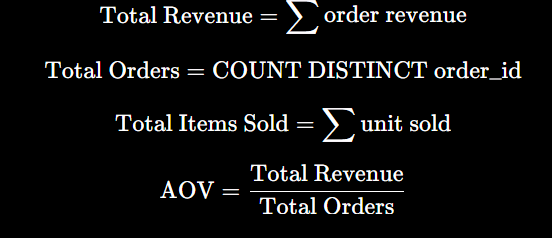

In [218]:
#Penambahan KPI pendukung
average_items_per_order = (
    total_items_sold / total_orders
    if total_orders > 0
    else np.nan
)

kpi_overview = pd.DataFrame({
    'kpi': [
        'Total Revenue',
        'Total Orders',
        'Total Items Sold',
        'Average Order Value',
        'Average Items per Order'
    ],
    'value': [
        total_revenue,
        total_orders,
        total_items_sold,
        average_order_value,
        average_items_per_order
    ],
    'kpi_role': [
        'Main KPI',
        'Main KPI',
        'Main KPI',
        'Main KPI',
        'Supporting KPI'
    ],
    'source': [
        'Order-level raw value',
        'Distinct order_id',
        'Item-level unit_sold',
        'Revenue divided by orders',
        'Items divided by orders'
    ]
})

print("KPI OVERVIEW")
display(kpi_overview)

KPI OVERVIEW


,kpi,value,kpi_role,source
0,Total Revenue,1.322150e+07,Main KPI,Order-level raw value
1,Total Orders,9.647800e+04,Main KPI,Distinct order_id
2,Total Items Sold,1.101970e+05,Main KPI,Item-level unit_sold
3,Average Order Value,1.370416e+02,Main KPI,Revenue divided by orders
4,Average Items per Order,1.142198e+00,Supporting KPI,Items divided by orders


In [219]:
kpi_overview_display = kpi_overview.copy()

kpi_overview_display['formatted_value'] = [
    f"{total_revenue:,.2f}",
    f"{total_orders:,.0f}",
    f"{total_items_sold:,.0f}",
    f"{average_order_value:,.2f}",
    f"{average_items_per_order:,.2f}"
]

kpi_overview_display = kpi_overview_display[
    [
        'kpi',
        'formatted_value',
        'kpi_role',
        'source'
    ]
]

print("FORMATTED KPI OVERVIEW")
display(kpi_overview_display)

FORMATTED KPI OVERVIEW


,kpi,formatted_value,kpi_role,source
0,Total Revenue,"13,221,498.11",Main KPI,Order-level raw value
1,Total Orders,"96,478",Main KPI,Distinct order_id
2,Total Items Sold,"110,197",Main KPI,Item-level unit_sold
3,Average Order Value,137.04,Main KPI,Revenue divided by orders
4,Average Items per Order,1.14,Supporting KPI,Items divided by orders


In [220]:
# Menentukan kolom tanggal yang tersedia
if 'order_purchase_timestamp' in df_kpi_order.columns:
    kpi_date_column = 'order_purchase_timestamp'

elif 'order_date' in df_kpi_order.columns:
    kpi_date_column = 'order_date'

else:
    raise KeyError(
        "Neither 'order_purchase_timestamp' nor "
        "'order_date' is available."
    )

analysis_start_date = df_kpi_order[kpi_date_column].min()
analysis_end_date = df_kpi_order[kpi_date_column].max()

analysis_period = pd.DataFrame({
    'metric': [
        'Analysis Start Date',
        'Analysis End Date',
        'Number of Calendar Days'
    ],
    'value': [
        analysis_start_date,
        analysis_end_date,
        (
            analysis_end_date.normalize()
            - analysis_start_date.normalize()
        ).days + 1
    ]
})

print("ANALYSIS PERIOD")
display(analysis_period)

ANALYSIS PERIOD


,metric,value
0,Analysis Start Date,2016-09-15 00:00:00
1,Analysis End Date,2018-08-29 00:00:00
2,Number of Calendar Days,714


In [221]:
#Validasi anti-double counting
# Rekonsiliasi revenue antara item-level dan order-level
item_level_total_revenue = (
    df_kpi_item['item_revenue'].sum()
)

order_level_total_revenue = (
    df_kpi_order['order_revenue'].sum()
)

# Rekonsiliasi jumlah order
item_level_unique_orders = (
    df_kpi_item['order_id'].nunique()
)

order_level_unique_orders = (
    df_kpi_order['order_id'].nunique()
)

kpi_reconciliation = pd.DataFrame({
    'reconciliation': [
        'Revenue: item vs order level',
        'Unique orders: item vs order level'
    ],
    'item_level_value': [
        item_level_total_revenue,
        item_level_unique_orders
    ],
    'order_level_value': [
        order_level_total_revenue,
        order_level_unique_orders
    ],
    'difference': [
        (
            item_level_total_revenue
            - order_level_total_revenue
        ),
        (
            item_level_unique_orders
            - order_level_unique_orders
        )
    ]
})

print("KPI RECONCILIATION")
display(kpi_reconciliation.round(2))

KPI RECONCILIATION


,reconciliation,item_level_value,order_level_value,difference
0,Revenue: item vs order level,13221498.11,13221498.11,0.0
1,Unique orders: item vs order level,96478.00,96478.00,0.0


In [222]:
#Validasi akhir KPI Overview
kpi_overview_validation = pd.DataFrame({
    'validation': [
        'Order-level order ID is unique',
        'Order count equals dataframe rows',
        'Item and order revenue are reconciled',
        'Item and order coverage are reconciled',
        'Total items equal sum of unit_sold',
        'AOV formula is correct',
        'Total revenue is positive',
        'Total orders are positive',
        'Total items sold are positive'
    ],
    'result': [
        df_kpi_order['order_id'].is_unique,

        total_orders == len(df_kpi_order),

        np.isclose(
            item_level_total_revenue,
            order_level_total_revenue
        ),

        item_level_unique_orders
        == order_level_unique_orders,

        total_items_sold
        == df_kpi_item['unit_sold'].sum(),

        np.isclose(
            average_order_value,
            total_revenue / total_orders
        ),

        total_revenue > 0,

        total_orders > 0,

        total_items_sold > 0
    ]
})

kpi_overview_validation['status'] = np.where(
    kpi_overview_validation['result'],
    'PASS',
    'CHECK'
)

print("KPI OVERVIEW VALIDATION")
display(kpi_overview_validation)

print(
    "\nAll KPI Overview validation checks passed:",
    kpi_overview_validation['result'].all()
)

KPI OVERVIEW VALIDATION


,validation,result,status
0,Order-level order ID is unique,True,PASS
1,Order count equals dataframe rows,True,PASS
2,Item and order revenue are reconciled,True,PASS
3,Item and order coverage are reconciled,True,PASS
4,Total items equal sum of unit_sold,True,PASS
5,AOV formula is correct,True,PASS
6,Total revenue is positive,True,PASS
7,Total orders are positive,True,PASS
8,Total items sold are positive,True,PASS



All KPI Overview validation checks passed: True


## TIME-BASED SALES TREND

Analisis ini mengevaluasi perkembangan Sales Performance Olist berdasarkan waktu menggunakan:

1. Monthly Revenue
2. Monthly Orders
3. Monthly Average Order Value
4. Monthly Items Sold
5. Month-over-Month Growth
6. Annual Sales Summary

In [223]:
# Membuat dataframe khusus analisis tren
df_time_analysis = df_kpi_order.copy()

# Menentukan kolom tanggal yang tersedia
if 'order_purchase_timestamp' in df_time_analysis.columns:
    source_date_column = 'order_purchase_timestamp'

elif 'order_date' in df_time_analysis.columns:
    source_date_column = 'order_date'

else:
    raise KeyError(
        "Tidak ditemukan kolom tanggal untuk analisis waktu."
    )

# Membuat satu nama kolom tanggal yang konsisten
df_time_analysis['analysis_date'] = pd.to_datetime(
    df_time_analysis[source_date_column],
    errors='coerce'
)

# Validasi tanggal
invalid_date_count = (
    df_time_analysis['analysis_date']
    .isnull()
    .sum()
)

print("Date column used:", source_date_column)
print("Invalid analysis dates:", invalid_date_count)

assert invalid_date_count == 0, (
    "Invalid analysis dates were found."
)

# Membuat periode bulanan
df_time_analysis['purchase_month'] = (
    df_time_analysis['analysis_date']
    .dt.to_period('M')
)

# Membuat periode tahunan
df_time_analysis['purchase_year'] = (
    df_time_analysis['analysis_date']
    .dt.year
)

print("Time columns successfully prepared.")

Date column used: order_date
Invalid analysis dates: 0
Time columns successfully prepared.


In [224]:
monthly_sales = (
    df_time_analysis
    .groupby(
        'purchase_month',
        as_index=False
    )
    .agg(
        total_revenue=('order_revenue', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_items_sold=('total_units', 'sum')
    )
)

# AOV bulanan
monthly_sales['average_order_value'] = (
    monthly_sales['total_revenue']
    / monthly_sales['total_orders']
)

# Mengubah Period menjadi timestamp untuk visualisasi
monthly_sales['month_date'] = (
    monthly_sales['purchase_month']
    .dt.to_timestamp()
)

# Mengurutkan data secara kronologis
monthly_sales = (
    monthly_sales
    .sort_values('purchase_month')
    .reset_index(drop=True)
)

print("MONTHLY SALES PERFORMANCE")
display(
    monthly_sales.round({
        'total_revenue': 2,
        'average_order_value': 2
    })
)

MONTHLY SALES PERFORMANCE


,purchase_month,total_revenue,total_orders,total_items_sold,average_order_value,month_date
0,2016-09,134.97,1,3,134.97,2016-09-01
1,2016-10,40325.11,265,313,152.17,2016-10-01
2,2016-12,10.90,1,1,10.90,2016-12-01
3,2017-01,111798.36,750,913,149.06,2017-01-01
4,2017-02,234223.40,1653,1858,141.70,2017-02-01
5,2017-03,359198.85,2546,2897,141.08,2017-03-01
6,2017-04,340669.68,2303,2569,147.92,2017-04-01
7,2017-05,489338.25,3546,4004,138.00,2017-05-01
8,2017-06,421923.37,3135,3489,134.58,2017-06-01
9,2017-07,481604.52,3872,4416,124.38,2017-07-01


In [225]:
# Membuat kalender bulanan lengkap
complete_month_range = pd.period_range(
    start=monthly_sales['purchase_month'].min(),
    end=monthly_sales['purchase_month'].max(),
    freq='M'
)

# Memeriksa bulan yang tidak muncul pada hasil agregasi
missing_transaction_months = complete_month_range.difference(
    monthly_sales['purchase_month']
)

print("Months without recorded transactions:")
print(list(missing_transaction_months))

print(
    "Number of months without transactions:",
    len(missing_transaction_months)
)

Months without recorded transactions:
[Period('2016-11', 'M')]
Number of months without transactions: 1


In [226]:
monthly_sales_complete = (
    monthly_sales
    .set_index('purchase_month')
    .reindex(complete_month_range)
    .rename_axis('purchase_month')
    .reset_index()
)

# Bulan tanpa transaksi diisi nol untuk KPI additive
monthly_sales_complete[
    [
        'total_revenue',
        'total_orders',
        'total_items_sold'
    ]
] = (
    monthly_sales_complete[
        [
            'total_revenue',
            'total_orders',
            'total_items_sold'
        ]
    ]
    .fillna(0)
)

# Menghitung ulang AOV
monthly_sales_complete['average_order_value'] = np.where(
    monthly_sales_complete['total_orders'] > 0,

    monthly_sales_complete['total_revenue']
    / monthly_sales_complete['total_orders'],

    np.nan
)

# Kolom tanggal untuk chart
monthly_sales_complete['month_date'] = (
    monthly_sales_complete['purchase_month']
    .dt.to_timestamp()
)

print("COMPLETE MONTHLY SALES CALENDAR")
display(
    monthly_sales_complete.round({
        'total_revenue': 2,
        'average_order_value': 2
    })
)

COMPLETE MONTHLY SALES CALENDAR


,purchase_month,total_revenue,total_orders,total_items_sold,average_order_value,month_date
0,2016-09,134.97,1.0,3.0,134.97,2016-09-01
1,2016-10,40325.11,265.0,313.0,152.17,2016-10-01
2,2016-11,0.00,0.0,0.0,NaN,2016-11-01
3,2016-12,10.90,1.0,1.0,10.90,2016-12-01
4,2017-01,111798.36,750.0,913.0,149.06,2017-01-01
5,2017-02,234223.40,1653.0,1858.0,141.70,2017-02-01
6,2017-03,359198.85,2546.0,2897.0,141.08,2017-03-01
7,2017-04,340669.68,2303.0,2569.0,147.92,2017-04-01
8,2017-05,489338.25,3546.0,4004.0,138.00,2017-05-01
9,2017-06,421923.37,3135.0,3489.0,134.58,2017-06-01


In [227]:
# Mengambil tanggal transaksi pertama dan terakhir
# Menggunakan analysis_date yang sudah dibuat pada persiapan waktu

first_transaction_date = (
    df_time_analysis['analysis_date'].min()
)

last_transaction_date = (
    df_time_analysis['analysis_date'].max()
)

# Validasi tanggal tersedia
if pd.isna(first_transaction_date):
    raise ValueError(
        "First transaction date is missing."
    )

if pd.isna(last_transaction_date):
    raise ValueError(
        "Last transaction date is missing."
    )

# Mengubah tanggal pertama dan terakhir menjadi periode bulan
first_period = first_transaction_date.to_period('M')
last_period = last_transaction_date.to_period('M')

# Memberikan status periode
monthly_sales_complete['period_status'] = np.where(
    monthly_sales_complete['purchase_month'].isin(
        [first_period, last_period]
    ),
    'Partial Month',
    'Full Month'
)

print("FIRST AND LAST ANALYSIS PERIOD")

display(
    monthly_sales_complete.loc[
        monthly_sales_complete['purchase_month'].isin(
            [first_period, last_period]
        ),
        [
            'purchase_month',
            'total_revenue',
            'total_orders',
            'average_order_value',
            'period_status'
        ]
    ].round(2)
)

FIRST AND LAST ANALYSIS PERIOD


,purchase_month,total_revenue,total_orders,average_order_value,period_status
0,2016-09,134.97,1.0,134.97,Partial Month
23,2018-08,838576.64,6351.0,132.04,Partial Month


In [228]:
# Menetapkan periode utama yang lebih layak dibandingkan
core_start_period = pd.Period('2017-01', freq='M')
core_end_period = pd.Period('2018-07', freq='M')

monthly_trend_core = (
    monthly_sales_complete.loc[
        monthly_sales_complete['purchase_month'].between(
            core_start_period,
            core_end_period
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("CORE TREND ANALYSIS PERIOD")
print(
    "Start period:",
    monthly_trend_core['purchase_month'].min()
)
print(
    "End period  :",
    monthly_trend_core['purchase_month'].max()
)
print(
    "Number of months:",
    len(monthly_trend_core)
)

display(
    monthly_trend_core[
        [
            'purchase_month',
            'total_revenue',
            'total_orders',
            'total_items_sold',
            'average_order_value'
        ]
    ].round(2)
)

CORE TREND ANALYSIS PERIOD
Start period: 2017-01
End period  : 2018-07
Number of months: 19


,purchase_month,total_revenue,total_orders,total_items_sold,average_order_value
0,2017-01,111798.36,750.0,913.0,149.06
1,2017-02,234223.40,1653.0,1858.0,141.70
2,2017-03,359198.85,2546.0,2897.0,141.08
3,2017-04,340669.68,2303.0,2569.0,147.92
4,2017-05,489338.25,3546.0,4004.0,138.00
5,2017-06,421923.37,3135.0,3489.0,134.58
6,2017-07,481604.52,3872.0,4416.0,124.38
7,2017-08,554699.70,4193.0,4797.0,132.29
8,2017-09,607399.67,4150.0,4737.0,146.36
9,2017-10,648247.65,4478.0,5214.0,144.76


In [229]:
# Revenue Growth MoM
monthly_trend_core['revenue_growth_mom_pct'] = (
    monthly_trend_core['total_revenue']
    .pct_change(fill_method=None)
    .mul(100)
)

# Order Growth MoM
monthly_trend_core['order_growth_mom_pct'] = (
    monthly_trend_core['total_orders']
    .pct_change(fill_method=None)
    .mul(100)
)

# Items Growth MoM
monthly_trend_core['items_growth_mom_pct'] = (
    monthly_trend_core['total_items_sold']
    .pct_change(fill_method=None)
    .mul(100)
)

# AOV Growth MoM
monthly_trend_core['aov_growth_mom_pct'] = (
    monthly_trend_core['average_order_value']
    .pct_change(fill_method=None)
    .mul(100)
)

growth_columns = [
    'revenue_growth_mom_pct',
    'order_growth_mom_pct',
    'items_growth_mom_pct',
    'aov_growth_mom_pct'
]

# Membersihkan infinity apabila pembagi bulan sebelumnya nol
monthly_trend_core[growth_columns] = (
    monthly_trend_core[growth_columns]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

print("MONTHLY SALES GROWTH")
display(
    monthly_trend_core[
        [
            'purchase_month',
            'total_revenue',
            'total_orders',
            'total_items_sold',
            'average_order_value',
            'revenue_growth_mom_pct',
            'order_growth_mom_pct',
            'items_growth_mom_pct',
            'aov_growth_mom_pct'
        ]
    ].round(2)
)

MONTHLY SALES GROWTH


,purchase_month,total_revenue,total_orders,total_items_sold,average_order_value,revenue_growth_mom_pct,order_growth_mom_pct,items_growth_mom_pct,aov_growth_mom_pct
0,2017-01,111798.36,750.0,913.0,149.06,NaN,NaN,NaN,NaN
1,2017-02,234223.40,1653.0,1858.0,141.70,109.51,120.40,103.50,-4.94
2,2017-03,359198.85,2546.0,2897.0,141.08,53.36,54.02,55.92,-0.43
3,2017-04,340669.68,2303.0,2569.0,147.92,-5.16,-9.54,-11.32,4.85
4,2017-05,489338.25,3546.0,4004.0,138.00,43.64,53.97,55.86,-6.71
5,2017-06,421923.37,3135.0,3489.0,134.58,-13.78,-11.59,-12.86,-2.47
6,2017-07,481604.52,3872.0,4416.0,124.38,14.15,23.51,26.57,-7.58
7,2017-08,554699.70,4193.0,4797.0,132.29,15.18,8.29,8.63,6.36
8,2017-09,607399.67,4150.0,4737.0,146.36,9.50,-1.03,-1.25,10.64
9,2017-10,648247.65,4478.0,5214.0,144.76,6.73,7.90,10.07,-1.09


In [230]:
# Mengeluarkan bulan pertama karena belum memiliki nilai MoM
valid_mom_months = (
    monthly_trend_core
    .dropna(subset=['revenue_growth_mom_pct'])
    .copy()
)

monthly_growth_extremes = pd.DataFrame({
    'metric': [
        'Highest Revenue Growth MoM',
        'Lowest Revenue Growth MoM',
        'Highest Order Growth MoM',
        'Lowest Order Growth MoM',
        'Highest AOV Growth MoM',
        'Lowest AOV Growth MoM'
    ],
    'month': [
        valid_mom_months.loc[
            valid_mom_months[
                'revenue_growth_mom_pct'
            ].idxmax(),
            'purchase_month'
        ],

        valid_mom_months.loc[
            valid_mom_months[
                'revenue_growth_mom_pct'
            ].idxmin(),
            'purchase_month'
        ],

        valid_mom_months.loc[
            valid_mom_months[
                'order_growth_mom_pct'
            ].idxmax(),
            'purchase_month'
        ],

        valid_mom_months.loc[
            valid_mom_months[
                'order_growth_mom_pct'
            ].idxmin(),
            'purchase_month'
        ],

        valid_mom_months.loc[
            valid_mom_months[
                'aov_growth_mom_pct'
            ].idxmax(),
            'purchase_month'
        ],

        valid_mom_months.loc[
            valid_mom_months[
                'aov_growth_mom_pct'
            ].idxmin(),
            'purchase_month'
        ]
    ],
    'growth_pct': [
        valid_mom_months[
            'revenue_growth_mom_pct'
        ].max(),

        valid_mom_months[
            'revenue_growth_mom_pct'
        ].min(),

        valid_mom_months[
            'order_growth_mom_pct'
        ].max(),

        valid_mom_months[
            'order_growth_mom_pct'
        ].min(),

        valid_mom_months[
            'aov_growth_mom_pct'
        ].max(),

        valid_mom_months[
            'aov_growth_mom_pct'
        ].min()
    ]
})

print("MONTHLY GROWTH EXTREMES")
display(
    monthly_growth_extremes.round({
        'growth_pct': 2
    })
)

MONTHLY GROWTH EXTREMES


,metric,month,growth_pct
0,Highest Revenue Growth MoM,2017-02,109.51
1,Lowest Revenue Growth MoM,2017-12,-26.50
2,Highest Order Growth MoM,2017-02,120.40
3,Lowest Order Growth MoM,2017-12,-24.37
4,Highest AOV Growth MoM,2017-09,10.64
5,Lowest AOV Growth MoM,2017-07,-7.58


In [231]:
monthly_kpi_extremes = pd.DataFrame({
    'metric': [
        'Highest Revenue Month',
        'Lowest Revenue Month',
        'Highest Order Month',
        'Lowest Order Month',
        'Highest Items Sold Month',
        'Lowest Items Sold Month',
        'Highest AOV Month',
        'Lowest AOV Month'
    ],
    'month': [
        monthly_trend_core.loc[
            monthly_trend_core['total_revenue'].idxmax(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core['total_revenue'].idxmin(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core['total_orders'].idxmax(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core['total_orders'].idxmin(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core['total_items_sold'].idxmax(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core['total_items_sold'].idxmin(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core[
                'average_order_value'
            ].idxmax(),
            'purchase_month'
        ],

        monthly_trend_core.loc[
            monthly_trend_core[
                'average_order_value'
            ].idxmin(),
            'purchase_month'
        ]
    ],
    'value': [
        monthly_trend_core['total_revenue'].max(),
        monthly_trend_core['total_revenue'].min(),
        monthly_trend_core['total_orders'].max(),
        monthly_trend_core['total_orders'].min(),
        monthly_trend_core['total_items_sold'].max(),
        monthly_trend_core['total_items_sold'].min(),
        monthly_trend_core['average_order_value'].max(),
        monthly_trend_core['average_order_value'].min()
    ]
})

print("MONTHLY KPI EXTREMES")
display(
    monthly_kpi_extremes.round({
        'value': 2
    })
)

MONTHLY KPI EXTREMES


,metric,month,value
0,Highest Revenue Month,2017-11,987765.37
1,Lowest Revenue Month,2017-01,111798.36
2,Highest Order Month,2017-11,7289.00
3,Lowest Order Month,2017-01,750.00
4,Highest Items Sold Month,2017-11,8475.00
5,Lowest Items Sold Month,2017-01,913.00
6,Highest AOV Month,2017-01,149.06
7,Lowest AOV Month,2017-07,124.38


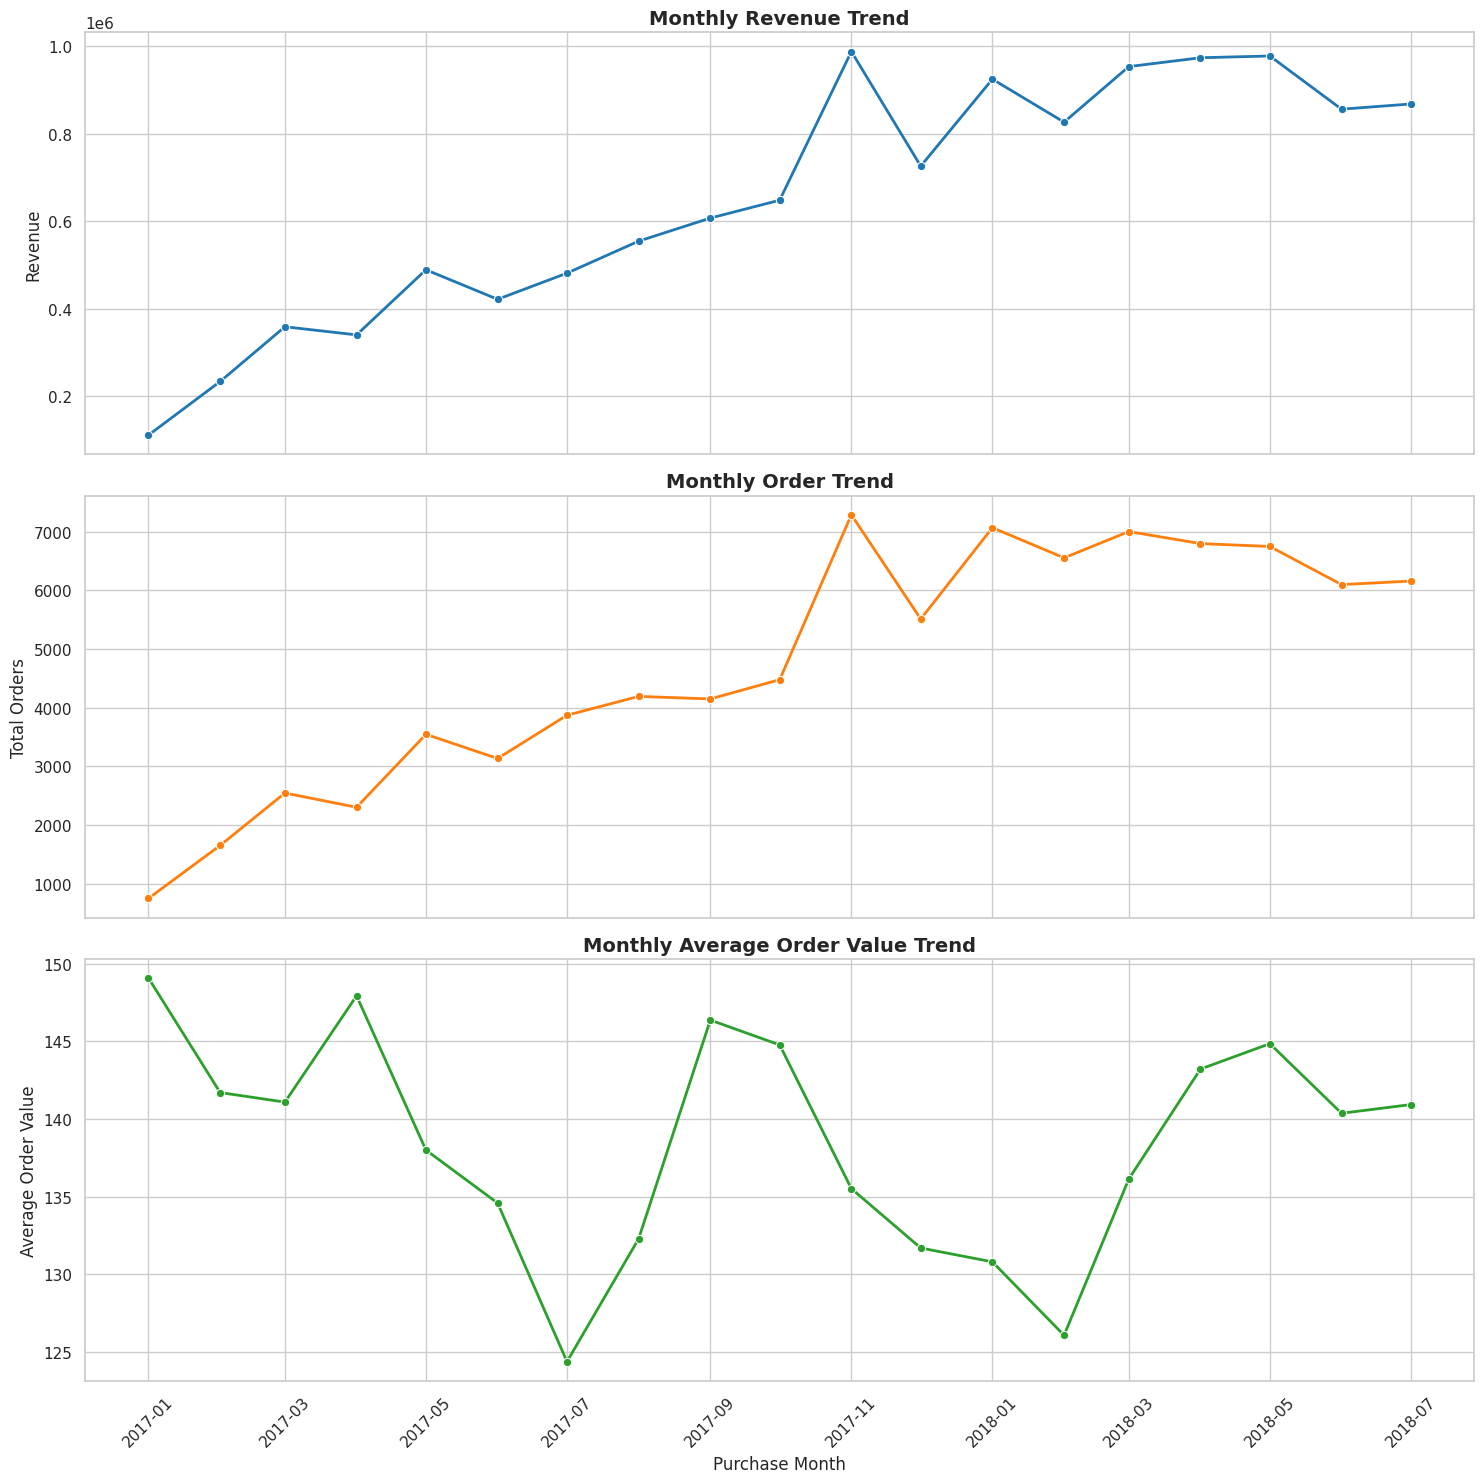

In [232]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 15),
    sharex=True
)

# Monthly Revenue
sns.lineplot(
    data=monthly_trend_core,
    x='month_date',
    y='total_revenue',
    marker='o',
    linewidth=2,
    color='#1f77b4',
    ax=axes[0]
)

axes[0].set_title(
    'Monthly Revenue Trend',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_ylabel('Revenue')
axes[0].set_xlabel('')

# Monthly Orders
sns.lineplot(
    data=monthly_trend_core,
    x='month_date',
    y='total_orders',
    marker='o',
    linewidth=2,
    color='#ff7f0e',
    ax=axes[1]
)

axes[1].set_title(
    'Monthly Order Trend',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_ylabel('Total Orders')
axes[1].set_xlabel('')

# Monthly AOV
sns.lineplot(
    data=monthly_trend_core,
    x='month_date',
    y='average_order_value',
    marker='o',
    linewidth=2,
    color='#2ca02c',
    ax=axes[2]
)

axes[2].set_title(
    'Monthly Average Order Value Trend',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_ylabel('Average Order Value')
axes[2].set_xlabel('Purchase Month')

for axis in axes:
    axis.tick_params(
        axis='x',
        rotation=45
    )

plt.tight_layout()
plt.show()

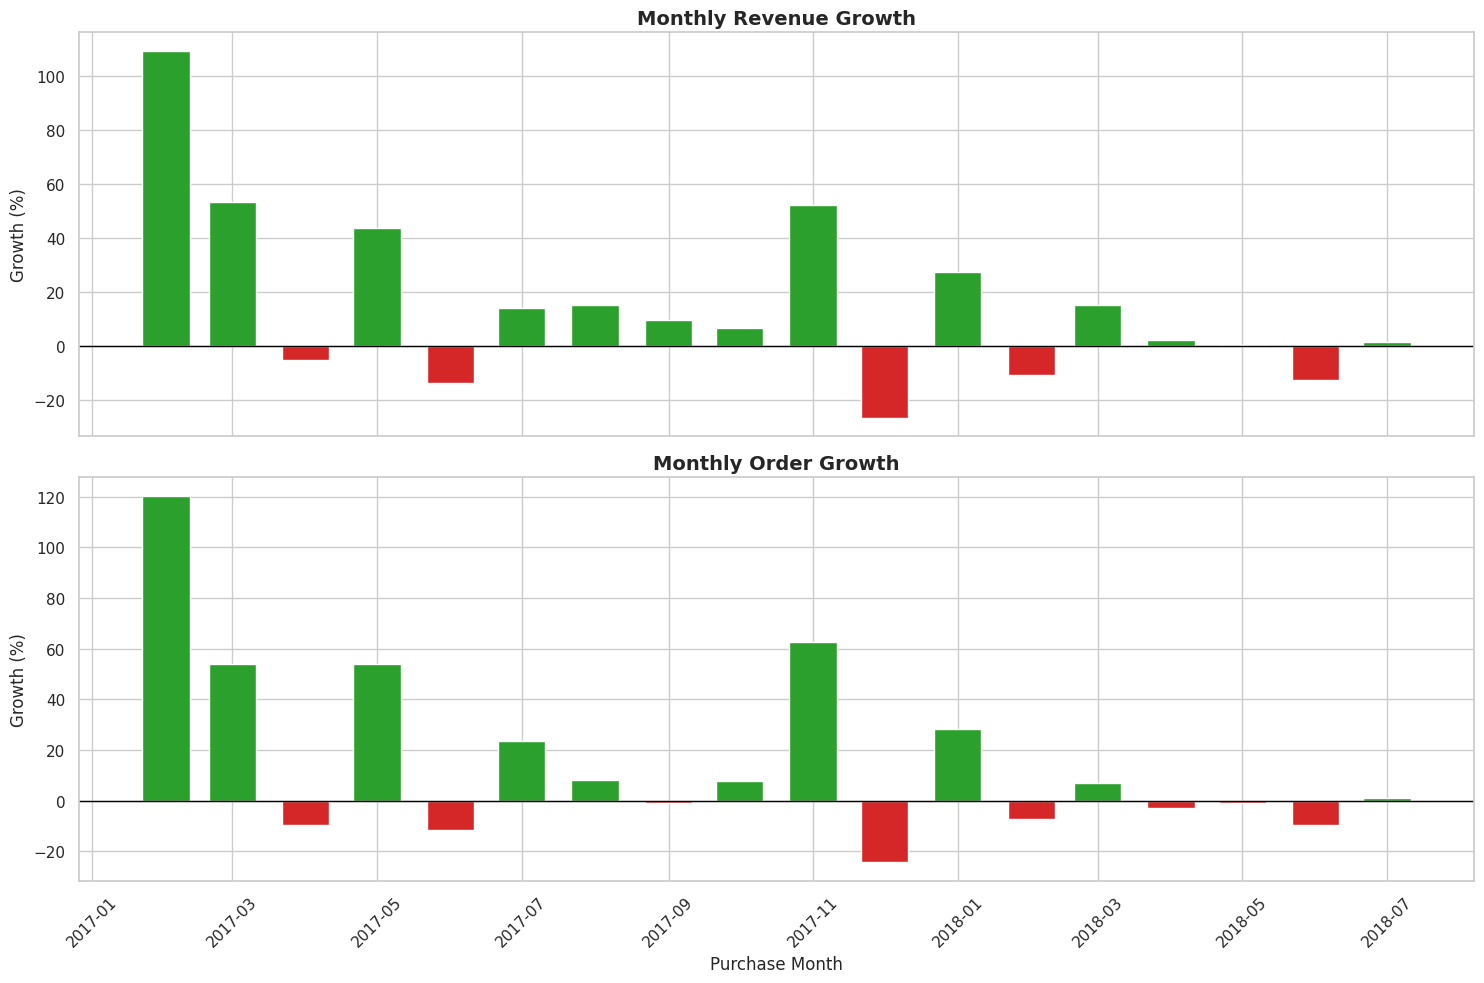

In [233]:
#Visualisasi pertumbuhan MoM
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10),
    sharex=True
)

# Revenue Growth MoM
revenue_growth_colors = np.where(
    monthly_trend_core['revenue_growth_mom_pct'] >= 0,
    '#2ca02c',
    '#d62728'
)

axes[0].bar(
    monthly_trend_core['month_date'],
    monthly_trend_core['revenue_growth_mom_pct'],
    width=20,
    color=revenue_growth_colors
)

axes[0].axhline(
    0,
    color='black',
    linewidth=1
)

axes[0].set_title(
    'Monthly Revenue Growth',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_ylabel('Growth (%)')

# Order Growth MoM
order_growth_colors = np.where(
    monthly_trend_core['order_growth_mom_pct'] >= 0,
    '#2ca02c',
    '#d62728'
)

axes[1].bar(
    monthly_trend_core['month_date'],
    monthly_trend_core['order_growth_mom_pct'],
    width=20,
    color=order_growth_colors
)

axes[1].axhline(
    0,
    color='black',
    linewidth=1
)

axes[1].set_title(
    'Monthly Order Growth',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_ylabel('Growth (%)')
axes[1].set_xlabel('Purchase Month')

for axis in axes:
    axis.tick_params(
        axis='x',
        rotation=45
    )

plt.tight_layout()
plt.show()

In [234]:
#Ringkasan Tahunan
annual_sales_summary = (
    df_time_analysis
    .groupby(
        'purchase_year',
        as_index=False
    )
    .agg(
        total_revenue=('order_revenue', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_items_sold=('total_units', 'sum')
    )
)

annual_sales_summary['average_order_value'] = (
    annual_sales_summary['total_revenue']
    / annual_sales_summary['total_orders']
)

# Menandai kelengkapan tahun
annual_sales_summary['period_status'] = np.where(
    annual_sales_summary['purchase_year'] == 2017,
    'Full Year',
    'Partial Year'
)

print("ANNUAL SALES SUMMARY")
display(
    annual_sales_summary.round({
        'total_revenue': 2,
        'average_order_value': 2
    })
)

ANNUAL SALES SUMMARY


,purchase_year,total_revenue,total_orders,total_items_sold,average_order_value,period_status
0,2016,40470.98,267,317,151.58,Partial Year
1,2017,5962902.01,43428,49556,137.31,Full Year
2,2018,7218125.12,52783,60324,136.75,Partial Year


In [235]:
# Membuat nomor bulan
df_time_analysis['purchase_month_number'] = (
    df_time_analysis['analysis_date']
    .dt.month
)

# Memilih periode yang sebanding
jan_jul_data = df_time_analysis.loc[
    (
        df_time_analysis['purchase_year']
        .isin([2017, 2018])
    )
    &
    (
        df_time_analysis['purchase_month_number']
        .between(1, 7)
    )
].copy()

jan_jul_comparison = (
    jan_jul_data
    .groupby(
        'purchase_year',
        as_index=False
    )
    .agg(
        total_revenue=('order_revenue', 'sum'),
        total_orders=('order_id', 'nunique'),
        total_items_sold=('total_units', 'sum')
    )
)

jan_jul_comparison['average_order_value'] = (
    jan_jul_comparison['total_revenue']
    / jan_jul_comparison['total_orders']
)

comparison_columns = [
    'total_revenue',
    'total_orders',
    'total_items_sold',
    'average_order_value'
]

for column in comparison_columns:
    jan_jul_comparison[f'{column}_growth_pct'] = (
        jan_jul_comparison[column]
        .pct_change(fill_method=None)
        .mul(100)
    )

print("JAN–JUL YEAR-OVER-YEAR COMPARISON")
display(
    jan_jul_comparison.round({
        'total_revenue': 2,
        'average_order_value': 2,
        'total_revenue_growth_pct': 2,
        'total_orders_growth_pct': 2,
        'total_items_sold_growth_pct': 2,
        'average_order_value_growth_pct': 2
    })
)

JAN–JUL YEAR-OVER-YEAR COMPARISON


,purchase_year,total_revenue,total_orders,total_items_sold,average_order_value,total_revenue_growth_pct,total_orders_growth_pct,total_items_sold_growth_pct,average_order_value_growth_pct
0,2017,2438756.43,17805,20146,136.97,NaN,NaN,NaN,NaN
1,2018,6379548.48,46432,53182,137.40,161.59,160.78,163.98,0.31


In [236]:
#Validasi akhir time-based sales trend
time_trend_validation = pd.DataFrame({
    'validation': [
        'Monthly revenue reconciles with KPI overview',
        'Monthly orders reconcile with KPI overview',
        'Monthly items reconcile with KPI overview',
        'Monthly periods are chronologically sorted',
        'Core trend contains 19 months',
        'Core trend starts in January 2017',
        'Core trend ends in July 2018',
        'AOV contains no infinite values',
        'Growth columns contain no infinite values',
        'Two partial months are identified',
        'Order ID remains unique'
    ],
    'result': [
        np.isclose(
            monthly_sales_complete['total_revenue'].sum(),
            total_revenue
        ),

        monthly_sales_complete['total_orders'].sum()
        == total_orders,

        monthly_sales_complete['total_items_sold'].sum()
        == total_items_sold,

        monthly_sales_complete[
            'purchase_month'
        ].is_monotonic_increasing,

        len(monthly_trend_core) == 19,

        monthly_trend_core[
            'purchase_month'
        ].min() == core_start_period,

        monthly_trend_core[
            'purchase_month'
        ].max() == core_end_period,

        ~np.isinf(
            monthly_sales_complete[
                'average_order_value'
            ].dropna()
        ).any(),

        all(
            ~np.isinf(
                monthly_trend_core[column]
                .dropna()
            ).any()
            for column in growth_columns
        ),

        (
            monthly_sales_complete[
                'period_status'
            ] == 'Partial Month'
        ).sum() == 2,

        df_time_analysis['order_id'].is_unique
    ]
})

time_trend_validation['status'] = np.where(
    time_trend_validation['result'],
    'PASS',
    'CHECK'
)

print("TIME-BASED SALES TREND VALIDATION")
display(time_trend_validation)

print(
    "\nAll time trend validation checks passed:",
    time_trend_validation['result'].all()
)

TIME-BASED SALES TREND VALIDATION


,validation,result,status
0,Monthly revenue reconciles with KPI overview,True,PASS
1,Monthly orders reconcile with KPI overview,True,PASS
2,Monthly items reconcile with KPI overview,True,PASS
3,Monthly periods are chronologically sorted,True,PASS
4,Core trend contains 19 months,True,PASS
5,Core trend starts in January 2017,True,PASS
6,Core trend ends in July 2018,True,PASS
7,AOV contains no infinite values,True,PASS
8,Growth columns contain no infinite values,True,PASS
9,Two partial months are identified,True,PASS



All time trend validation checks passed: True


## CATEGORY PERFORMANCE

Analisis ini mengevaluasi kontribusi setiap kategori terhadap Sales Performance melalui:

1. Total Revenue
2. Total Orders Containing Category
3. Total Items Sold
4. Average Category Revenue per Order
5. Average Item Revenue
6. Revenue Contribution
7. Order Penetration

In [237]:
# Membuat dataframe khusus category analysis
df_category_analysis = df_sales_analysis.copy()

# Kolom yang diperlukan
required_category_columns = [
    'order_id',
    'order_item_id',
    'product_id',
    'product_category_name',
    'product_category_name_english',
    'item_revenue',
    'unit_sold'
]

missing_category_columns = [
    column
    for column in required_category_columns
    if column not in df_category_analysis.columns
]

print(
    "Missing category analysis columns:",
    missing_category_columns
)

if missing_category_columns:
    raise KeyError(
        "Category analysis cannot continue. "
        f"Missing columns: {missing_category_columns}"
    )

print("All category analysis columns are available.")

Missing category analysis columns: []
All category analysis columns are available.


In [238]:
# Mengubah menjadi string terlebih dahulu
# untuk mencegah error pada categorical dtype

english_category = (
    df_category_analysis[
        'product_category_name_english'
    ]
    .astype('string')
    .str.strip()
    .replace('', pd.NA)
)

portuguese_category = (
    df_category_analysis[
        'product_category_name'
    ]
    .astype('string')
    .str.strip()
    .replace('', pd.NA)
)

# Prioritas:
# 1. Nama kategori bahasa Inggris
# 2. Nama kategori bahasa Portugis
# 3. Unknown
df_category_analysis['category_name'] = (
    english_category
    .fillna(portuguese_category)
    .fillna('unknown')
)

print("CATEGORY NAME VALIDATION")
print(
    "Missing category_name:",
    df_category_analysis[
        'category_name'
    ].isnull().sum()
)

print(
    "Number of categories:",
    df_category_analysis[
        'category_name'
    ].nunique()
)

display(
    df_category_analysis[
        [
            'product_category_name',
            'product_category_name_english',
            'category_name'
        ]
    ].drop_duplicates().head(20)
)

CATEGORY NAME VALIDATION
Missing category_name: 0
Number of categories: 74


,product_category_name,product_category_name_english,category_name
0,cool_stuff,cool_stuff,cool_stuff
1,pet_shop,pet_shop,pet_shop
2,moveis_decoracao,furniture_decor,furniture_decor
3,perfumaria,perfumery,perfumery
4,ferramentas_jardim,garden_tools,garden_tools
5,utilidades_domesticas,housewares,housewares
6,telefonia,telephony,telephony
8,beleza_saude,health_beauty,health_beauty
9,livros_tecnicos,books_technical,books_technical
11,fashion_bolsas_e_acessorios,fashion_bags_accessories,fashion_bags_accessories


In [239]:
category_numeric_validation = pd.DataFrame({
    'column': [
        'item_revenue',
        'unit_sold'
    ],
    'is_numeric': [
        pd.api.types.is_numeric_dtype(
            df_category_analysis['item_revenue']
        ),
        pd.api.types.is_numeric_dtype(
            df_category_analysis['unit_sold']
        )
    ],
    'missing_count': [
        df_category_analysis[
            'item_revenue'
        ].isnull().sum(),
        df_category_analysis[
            'unit_sold'
        ].isnull().sum()
    ],
    'negative_count': [
        (
            df_category_analysis[
                'item_revenue'
            ] < 0
        ).sum(),
        (
            df_category_analysis[
                'unit_sold'
            ] < 0
        ).sum()
    ]
})

print("CATEGORY NUMERIC VALIDATION")
display(category_numeric_validation)

CATEGORY NUMERIC VALIDATION


,column,is_numeric,missing_count,negative_count
0,item_revenue,True,0,0
1,unit_sold,True,0,0


In [240]:
# Agregasi menjadi satu baris per order dan kategori
df_order_category = (
    df_category_analysis
    .groupby(
        [
            'order_id',
            'category_name'
        ],
        as_index=False,
        observed=True
    )
    .agg(
        category_order_revenue=(
            'item_revenue',
            'sum'
        ),
        category_units=(
            'unit_sold',
            'sum'
        ),
        category_item_lines=(
            'order_item_id',
            'count'
        )
    )
)

print("ORDER-CATEGORY DATAFRAME")
print("Shape:", df_order_category.shape)

print(
    "Duplicate order-category combinations:",
    df_order_category.duplicated(
        subset=[
            'order_id',
            'category_name'
        ]
    ).sum()
)

display(df_order_category.head())

ORDER-CATEGORY DATAFRAME
Shape: (97276, 5)
Duplicate order-category combinations: 0


,order_id,category_name,category_order_revenue,category_units,category_item_lines
0,00010242fe8c5a6d1ba2dd792cb16214,cool_stuff,58.90,1,1
1,00018f77f2f0320c557190d7a144bdd3,pet_shop,239.90,1,1
2,000229ec398224ef6ca0657da4fc703e,furniture_decor,199.00,1,1
3,00024acbcdf0a6daa1e931b038114c75,perfumery,12.99,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,garden_tools,199.90,1,1


In [241]:
#Hitung KPI per kategori
category_performance = (
    df_order_category
    .groupby(
        'category_name',
        as_index=False,
        observed=True
    )
    .agg(
        total_revenue=(
            'category_order_revenue',
            'sum'
        ),
        total_orders=(
            'order_id',
            'nunique'
        ),
        total_items_sold=(
            'category_units',
            'sum'
        )
    )
)

# Rata-rata revenue kategori per order
category_performance[
    'average_category_order_value'
] = (
    category_performance['total_revenue']
    / category_performance['total_orders']
)

# Rata-rata revenue per item
category_performance[
    'average_item_revenue'
] = (
    category_performance['total_revenue']
    / category_performance['total_items_sold']
)

# Kontribusi terhadap total revenue
category_performance[
    'revenue_contribution_pct'
] = (
    category_performance['total_revenue']
    / total_revenue
    * 100
)

# Kontribusi terhadap total items
category_performance[
    'items_contribution_pct'
] = (
    category_performance['total_items_sold']
    / total_items_sold
    * 100
)

# Persentase order yang mengandung kategori
category_performance[
    'order_penetration_pct'
] = (
    category_performance['total_orders']
    / total_orders
    * 100
)

# Ranking berdasarkan revenue
category_performance[
    'revenue_rank'
] = (
    category_performance['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

category_performance = (
    category_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("CATEGORY PERFORMANCE")
display(
    category_performance.round({
        'total_revenue': 2,
        'average_category_order_value': 2,
        'average_item_revenue': 2,
        'revenue_contribution_pct': 2,
        'items_contribution_pct': 2,
        'order_penetration_pct': 2
    })
)

CATEGORY PERFORMANCE


,category_name,total_revenue,total_orders,total_items_sold,average_category_order_value,average_item_revenue,revenue_contribution_pct,items_contribution_pct,order_penetration_pct,revenue_rank
0,health_beauty,1233131.72,8647,9465,142.61,130.28,9.33,8.59,8.96,1
1,watches_gifts,1166176.98,5495,5859,212.23,199.04,8.82,5.32,5.70,2
2,bed_bath_table,1023434.76,9272,10953,110.38,93.44,7.74,9.94,9.61,3
3,sports_leisure,954852.55,7530,8431,126.81,113.25,7.22,7.65,7.80,4
4,computers_accessories,888724.61,6530,7644,136.10,116.26,6.72,6.94,6.77,5
...,...,...,...,...,...,...,...,...,...,...
69,flowers,1110.04,29,33,38.28,33.64,0.01,0.03,0.03,70
70,home_comfort_2,760.27,24,30,31.68,25.34,0.01,0.03,0.02,71
71,cds_dvds_musicals,730.00,12,14,60.83,52.14,0.01,0.01,0.01,72
72,fashion_childrens_clothes,519.95,7,7,74.28,74.28,0.00,0.01,0.01,73


In [242]:
top_10_categories_revenue = (
    category_performance
    .nlargest(
        10,
        'total_revenue'
    )
    .copy()
)

print("TOP 10 CATEGORIES BY REVENUE")

display(
    top_10_categories_revenue[
        [
            'revenue_rank',
            'category_name',
            'total_revenue',
            'total_orders',
            'total_items_sold',
            'average_category_order_value',
            'average_item_revenue',
            'revenue_contribution_pct'
        ]
    ].round({
        'total_revenue': 2,
        'average_category_order_value': 2,
        'average_item_revenue': 2,
        'revenue_contribution_pct': 2
    })
)

TOP 10 CATEGORIES BY REVENUE


,revenue_rank,category_name,total_revenue,total_orders,total_items_sold,average_category_order_value,average_item_revenue,revenue_contribution_pct
0,1,health_beauty,1233131.72,8647,9465,142.61,130.28,9.33
1,2,watches_gifts,1166176.98,5495,5859,212.23,199.04,8.82
2,3,bed_bath_table,1023434.76,9272,10953,110.38,93.44,7.74
3,4,sports_leisure,954852.55,7530,8431,126.81,113.25,7.22
4,5,computers_accessories,888724.61,6530,7644,136.10,116.26,6.72
5,6,furniture_decor,711927.69,6307,8160,112.88,87.25,5.38
6,7,housewares,615628.69,5743,6795,107.20,90.60,4.66
7,8,cool_stuff,610204.10,3559,3718,171.45,164.12,4.62
8,9,auto,578966.65,3810,4140,151.96,139.85,4.38
9,10,toys,471286.48,3804,4030,123.89,116.94,3.56


In [243]:
top_10_categories_orders = (
    category_performance
    .nlargest(
        10,
        'total_orders'
    )
    .copy()
)

top_10_categories_items = (
    category_performance
    .nlargest(
        10,
        'total_items_sold'
    )
    .copy()
)

print("TOP 10 CATEGORIES BY ORDERS")

display(
    top_10_categories_orders[
        [
            'category_name',
            'total_orders',
            'total_revenue',
            'order_penetration_pct'
        ]
    ].round(2)
)

print("\nTOP 10 CATEGORIES BY ITEMS SOLD")

display(
    top_10_categories_items[
        [
            'category_name',
            'total_items_sold',
            'total_revenue',
            'items_contribution_pct'
        ]
    ].round(2)
)

TOP 10 CATEGORIES BY ORDERS


,category_name,total_orders,total_revenue,order_penetration_pct
2,bed_bath_table,9272,1023434.76,9.61
0,health_beauty,8647,1233131.72,8.96
3,sports_leisure,7530,954852.55,7.80
4,computers_accessories,6530,888724.61,6.77
5,furniture_decor,6307,711927.69,6.54
6,housewares,5743,615628.69,5.95
1,watches_gifts,5495,1166176.98,5.70
13,telephony,4093,309860.23,4.24
8,auto,3810,578966.65,3.95
9,toys,3804,471286.48,3.94



TOP 10 CATEGORIES BY ITEMS SOLD


,category_name,total_items_sold,total_revenue,items_contribution_pct
2,bed_bath_table,10953,1023434.76,9.94
0,health_beauty,9465,1233131.72,8.59
3,sports_leisure,8431,954852.55,7.65
5,furniture_decor,8160,711927.69,7.40
4,computers_accessories,7644,888724.61,6.94
6,housewares,6795,615628.69,6.17
1,watches_gifts,5859,1166176.98,5.32
13,telephony,4430,309860.23,4.02
10,garden_tools,4268,470495.28,3.87
8,auto,4140,578966.65,3.76


In [244]:
minimum_category_orders = 100

eligible_category_value = (
    category_performance.loc[
        category_performance['total_orders']
        >= minimum_category_orders
    ]
    .copy()
)

top_10_categories_order_value = (
    eligible_category_value
    .nlargest(
        10,
        'average_category_order_value'
    )
)

print(
    "TOP 10 CATEGORIES BY "
    "AVERAGE CATEGORY ORDER VALUE"
)

print(
    "Minimum category orders:",
    minimum_category_orders
)

display(
    top_10_categories_order_value[
        [
            'category_name',
            'total_orders',
            'total_revenue',
            'average_category_order_value',
            'average_item_revenue'
        ]
    ].round(2)
)

TOP 10 CATEGORIES BY AVERAGE CATEGORY ORDER VALUE
Minimum category orders: 100


,category_name,total_orders,total_revenue,average_category_order_value,average_item_revenue
16,computers,177,218684.14,1235.50,1098.92
26,home_appliances_2,227,107953.95,475.57,467.33
29,agro_industry_and_commerce,177,70566.10,398.68,342.55
18,musical_instruments,611,184315.74,301.66,283.13
19,small_appliances,609,182754.12,300.09,277.74
32,fixed_telephony,212,55315.21,260.92,216.92
39,construction_tools_safety,159,38773.22,243.86,211.88
33,air_conditioning,246,53323.56,216.76,184.51
14,office_furniture,1254,268154.31,213.84,160.76
1,watches_gifts,5495,1166176.98,212.23,199.04


In [245]:
top_5_category_revenue_share = (
    category_performance
    .head(5)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_10_category_revenue_share = (
    category_performance
    .head(10)[
        'revenue_contribution_pct'
    ]
    .sum()
)

category_concentration = pd.DataFrame({
    'metric': [
        'Top 5 Category Revenue Share',
        'Top 10 Category Revenue Share',
        'Remaining Category Revenue Share'
    ],
    'percentage': [
        top_5_category_revenue_share,
        top_10_category_revenue_share,
        100 - top_10_category_revenue_share
    ]
})

print("CATEGORY REVENUE CONCENTRATION")

display(
    category_concentration.round({
        'percentage': 2
    })
)

CATEGORY REVENUE CONCENTRATION


,metric,percentage
0,Top 5 Category Revenue Share,39.83
1,Top 10 Category Revenue Share,62.43
2,Remaining Category Revenue Share,37.57


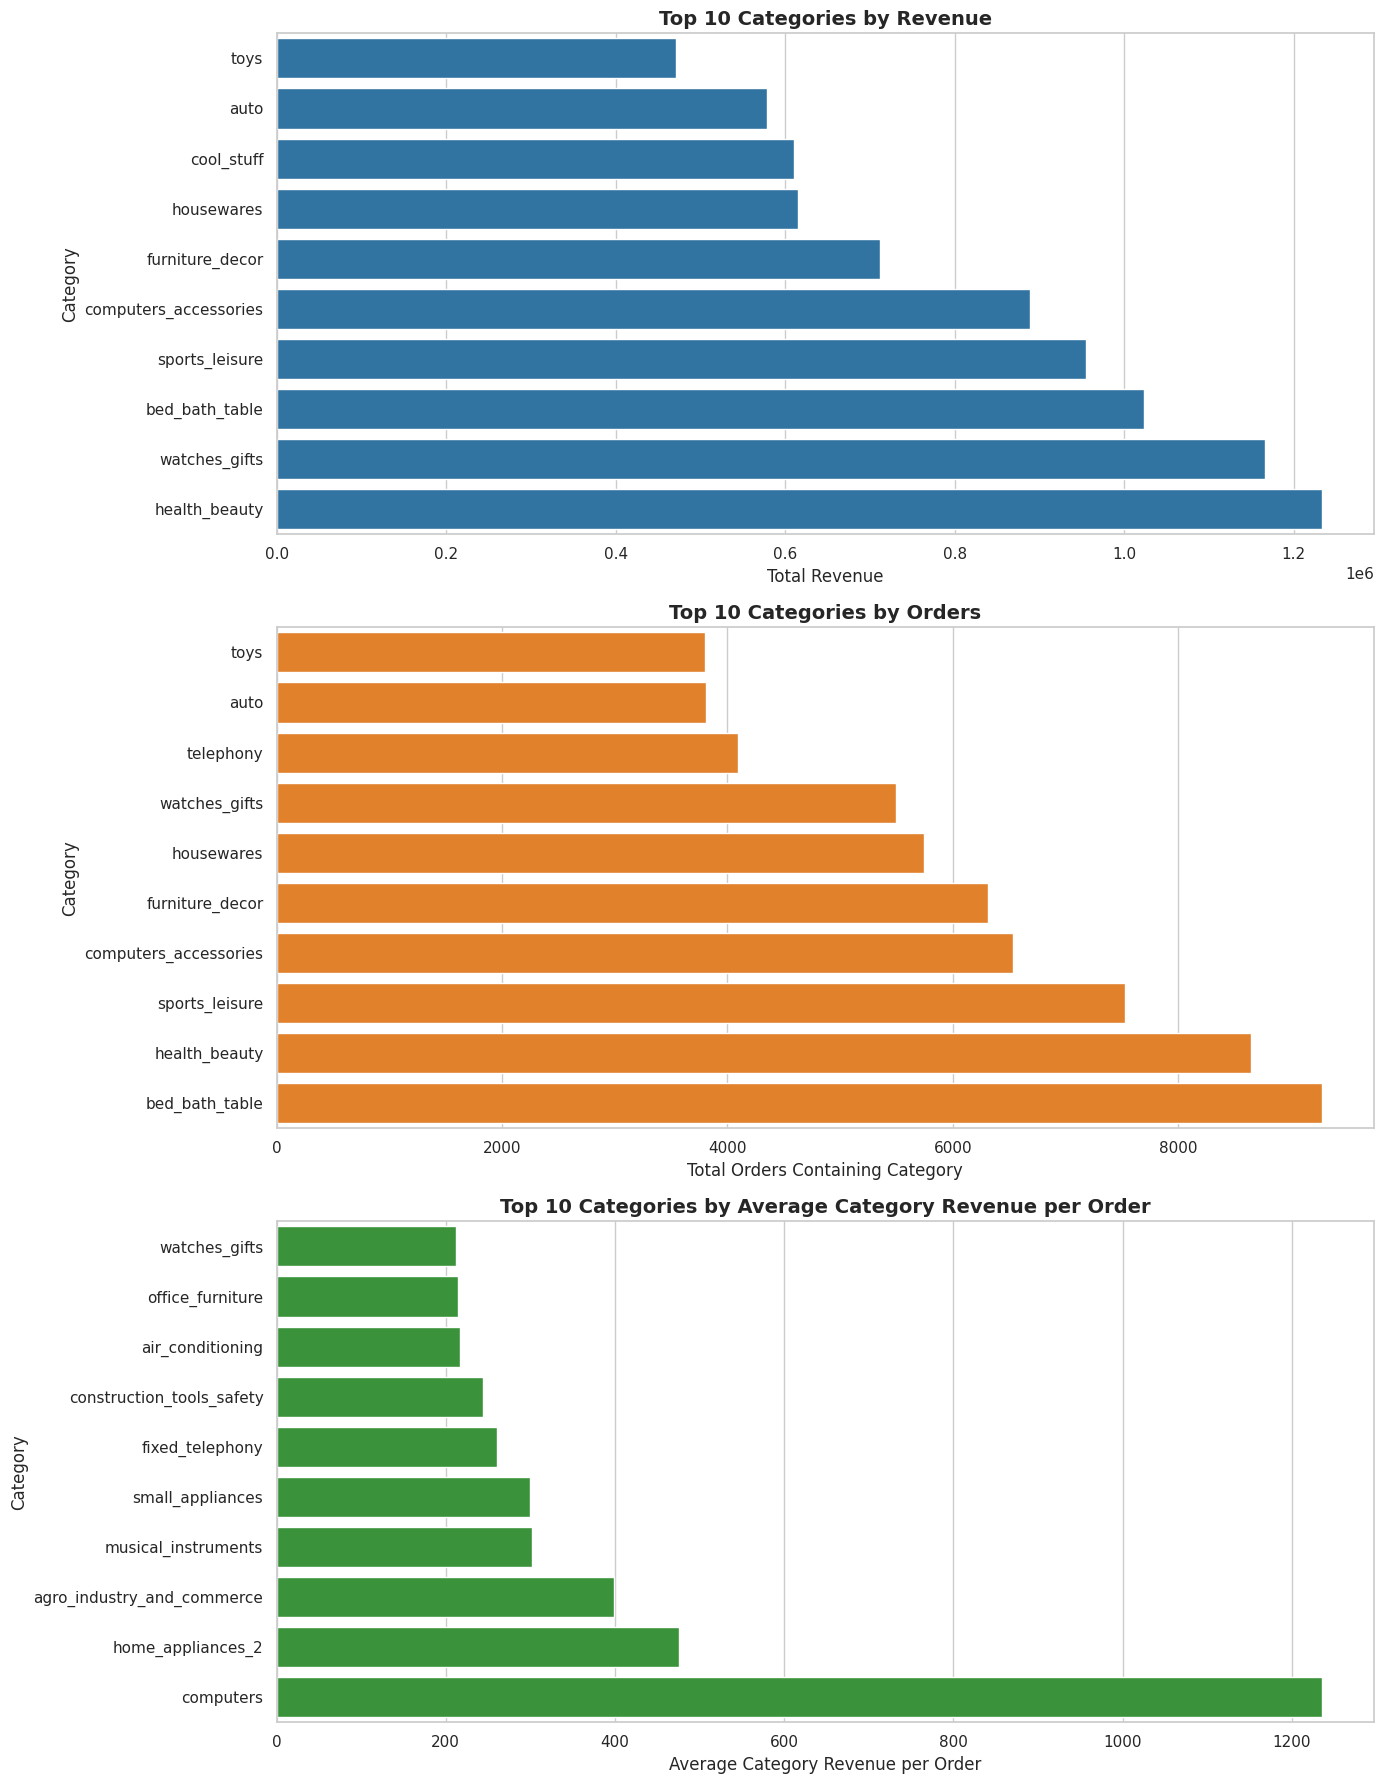

In [246]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 18)
)

# Top revenue
revenue_plot_data = (
    top_10_categories_revenue
    .sort_values(
        'total_revenue',
        ascending=True
    )
)

sns.barplot(
    data=revenue_plot_data,
    x='total_revenue',
    y='category_name',
    color='#1f77b4',
    ax=axes[0]
)

axes[0].set_title(
    'Top 10 Categories by Revenue',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('Category')

# Top orders
orders_plot_data = (
    top_10_categories_orders
    .sort_values(
        'total_orders',
        ascending=True
    )
)

sns.barplot(
    data=orders_plot_data,
    x='total_orders',
    y='category_name',
    color='#ff7f0e',
    ax=axes[1]
)

axes[1].set_title(
    'Top 10 Categories by Orders',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('Total Orders Containing Category')
axes[1].set_ylabel('Category')

# Top average category order value
value_plot_data = (
    top_10_categories_order_value
    .sort_values(
        'average_category_order_value',
        ascending=True
    )
)

sns.barplot(
    data=value_plot_data,
    x='average_category_order_value',
    y='category_name',
    color='#2ca02c',
    ax=axes[2]
)

axes[2].set_title(
    'Top 10 Categories by Average Category Revenue per Order',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_xlabel('Average Category Revenue per Order')
axes[2].set_ylabel('Category')

plt.tight_layout()
plt.show()

In [247]:
#Validasi category performance
category_performance_validation = pd.DataFrame({
    'validation': [
        'Required category columns are available',
        'Category name has no missing values',
        'Order-category key is unique',
        'Category revenue reconciles with KPI overview',
        'Category items reconcile with KPI overview',
        'Revenue contribution sums to 100 percent',
        'Items contribution sums to 100 percent',
        'Category metrics contain no infinite values',
        'All category revenues are non-negative',
        'All category order counts are positive'
    ],
    'result': [
        len(missing_category_columns) == 0,

        df_category_analysis[
            'category_name'
        ].isnull().sum() == 0,

        ~df_order_category.duplicated(
            subset=[
                'order_id',
                'category_name'
            ]
        ).any(),

        np.isclose(
            category_performance[
                'total_revenue'
            ].sum(),
            total_revenue
        ),

        np.isclose(
            category_performance[
                'total_items_sold'
            ].sum(),
            total_items_sold
        ),

        np.isclose(
            category_performance[
                'revenue_contribution_pct'
            ].sum(),
            100
        ),

        np.isclose(
            category_performance[
                'items_contribution_pct'
            ].sum(),
            100
        ),

        ~np.isinf(
            category_performance[
                [
                    'average_category_order_value',
                    'average_item_revenue',
                    'revenue_contribution_pct',
                    'items_contribution_pct',
                    'order_penetration_pct'
                ]
            ]
        ).any().any(),

        category_performance[
            'total_revenue'
        ].ge(0).all(),

        category_performance[
            'total_orders'
        ].gt(0).all()
    ]
})

category_performance_validation['status'] = np.where(
    category_performance_validation['result'],
    'PASS',
    'CHECK'
)

print("CATEGORY PERFORMANCE VALIDATION")
display(category_performance_validation)

print(
    "\nAll Category Performance validation checks passed:",
    category_performance_validation['result'].all()
)

CATEGORY PERFORMANCE VALIDATION


,validation,result,status
0,Required category columns are available,True,PASS
1,Category name has no missing values,True,PASS
2,Order-category key is unique,True,PASS
3,Category revenue reconciles with KPI overview,True,PASS
4,Category items reconcile with KPI overview,True,PASS
5,Revenue contribution sums to 100 percent,True,PASS
6,Items contribution sums to 100 percent,True,PASS
7,Category metrics contain no infinite values,True,PASS
8,All category revenues are non-negative,True,PASS
9,All category order counts are positive,True,PASS



All Category Performance validation checks passed: True


## PRODUCT PERFORMANCE

Analisis ini mengevaluasi performa setiap produk melalui:

1. Total Revenue
2. Total Orders Containing Product
3. Total Units Sold
4. Average Item Revenue
5. Revenue Contribution
6. Unit Contribution
7. Product Revenue Rank
8. Product Concentration

In [248]:
# Menggunakan dataframe kategori yang sudah distandardisasi
df_product_analysis = df_category_analysis.copy()

required_product_columns = [
    'order_id',
    'order_item_id',
    'product_id',
    'category_name',
    'item_revenue',
    'unit_sold'
]

missing_product_columns = [
    column
    for column in required_product_columns
    if column not in df_product_analysis.columns
]

print(
    "Missing product analysis columns:",
    missing_product_columns
)

if missing_product_columns:
    raise KeyError(
        "Product analysis cannot continue. "
        f"Missing columns: {missing_product_columns}"
    )

print("All product analysis columns are available.")

Missing product analysis columns: []
All product analysis columns are available.


In [249]:
#Validasi identitas produk
product_identity_validation = pd.DataFrame({
    'validation': [
        'Product ID has no missing values',
        'Category name has no missing values',
        'Order ID has no missing values',
        'Item revenue has no missing values',
        'Unit sold has no missing values'
    ],
    'result': [
        df_product_analysis[
            'product_id'
        ].isnull().sum() == 0,

        df_product_analysis[
            'category_name'
        ].isnull().sum() == 0,

        df_product_analysis[
            'order_id'
        ].isnull().sum() == 0,

        df_product_analysis[
            'item_revenue'
        ].isnull().sum() == 0,

        df_product_analysis[
            'unit_sold'
        ].isnull().sum() == 0
    ]
})

product_identity_validation['status'] = np.where(
    product_identity_validation['result'],
    'PASS',
    'CHECK'
)

print("PRODUCT IDENTITY VALIDATION")
display(product_identity_validation)

PRODUCT IDENTITY VALIDATION


,validation,result,status
0,Product ID has no missing values,True,PASS
1,Category name has no missing values,True,PASS
2,Order ID has no missing values,True,PASS
3,Item revenue has no missing values,True,PASS
4,Unit sold has no missing values,True,PASS


In [250]:
product_category_count = (
    df_product_analysis
    .groupby(
        'product_id',
        observed=True
    )['category_name']
    .nunique()
)

products_with_multiple_categories = (
    product_category_count[
        product_category_count > 1
    ]
)

print(
    "Products with multiple categories:",
    len(products_with_multiple_categories)
)

if len(products_with_multiple_categories) > 0:
    display(products_with_multiple_categories.head(20))

Products with multiple categories: 0


In [251]:
#Agregasi KPI per produk
product_performance = (
    df_product_analysis
    .groupby(
        [
            'product_id',
            'category_name'
        ],
        as_index=False,
        observed=True
    )
    .agg(
        total_revenue=(
            'item_revenue',
            'sum'
        ),
        total_orders=(
            'order_id',
            'nunique'
        ),
        total_units_sold=(
            'unit_sold',
            'sum'
        ),
        total_item_lines=(
            'order_item_id',
            'count'
        )
    )
)

# Average revenue per unit
product_performance[
    'average_item_revenue'
] = (
    product_performance['total_revenue']
    / product_performance['total_units_sold']
)

# Revenue contribution
product_performance[
    'revenue_contribution_pct'
] = (
    product_performance['total_revenue']
    / total_revenue
    * 100
)

# Unit contribution
product_performance[
    'unit_contribution_pct'
] = (
    product_performance['total_units_sold']
    / total_items_sold
    * 100
)

# Order penetration
product_performance[
    'order_penetration_pct'
] = (
    product_performance['total_orders']
    / total_orders
    * 100
)

# Overall revenue rank
product_performance[
    'revenue_rank'
] = (
    product_performance['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

# Rank produk di dalam kategorinya
product_performance[
    'category_revenue_rank'
] = (
    product_performance
    .groupby(
        'category_name',
        observed=True
    )['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

product_performance = (
    product_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("PRODUCT PERFORMANCE")
print(
    "Number of active products:",
    product_performance['product_id'].nunique()
)

display(product_performance.head(20).round(2))

PRODUCT PERFORMANCE
Number of active products: 32216


,product_id,category_name,total_revenue,total_orders,total_units_sold,total_item_lines,average_item_revenue,revenue_contribution_pct,unit_contribution_pct,order_penetration_pct,revenue_rank,category_revenue_rank
0,bb50f2e236e5eea0100680137654686c,health_beauty,63560.00,186,194,194,327.63,0.48,0.18,0.19,1,1
1,6cdd53843498f92890544667809f1595,health_beauty,53652.30,148,153,153,350.67,0.41,0.14,0.15,2,2
2,d6160fb7873f184099d9bc95e30376af,computers,45949.35,33,33,33,1392.40,0.35,0.03,0.03,3,1
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,45620.56,313,332,332,137.41,0.35,0.30,0.32,4,1
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,42049.66,456,477,477,88.15,0.32,0.43,0.47,5,1
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,40782.80,253,272,272,149.94,0.31,0.25,0.26,6,2
6,25c38557cf793876c5abdd5931f922db,baby,38907.32,38,38,38,1023.88,0.29,0.03,0.04,7,1
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,37733.90,63,63,63,598.95,0.29,0.06,0.07,8,1
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,37454.63,304,321,321,116.68,0.28,0.29,0.32,9,1
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,37104.30,425,520,520,71.35,0.28,0.47,0.44,10,1


In [252]:
top_10_products_revenue = (
    product_performance
    .nlargest(
        10,
        'total_revenue'
    )
    .copy()
)

print("TOP 10 PRODUCTS BY REVENUE")

display(
    top_10_products_revenue[
        [
            'revenue_rank',
            'product_id',
            'category_name',
            'total_revenue',
            'total_orders',
            'total_units_sold',
            'average_item_revenue',
            'revenue_contribution_pct'
        ]
    ].round({
        'total_revenue': 2,
        'average_item_revenue': 2,
        'revenue_contribution_pct': 2
    })
)

TOP 10 PRODUCTS BY REVENUE


,revenue_rank,product_id,category_name,total_revenue,total_orders,total_units_sold,average_item_revenue,revenue_contribution_pct
0,1,bb50f2e236e5eea0100680137654686c,health_beauty,63560.00,186,194,327.63,0.48
1,2,6cdd53843498f92890544667809f1595,health_beauty,53652.30,148,153,350.67,0.41
2,3,d6160fb7873f184099d9bc95e30376af,computers,45949.35,33,33,1392.40,0.35
3,4,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,45620.56,313,332,137.41,0.35
4,5,99a4788cb24856965c36a24e339b6058,bed_bath_table,42049.66,456,477,88.15,0.32
5,6,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,40782.80,253,272,149.94,0.31
6,7,25c38557cf793876c5abdd5931f922db,baby,38907.32,38,38,1023.88,0.29
7,8,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,37733.90,63,63,598.95,0.29
8,9,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,37454.63,304,321,116.68,0.28
9,10,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,37104.30,425,520,71.35,0.28


In [253]:
top_10_products_orders = (
    product_performance
    .nlargest(
        10,
        'total_orders'
    )
    .copy()
)

top_10_products_units = (
    product_performance
    .nlargest(
        10,
        'total_units_sold'
    )
    .copy()
)

print("TOP 10 PRODUCTS BY ORDERS")

display(
    top_10_products_orders[
        [
            'product_id',
            'category_name',
            'total_orders',
            'total_units_sold',
            'total_revenue',
            'order_penetration_pct'
        ]
    ].round(2)
)

print("\nTOP 10 PRODUCTS BY UNITS SOLD")

display(
    top_10_products_units[
        [
            'product_id',
            'category_name',
            'total_units_sold',
            'total_orders',
            'total_revenue',
            'unit_contribution_pct'
        ]
    ].round(2)
)

TOP 10 PRODUCTS BY ORDERS


,product_id,category_name,total_orders,total_units_sold,total_revenue,order_penetration_pct
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,456,477,42049.66,0.47
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,425,520,37104.30,0.44
16,422879e10f46682990de24d770e7f83d,garden_tools,352,484,26577.22,0.36
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,313,332,45620.56,0.32
23,389d119b48cf3043d311335e499d9c6b,garden_tools,309,390,21336.79,0.32
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,304,321,37454.63,0.32
24,368c6c730842d78016ad823897a372db,garden_tools,291,388,21056.80,0.30
25,53759a2ecddad2bb87a079a1f1519f73,garden_tools,287,373,20387.20,0.30
212,154e7e31ebfa092203795c972e5804a6,health_beauty,262,274,6173.26,0.27
20,2b4609f8948be18874494203496bc318,health_beauty,254,255,22277.27,0.26



TOP 10 PRODUCTS BY UNITS SOLD


,product_id,category_name,total_units_sold,total_orders,total_revenue,unit_contribution_pct
9,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,520,425,37104.30,0.47
16,422879e10f46682990de24d770e7f83d,garden_tools,484,352,26577.22,0.44
4,99a4788cb24856965c36a24e339b6058,bed_bath_table,477,456,42049.66,0.43
23,389d119b48cf3043d311335e499d9c6b,garden_tools,390,309,21336.79,0.35
24,368c6c730842d78016ad823897a372db,garden_tools,388,291,21056.80,0.35
25,53759a2ecddad2bb87a079a1f1519f73,garden_tools,373,287,20387.20,0.34
3,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,332,313,45620.56,0.30
8,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,321,304,37454.63,0.29
212,154e7e31ebfa092203795c972e5804a6,health_beauty,274,262,6173.26,0.25
5,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,272,253,40782.80,0.25


In [254]:
minimum_product_units = 20

eligible_high_value_products = (
    product_performance.loc[
        product_performance[
            'total_units_sold'
        ] >= minimum_product_units
    ]
    .copy()
)

top_10_high_value_products = (
    eligible_high_value_products
    .nlargest(
        10,
        'average_item_revenue'
    )
)

print("TOP 10 HIGH-VALUE PRODUCTS")
print(
    "Minimum units sold:",
    minimum_product_units
)

display(
    top_10_high_value_products[
        [
            'product_id',
            'category_name',
            'total_units_sold',
            'total_orders',
            'total_revenue',
            'average_item_revenue'
        ]
    ].round(2)
)

TOP 10 HIGH-VALUE PRODUCTS
Minimum units sold: 20


,product_id,category_name,total_units_sold,total_orders,total_revenue,average_item_revenue
15,588531f8ec37e7d5ff5b7b22ea0488f8,computers,20,19,28291.99,1414.60
2,d6160fb7873f184099d9bc95e30376af,computers,33,33,45949.35,1392.40
6,25c38557cf793876c5abdd5931f922db,baby,38,38,38907.32,1023.88
34,fb01a5fc09b9b9563c2ee41a22f07d54,consoles_games,24,24,16731.79,697.16
14,f819f0c84a64f02d3a5606ca95edd272,watches_gifts,44,44,28451.58,646.63
37,a04087ab6a96ffa041f8a2701a72b616,computers,24,22,15186.00,632.75
7,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,63,37733.90,598.95
32,1a080577618e7fe4d9ddd8fb2b47a964,watches_gifts,32,32,18262.96,570.72
28,1dec4c88c685d5a07bf01dcb0f8bf9f8,auto,35,35,19965.00,570.43
69,af0a99476d96dcc1a1baa7c0d9ff6b9d,health_beauty,22,22,11840.30,538.20


In [255]:
top_10_product_revenue_share = (
    product_performance
    .head(10)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_50_product_revenue_share = (
    product_performance
    .head(50)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_100_product_revenue_share = (
    product_performance
    .head(100)[
        'revenue_contribution_pct'
    ]
    .sum()
)

product_revenue_concentration = pd.DataFrame({
    'product_group': [
        'Top 10 Products',
        'Top 50 Products',
        'Top 100 Products',
        'Remaining Products after Top 100'
    ],
    'revenue_share_pct': [
        top_10_product_revenue_share,
        top_50_product_revenue_share,
        top_100_product_revenue_share,
        100 - top_100_product_revenue_share
    ]
})

print("PRODUCT REVENUE CONCENTRATION")

display(
    product_revenue_concentration.round({
        'revenue_share_pct': 2
    })
)

PRODUCT REVENUE CONCENTRATION


,product_group,revenue_share_pct
0,Top 10 Products,3.35
1,Top 50 Products,9.38
2,Top 100 Products,13.65
3,Remaining Products after Top 100,86.35


In [256]:
product_pareto = (
    product_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

product_pareto[
    'cumulative_revenue_pct'
] = (
    product_pareto[
        'revenue_contribution_pct'
    ]
    .cumsum()
)

products_for_80pct_revenue = (
    (
        product_pareto[
            'cumulative_revenue_pct'
        ] < 80
    ).sum()
    + 1
)

active_product_count = (
    product_pareto['product_id'].nunique()
)

product_share_for_80pct_revenue = (
    products_for_80pct_revenue
    / active_product_count
    * 100
)

product_pareto_summary = pd.DataFrame({
    'metric': [
        'Active Products',
        'Products Required for 80% Revenue',
        'Product Share Required for 80% Revenue'
    ],
    'value': [
        active_product_count,
        products_for_80pct_revenue,
        product_share_for_80pct_revenue
    ]
})

print("PRODUCT PARETO SUMMARY")
display(product_pareto_summary.round(2))

PRODUCT PARETO SUMMARY


,metric,value
0,Active Products,32216.00
1,Products Required for 80% Revenue,8352.00
2,Product Share Required for 80% Revenue,25.93


In [257]:
top_product_per_category = (
    product_performance.loc[
        product_performance[
            'category_revenue_rank'
        ] == 1
    ]
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP PRODUCT IN EACH CATEGORY")

display(
    top_product_per_category[
        [
            'category_name',
            'product_id',
            'total_revenue',
            'total_orders',
            'total_units_sold',
            'revenue_contribution_pct'
        ]
    ].head(20).round(2)
)

TOP PRODUCT IN EACH CATEGORY


,category_name,product_id,total_revenue,total_orders,total_units_sold,revenue_contribution_pct
0,health_beauty,bb50f2e236e5eea0100680137654686c,63560.00,186,194,0.48
1,computers,d6160fb7873f184099d9bc95e30376af,45949.35,33,33,0.35
2,computers_accessories,d1c427060a0f73f6b889a5c7c61f2ac4,45620.56,313,332,0.35
3,bed_bath_table,99a4788cb24856965c36a24e339b6058,42049.66,456,477,0.32
4,baby,25c38557cf793876c5abdd5931f922db,38907.32,38,38,0.29
5,cool_stuff,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,63,0.29
6,watches_gifts,53b36df67ebb7c41585e8d54d6772e08,37454.63,304,321,0.28
7,furniture_decor,aca2eb7d00ea1a7b8ebd4e68314663af,37104.30,425,520,0.28
8,garden_tools,422879e10f46682990de24d770e7f83d,26577.22,352,484,0.20
9,musical_instruments,16c4e87b98a9370a9cbc3a4658a3f45b,25034.00,13,13,0.19


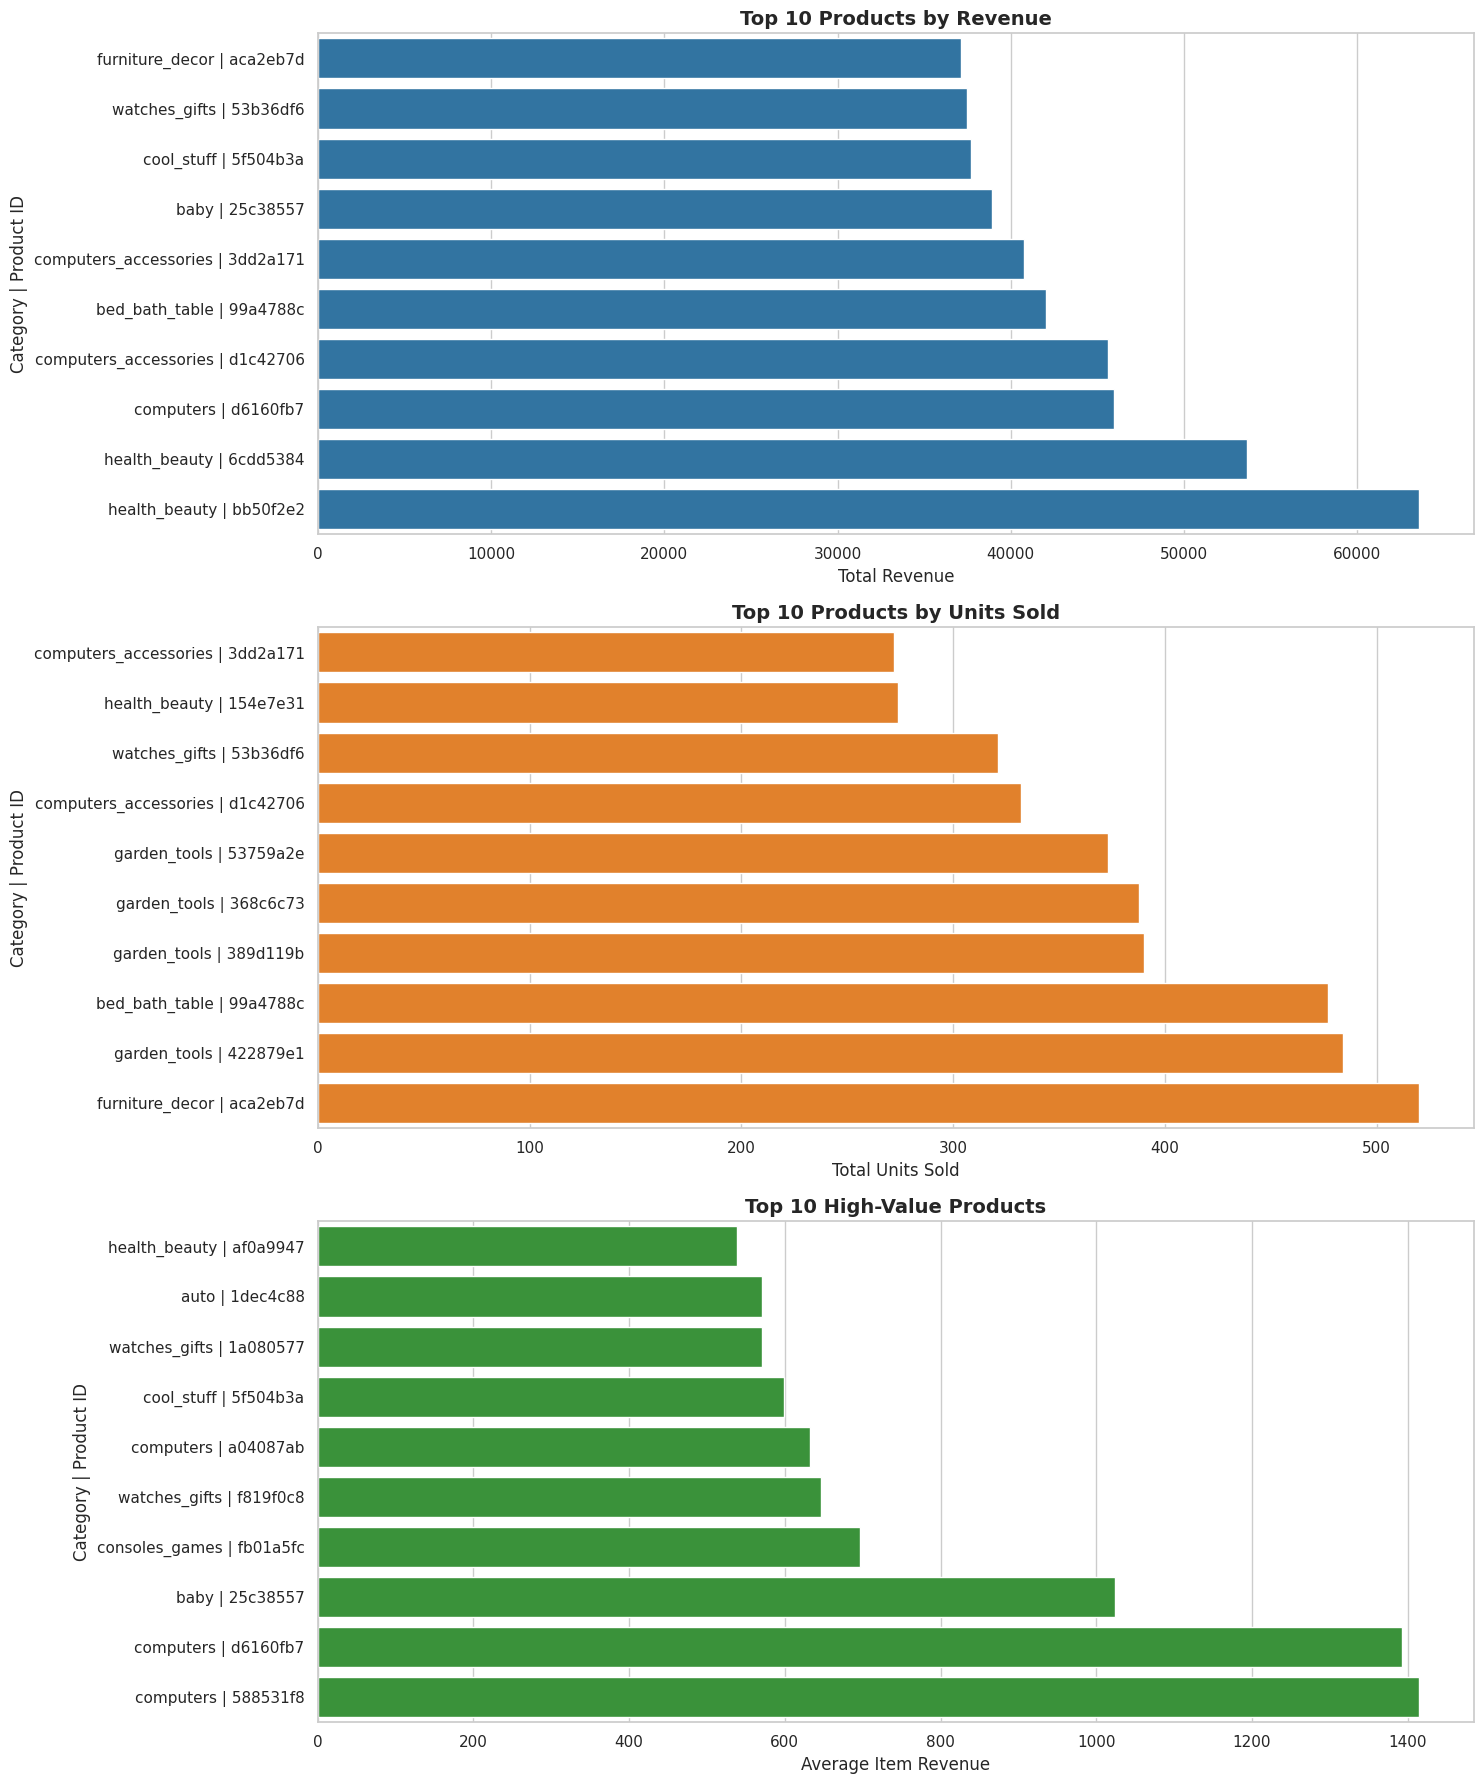

In [258]:
# Membuat label singkat agar grafik mudah dibaca
top_10_products_revenue[
    'product_label'
] = (
    top_10_products_revenue[
        'category_name'
    ]
    + ' | '
    + top_10_products_revenue[
        'product_id'
    ].str[:8]
)

top_10_products_units[
    'product_label'
] = (
    top_10_products_units[
        'category_name'
    ]
    + ' | '
    + top_10_products_units[
        'product_id'
    ].str[:8]
)

top_10_high_value_products[
    'product_label'
] = (
    top_10_high_value_products[
        'category_name'
    ]
    + ' | '
    + top_10_high_value_products[
        'product_id'
    ].str[:8]
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 18)
)

# Top products by revenue
revenue_product_plot = (
    top_10_products_revenue
    .sort_values(
        'total_revenue',
        ascending=True
    )
)

sns.barplot(
    data=revenue_product_plot,
    x='total_revenue',
    y='product_label',
    color='#1f77b4',
    ax=axes[0]
)

axes[0].set_title(
    'Top 10 Products by Revenue',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('Category | Product ID')

# Top products by units
unit_product_plot = (
    top_10_products_units
    .sort_values(
        'total_units_sold',
        ascending=True
    )
)

sns.barplot(
    data=unit_product_plot,
    x='total_units_sold',
    y='product_label',
    color='#ff7f0e',
    ax=axes[1]
)

axes[1].set_title(
    'Top 10 Products by Units Sold',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('Total Units Sold')
axes[1].set_ylabel('Category | Product ID')

# High-value products
high_value_product_plot = (
    top_10_high_value_products
    .sort_values(
        'average_item_revenue',
        ascending=True
    )
)

sns.barplot(
    data=high_value_product_plot,
    x='average_item_revenue',
    y='product_label',
    color='#2ca02c',
    ax=axes[2]
)

axes[2].set_title(
    'Top 10 High-Value Products',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_xlabel('Average Item Revenue')
axes[2].set_ylabel('Category | Product ID')

plt.tight_layout()
plt.show()

In [259]:
#Validasi products performance
product_performance_validation = pd.DataFrame({
    'validation': [
        'Required product columns are available',
        'Product ID has no missing values',
        'Product-category mapping is consistent',
        'Product performance key is unique',
        'Product revenue reconciles with KPI overview',
        'Product units reconcile with KPI overview',
        'Revenue contribution sums to 100 percent',
        'Unit contribution sums to 100 percent',
        'Product metrics contain no infinite values',
        'All product revenues are non-negative',
        'All product order counts are positive',
        'Pareto product count is within valid range'
    ],
    'result': [
        len(missing_product_columns) == 0,

        df_product_analysis[
            'product_id'
        ].isnull().sum() == 0,

        len(products_with_multiple_categories) == 0,

        ~product_performance.duplicated(
            subset=[
                'product_id',
                'category_name'
            ]
        ).any(),

        np.isclose(
            product_performance[
                'total_revenue'
            ].sum(),
            total_revenue
        ),

        np.isclose(
            product_performance[
                'total_units_sold'
            ].sum(),
            total_items_sold
        ),

        np.isclose(
            product_performance[
                'revenue_contribution_pct'
            ].sum(),
            100
        ),

        np.isclose(
            product_performance[
                'unit_contribution_pct'
            ].sum(),
            100
        ),

        ~np.isinf(
            product_performance[
                [
                    'average_item_revenue',
                    'revenue_contribution_pct',
                    'unit_contribution_pct',
                    'order_penetration_pct'
                ]
            ]
        ).any().any(),

        product_performance[
            'total_revenue'
        ].ge(0).all(),

        product_performance[
            'total_orders'
        ].gt(0).all(),

        (
            products_for_80pct_revenue > 0
        )
        and
        (
            products_for_80pct_revenue
            <= active_product_count
        )
    ]
})

product_performance_validation[
    'status'
] = np.where(
    product_performance_validation['result'],
    'PASS',
    'CHECK'
)

print("PRODUCT PERFORMANCE VALIDATION")
display(product_performance_validation)

print(
    "\nAll Product Performance validation checks passed:",
    product_performance_validation[
        'result'
    ].all()
)

PRODUCT PERFORMANCE VALIDATION


,validation,result,status
0,Required product columns are available,True,PASS
1,Product ID has no missing values,True,PASS
2,Product-category mapping is consistent,True,PASS
3,Product performance key is unique,True,PASS
4,Product revenue reconciles with KPI overview,True,PASS
5,Product units reconcile with KPI overview,True,PASS
6,Revenue contribution sums to 100 percent,True,PASS
7,Unit contribution sums to 100 percent,True,PASS
8,Product metrics contain no infinite values,True,PASS
9,All product revenues are non-negative,True,PASS



All Product Performance validation checks passed: True


## SELLER PERFORMANCE

Analisis ini mengevaluasi kontribusi seller terhadap Sales Performance melalui:

1. Total Revenue
2. Total Orders Containing Seller
3. Total Units Sold
4. Average Seller Revenue per Order
5. Average Item Revenue
6. Revenue Contribution
7. Order Penetration
8. Seller Concentration

In [260]:
# Membuat dataframe khusus seller analysis
df_seller_analysis = df_sales_analysis.copy()

required_seller_columns = [
    'order_id',
    'order_item_id',
    'seller_id',
    'seller_state',
    'item_revenue',
    'unit_sold'
]

missing_seller_columns = [
    column
    for column in required_seller_columns
    if column not in df_seller_analysis.columns
]

print(
    "Missing seller analysis columns:",
    missing_seller_columns
)

if missing_seller_columns:
    raise KeyError(
        "Seller analysis cannot continue. "
        f"Missing columns: {missing_seller_columns}"
    )

print("All seller analysis columns are available.")

Missing seller analysis columns: []
All seller analysis columns are available.


In [261]:
# Mengubah state menjadi string agar aman
# jika sebelumnya memiliki categorical dtype
df_seller_analysis['seller_state_clean'] = (
    df_seller_analysis['seller_state']
    .astype('string')
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
    .fillna('UNKNOWN')
)

print("SELLER STATE VALIDATION")

print(
    "Missing seller_state_clean:",
    df_seller_analysis[
        'seller_state_clean'
    ].isnull().sum()
)

print(
    "Number of seller states:",
    df_seller_analysis[
        'seller_state_clean'
    ].nunique()
)

print(
    "Unknown seller states:",
    (
        df_seller_analysis[
            'seller_state_clean'
        ] == 'UNKNOWN'
    ).sum()
)

display(
    df_seller_analysis[
        [
            'seller_state',
            'seller_state_clean'
        ]
    ]
    .drop_duplicates()
    .sort_values('seller_state_clean')
)

SELLER STATE VALIDATION
Missing seller_state_clean: 0
Number of seller states: 22
Unknown seller states: 0


,seller_state,seller_state_clean
44979,AM,AM
283,BA,BA
499,CE,CE
42,DF,DF
174,ES,ES
102,GO,GO
107,MA,MA
2,MG,MG
5446,MS,MS
461,MT,MT


In [262]:
seller_state_count = (
    df_seller_analysis
    .groupby(
        'seller_id',
        observed=True
    )['seller_state_clean']
    .nunique()
)

sellers_with_multiple_states = (
    seller_state_count[
        seller_state_count > 1
    ]
)

print(
    "Sellers with multiple states:",
    len(sellers_with_multiple_states)
)

if len(sellers_with_multiple_states) > 0:
    display(
        sellers_with_multiple_states.head(20)
    )

Sellers with multiple states: 0


In [263]:
# Satu baris mewakili satu seller dalam satu order
df_order_seller = (
    df_seller_analysis
    .groupby(
        [
            'order_id',
            'seller_id',
            'seller_state_clean'
        ],
        as_index=False,
        observed=True
    )
    .agg(
        seller_order_revenue=(
            'item_revenue',
            'sum'
        ),
        seller_units=(
            'unit_sold',
            'sum'
        ),
        seller_item_lines=(
            'order_item_id',
            'count'
        )
    )
)

print("ORDER-SELLER DATAFRAME")
print("Shape:", df_order_seller.shape)

print(
    "Duplicate order-seller combinations:",
    df_order_seller.duplicated(
        subset=[
            'order_id',
            'seller_id'
        ]
    ).sum()
)

display(df_order_seller.head())

ORDER-SELLER DATAFRAME
Shape: (97819, 6)
Duplicate order-seller combinations: 0


,order_id,seller_id,seller_state_clean,seller_order_revenue,seller_units,seller_item_lines
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,SP,58.90,1,1
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,SP,239.90,1,1
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,MG,199.00,1,1
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,SP,12.99,1,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,PR,199.90,1,1


In [264]:
seller_performance = (
    df_order_seller
    .groupby(
        [
            'seller_id',
            'seller_state_clean'
        ],
        as_index=False,
        observed=True
    )
    .agg(
        total_revenue=(
            'seller_order_revenue',
            'sum'
        ),
        total_orders=(
            'order_id',
            'nunique'
        ),
        total_units_sold=(
            'seller_units',
            'sum'
        )
    )
)

# Rata-rata revenue seller dalam setiap order
seller_performance[
    'average_seller_order_value'
] = (
    seller_performance['total_revenue']
    / seller_performance['total_orders']
)

# Rata-rata revenue per unit
seller_performance[
    'average_item_revenue'
] = (
    seller_performance['total_revenue']
    / seller_performance['total_units_sold']
)

# Kontribusi revenue
seller_performance[
    'revenue_contribution_pct'
] = (
    seller_performance['total_revenue']
    / total_revenue
    * 100
)

# Kontribusi unit
seller_performance[
    'unit_contribution_pct'
] = (
    seller_performance['total_units_sold']
    / total_items_sold
    * 100
)

# Order penetration
seller_performance[
    'order_penetration_pct'
] = (
    seller_performance['total_orders']
    / total_orders
    * 100
)

# Ranking revenue keseluruhan
seller_performance[
    'revenue_rank'
] = (
    seller_performance['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

# Ranking seller dalam state
seller_performance[
    'state_revenue_rank'
] = (
    seller_performance
    .groupby(
        'seller_state_clean',
        observed=True
    )['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

seller_performance = (
    seller_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("SELLER PERFORMANCE")

print(
    "Number of active sellers:",
    seller_performance[
        'seller_id'
    ].nunique()
)

display(
    seller_performance
    .head(20)
    .round(2)
)

SELLER PERFORMANCE
Number of active sellers: 2970


,seller_id,seller_state_clean,total_revenue,total_orders,total_units_sold,average_seller_order_value,average_item_revenue,revenue_contribution_pct,unit_contribution_pct,order_penetration_pct,revenue_rank,state_revenue_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,226987.93,1124,1148,201.95,197.72,1.72,1.04,1.17,1,1
1,53243585a1d6dc2643021fd1853d8905,BA,217940.44,348,400,626.27,544.85,1.65,0.36,0.36,2,1
2,4a3ca9315b744ce9f8e9374361493884,SP,196882.12,1772,1949,111.11,101.02,1.49,1.77,1.84,3,2
3,fa1c13f2614d7b5c4749cbc52fecda94,SP,190917.14,578,579,330.31,329.74,1.44,0.53,0.60,4,3
4,7c67e1448b00f6e969d365cea6b010ab,SP,186570.05,973,1355,191.75,137.69,1.41,1.23,1.01,5,4
5,7e93a43ef30c4f03f38b393420bc753a,SP,165981.49,319,322,520.32,515.47,1.26,0.29,0.33,6,5
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,159816.87,1311,1548,121.90,103.24,1.21,1.40,1.36,7,6
7,7a67c85e85bb2ce8582c35f2203ad736,SP,139658.69,1145,1155,121.97,120.92,1.06,1.05,1.19,8,7
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,138208.56,910,1420,151.88,97.33,1.05,1.29,0.94,9,8
9,955fee9216a65b617aa5c0531780ce60,SP,131836.71,1261,1472,104.55,89.56,1.00,1.34,1.31,10,9


In [265]:
top_10_sellers_revenue = (
    seller_performance
    .nlargest(
        10,
        'total_revenue'
    )
    .copy()
)

print("TOP 10 SELLERS BY REVENUE")

display(
    top_10_sellers_revenue[
        [
            'revenue_rank',
            'seller_id',
            'seller_state_clean',
            'total_revenue',
            'total_orders',
            'total_units_sold',
            'average_seller_order_value',
            'revenue_contribution_pct'
        ]
    ].round({
        'total_revenue': 2,
        'average_seller_order_value': 2,
        'revenue_contribution_pct': 2
    })
)

TOP 10 SELLERS BY REVENUE


,revenue_rank,seller_id,seller_state_clean,total_revenue,total_orders,total_units_sold,average_seller_order_value,revenue_contribution_pct
0,1,4869f7a5dfa277a7dca6462dcf3b52b2,SP,226987.93,1124,1148,201.95,1.72
1,2,53243585a1d6dc2643021fd1853d8905,BA,217940.44,348,400,626.27,1.65
2,3,4a3ca9315b744ce9f8e9374361493884,SP,196882.12,1772,1949,111.11,1.49
3,4,fa1c13f2614d7b5c4749cbc52fecda94,SP,190917.14,578,579,330.31,1.44
4,5,7c67e1448b00f6e969d365cea6b010ab,SP,186570.05,973,1355,191.75,1.41
5,6,7e93a43ef30c4f03f38b393420bc753a,SP,165981.49,319,322,520.32,1.26
6,7,da8622b14eb17ae2831f4ac5b9dab84a,SP,159816.87,1311,1548,121.90,1.21
7,8,7a67c85e85bb2ce8582c35f2203ad736,SP,139658.69,1145,1155,121.97,1.06
8,9,1025f0e2d44d7041d6cf58b6550e0bfa,SP,138208.56,910,1420,151.88,1.05
9,10,955fee9216a65b617aa5c0531780ce60,SP,131836.71,1261,1472,104.55,1.00


In [266]:
top_10_sellers_orders = (
    seller_performance
    .nlargest(
        10,
        'total_orders'
    )
    .copy()
)

top_10_sellers_units = (
    seller_performance
    .nlargest(
        10,
        'total_units_sold'
    )
    .copy()
)

print("TOP 10 SELLERS BY ORDERS")

display(
    top_10_sellers_orders[
        [
            'seller_id',
            'seller_state_clean',
            'total_orders',
            'total_units_sold',
            'total_revenue',
            'order_penetration_pct'
        ]
    ].round(2)
)

print("\nTOP 10 SELLERS BY UNITS SOLD")

display(
    top_10_sellers_units[
        [
            'seller_id',
            'seller_state_clean',
            'total_units_sold',
            'total_orders',
            'total_revenue',
            'unit_contribution_pct'
        ]
    ].round(2)
)

TOP 10 SELLERS BY ORDERS


,seller_id,seller_state_clean,total_orders,total_units_sold,total_revenue,order_penetration_pct
11,6560211a19b47992c3666cc44a7e94c0,SP,1819,1996,120702.83,1.89
2,4a3ca9315b744ce9f8e9374361493884,SP,1772,1949,196882.12,1.84
16,cc419e0650a3c5ba77189a1882b7556a,SP,1651,1719,101090.96,1.71
15,1f50f920176fa81dab994f9023523100,SP,1399,1926,106655.71,1.45
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1311,1548,159816.87,1.36
9,955fee9216a65b617aa5c0531780ce60,SP,1261,1472,131836.71,1.31
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1145,1155,139658.69,1.19
62,ea8482cd71df3c1969d7b9473ff13abc,SP,1132,1188,36696.76,1.17
0,4869f7a5dfa277a7dca6462dcf3b52b2,SP,1124,1148,226987.93,1.17
18,3d871de0142ce09b7081e2b9d1733cb1,SP,1064,1131,93407.40,1.10



TOP 10 SELLERS BY UNITS SOLD


,seller_id,seller_state_clean,total_units_sold,total_orders,total_revenue,unit_contribution_pct
11,6560211a19b47992c3666cc44a7e94c0,SP,1996,1819,120702.83,1.81
2,4a3ca9315b744ce9f8e9374361493884,SP,1949,1772,196882.12,1.77
15,1f50f920176fa81dab994f9023523100,SP,1926,1399,106655.71,1.75
16,cc419e0650a3c5ba77189a1882b7556a,SP,1719,1651,101090.96,1.56
6,da8622b14eb17ae2831f4ac5b9dab84a,SP,1548,1311,159816.87,1.40
9,955fee9216a65b617aa5c0531780ce60,SP,1472,1261,131836.71,1.34
8,1025f0e2d44d7041d6cf58b6550e0bfa,SP,1420,910,138208.56,1.29
4,7c67e1448b00f6e969d365cea6b010ab,SP,1355,973,186570.05,1.23
62,ea8482cd71df3c1969d7b9473ff13abc,SP,1188,1132,36696.76,1.08
7,7a67c85e85bb2ce8582c35f2203ad736,SP,1155,1145,139658.69,1.05


In [267]:
minimum_seller_orders = 50

eligible_high_value_sellers = (
    seller_performance.loc[
        seller_performance[
            'total_orders'
        ] >= minimum_seller_orders
    ]
    .copy()
)

top_10_high_value_sellers = (
    eligible_high_value_sellers
    .nlargest(
        10,
        'average_seller_order_value'
    )
    .copy()
)

print("TOP 10 HIGH-VALUE SELLERS")

print(
    "Minimum seller orders:",
    minimum_seller_orders
)

display(
    top_10_high_value_sellers[
        [
            'seller_id',
            'seller_state_clean',
            'total_orders',
            'total_units_sold',
            'total_revenue',
            'average_seller_order_value',
            'average_item_revenue'
        ]
    ].round(2)
)

TOP 10 HIGH-VALUE SELLERS
Minimum seller orders: 50


,seller_id,seller_state_clean,total_orders,total_units_sold,total_revenue,average_seller_order_value,average_item_revenue
35,e882b2a25a10b9c057cc49695f222c19,RJ,57,58,51057.54,895.75,880.30
39,17f51e7198701186712e53a39c564617,SP,56,61,48019.00,857.48,787.20
41,966cb4760537b1404caedd472cc610a5,SP,67,67,45928.26,685.50,685.50
25,04308b1ee57b6625f47df1d56f00eedf,SC,92,92,58991.80,641.22,641.22
1,53243585a1d6dc2643021fd1853d8905,BA,348,400,217940.44,626.27,544.85
55,834f3294fba9f932f56edc879193f925,SP,66,66,39907.50,604.66,604.66
78,7681ef142fd2c19048da7430856b5588,SP,58,76,31211.81,538.13,410.68
48,eeb6de78f79159600292e314a77cbd18,SC,82,83,43510.84,530.62,524.23
5,7e93a43ef30c4f03f38b393420bc753a,SP,319,322,165981.49,520.32,515.47
57,712e6ed8aa4aa1fa65dab41fed5737e4,SC,77,85,39385.00,511.49,463.35


In [268]:
top_10_seller_revenue_share = (
    seller_performance
    .head(10)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_50_seller_revenue_share = (
    seller_performance
    .head(50)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_100_seller_revenue_share = (
    seller_performance
    .head(100)[
        'revenue_contribution_pct'
    ]
    .sum()
)

seller_revenue_concentration = pd.DataFrame({
    'seller_group': [
        'Top 10 Sellers',
        'Top 50 Sellers',
        'Top 100 Sellers',
        'Remaining Sellers after Top 100'
    ],
    'revenue_share_pct': [
        top_10_seller_revenue_share,
        top_50_seller_revenue_share,
        top_100_seller_revenue_share,
        100 - top_100_seller_revenue_share
    ]
})

print("SELLER REVENUE CONCENTRATION")

display(
    seller_revenue_concentration.round({
        'revenue_share_pct': 2
    })
)

SELLER REVENUE CONCENTRATION


,seller_group,revenue_share_pct
0,Top 10 Sellers,13.27
1,Top 50 Sellers,33.20
2,Top 100 Sellers,45.52
3,Remaining Sellers after Top 100,54.48


In [269]:
seller_pareto = (
    seller_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

seller_pareto[
    'cumulative_revenue_pct'
] = (
    seller_pareto[
        'revenue_contribution_pct'
    ]
    .cumsum()
)

sellers_for_80pct_revenue = (
    (
        seller_pareto[
            'cumulative_revenue_pct'
        ] < 80
    ).sum()
    + 1
)

active_seller_count = (
    seller_pareto[
        'seller_id'
    ].nunique()
)

seller_share_for_80pct_revenue = (
    sellers_for_80pct_revenue
    / active_seller_count
    * 100
)

seller_pareto_summary = pd.DataFrame({
    'metric': [
        'Active Sellers',
        'Sellers Required for 80% Revenue',
        'Seller Share Required for 80% Revenue'
    ],
    'value': [
        active_seller_count,
        sellers_for_80pct_revenue,
        seller_share_for_80pct_revenue
    ]
})

print("SELLER PARETO SUMMARY")
display(seller_pareto_summary.round(2))

SELLER PARETO SUMMARY


,metric,value
0,Active Sellers,2970.00
1,Sellers Required for 80% Revenue,533.00
2,Seller Share Required for 80% Revenue,17.95


In [270]:
top_seller_per_state = (
    seller_performance.loc[
        seller_performance[
            'state_revenue_rank'
        ] == 1
    ]
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP SELLER IN EACH STATE")

display(
    top_seller_per_state[
        [
            'seller_state_clean',
            'seller_id',
            'total_revenue',
            'total_orders',
            'total_units_sold',
            'revenue_contribution_pct'
        ]
    ].round(2)
)

TOP SELLER IN EACH STATE


,seller_state_clean,seller_id,total_revenue,total_orders,total_units_sold,revenue_contribution_pct
0,SP,4869f7a5dfa277a7dca6462dcf3b52b2,226987.93,1124,1148,1.72
1,BA,53243585a1d6dc2643021fd1853d8905,217940.44,348,400,1.65
2,RJ,46dc3b2cc0980fb8ec44634e21d2718e,122811.38,503,523,0.93
3,MG,a1043bafd471dff536d0c462352beb48,99309.23,702,752,0.75
4,PR,ccc4bbb5f32a6ab2b7066a4130f114e3,72926.72,184,189,0.55
5,SC,04308b1ee57b6625f47df1d56f00eedf,58991.80,92,92,0.45
6,PE,de722cd6dad950a92b7d4f82673f8833,55126.30,337,377,0.42
7,MA,06a2c3af7b3aee5d69171b0e14f0ee87,36097.98,389,402,0.27
8,RS,87142160b41353c4e5fca2360caf6f92,31095.98,305,339,0.24
9,ES,001cca7ae9ae17fb1caed9dfb1094831,24487.03,195,234,0.19


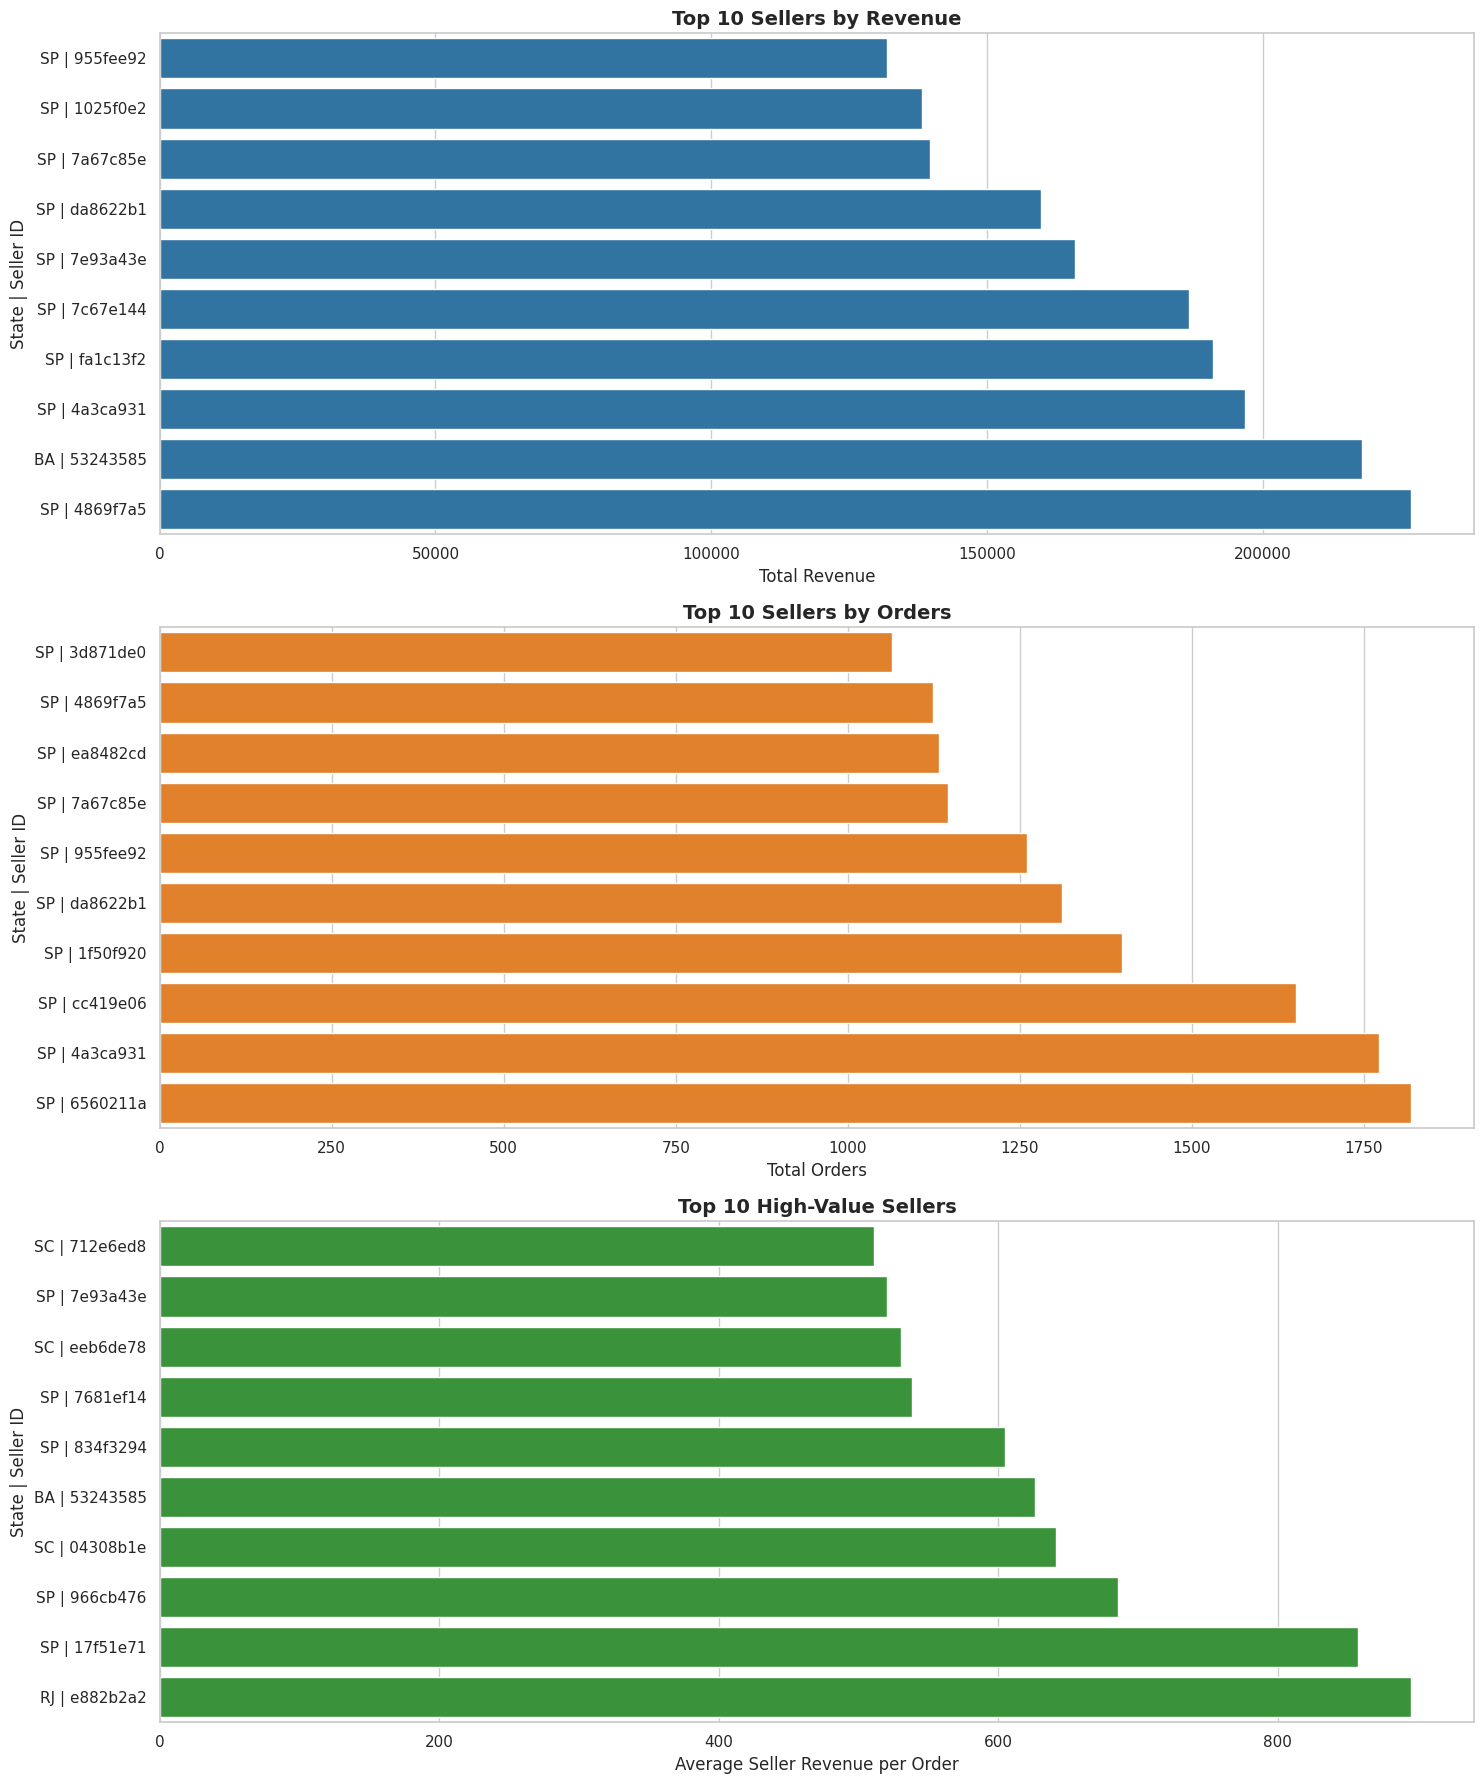

In [271]:
# Membuat label pendek untuk grafik
top_10_sellers_revenue[
    'seller_label'
] = (
    top_10_sellers_revenue[
        'seller_state_clean'
    ]
    + ' | '
    + top_10_sellers_revenue[
        'seller_id'
    ].str[:8]
)

top_10_sellers_orders[
    'seller_label'
] = (
    top_10_sellers_orders[
        'seller_state_clean'
    ]
    + ' | '
    + top_10_sellers_orders[
        'seller_id'
    ].str[:8]
)

top_10_high_value_sellers[
    'seller_label'
] = (
    top_10_high_value_sellers[
        'seller_state_clean'
    ]
    + ' | '
    + top_10_high_value_sellers[
        'seller_id'
    ].str[:8]
)

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(15, 18)
)

# Top sellers by revenue
revenue_seller_plot = (
    top_10_sellers_revenue
    .sort_values(
        'total_revenue',
        ascending=True
    )
)

sns.barplot(
    data=revenue_seller_plot,
    x='total_revenue',
    y='seller_label',
    color='#1f77b4',
    ax=axes[0]
)

axes[0].set_title(
    'Top 10 Sellers by Revenue',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('State | Seller ID')

# Top sellers by orders
orders_seller_plot = (
    top_10_sellers_orders
    .sort_values(
        'total_orders',
        ascending=True
    )
)

sns.barplot(
    data=orders_seller_plot,
    x='total_orders',
    y='seller_label',
    color='#ff7f0e',
    ax=axes[1]
)

axes[1].set_title(
    'Top 10 Sellers by Orders',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('Total Orders')
axes[1].set_ylabel('State | Seller ID')

# High-value sellers
high_value_seller_plot = (
    top_10_high_value_sellers
    .sort_values(
        'average_seller_order_value',
        ascending=True
    )
)

sns.barplot(
    data=high_value_seller_plot,
    x='average_seller_order_value',
    y='seller_label',
    color='#2ca02c',
    ax=axes[2]
)

axes[2].set_title(
    'Top 10 High-Value Sellers',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_xlabel('Average Seller Revenue per Order')
axes[2].set_ylabel('State | Seller ID')

plt.tight_layout()
plt.show()

In [272]:
#Validasi seller performance
seller_performance_validation = pd.DataFrame({
    'validation': [
        'Required seller columns are available',
        'Seller ID has no missing values',
        'Seller state has no missing values',
        'Seller-state mapping is consistent',
        'Order-seller key is unique',
        'Seller performance key is unique',
        'Seller revenue reconciles with KPI overview',
        'Seller units reconcile with KPI overview',
        'Revenue contribution sums to 100 percent',
        'Unit contribution sums to 100 percent',
        'Seller metrics contain no infinite values',
        'All seller revenues are non-negative',
        'All seller order counts are positive',
        'Pareto seller count is within valid range'
    ],
    'result': [
        len(missing_seller_columns) == 0,

        df_seller_analysis[
            'seller_id'
        ].isnull().sum() == 0,

        df_seller_analysis[
            'seller_state_clean'
        ].isnull().sum() == 0,

        len(sellers_with_multiple_states) == 0,

        ~df_order_seller.duplicated(
            subset=[
                'order_id',
                'seller_id'
            ]
        ).any(),

        ~seller_performance.duplicated(
            subset=[
                'seller_id',
                'seller_state_clean'
            ]
        ).any(),

        np.isclose(
            seller_performance[
                'total_revenue'
            ].sum(),
            total_revenue
        ),

        np.isclose(
            seller_performance[
                'total_units_sold'
            ].sum(),
            total_items_sold
        ),

        np.isclose(
            seller_performance[
                'revenue_contribution_pct'
            ].sum(),
            100
        ),

        np.isclose(
            seller_performance[
                'unit_contribution_pct'
            ].sum(),
            100
        ),

        ~np.isinf(
            seller_performance[
                [
                    'average_seller_order_value',
                    'average_item_revenue',
                    'revenue_contribution_pct',
                    'unit_contribution_pct',
                    'order_penetration_pct'
                ]
            ]
        ).any().any(),

        seller_performance[
            'total_revenue'
        ].ge(0).all(),

        seller_performance[
            'total_orders'
        ].gt(0).all(),

        (
            sellers_for_80pct_revenue > 0
        )
        and
        (
            sellers_for_80pct_revenue
            <= active_seller_count
        )
    ]
})

seller_performance_validation[
    'status'
] = np.where(
    seller_performance_validation['result'],
    'PASS',
    'CHECK'
)

print("SELLER PERFORMANCE VALIDATION")
display(seller_performance_validation)

print(
    "\nAll Seller Performance validation checks passed:",
    seller_performance_validation[
        'result'
    ].all()
)

SELLER PERFORMANCE VALIDATION


,validation,result,status
0,Required seller columns are available,True,PASS
1,Seller ID has no missing values,True,PASS
2,Seller state has no missing values,True,PASS
3,Seller-state mapping is consistent,True,PASS
4,Order-seller key is unique,True,PASS
5,Seller performance key is unique,True,PASS
6,Seller revenue reconciles with KPI overview,True,PASS
7,Seller units reconcile with KPI overview,True,PASS
8,Revenue contribution sums to 100 percent,True,PASS
9,Unit contribution sums to 100 percent,True,PASS



All Seller Performance validation checks passed: True


## GEOGRAPHIC PERFORMANCE

Analisis ini mengevaluasi Sales Performance berdasarkan lokasi customer melalui:

1. Total Revenue
2. Total Orders
3. Total Units Sold
4. Average Order Value
5. Revenue Contribution
6. Order Contribution
7. Unique Customers
8. Geographic Sales Concentration

In [273]:
# Membuat dataframe khusus geographic analysis
# Menggunakan order-level dataframe agar order tidak terhitung berulang
df_geographic_analysis = df_order_analysis.copy()

required_geographic_columns = [
    'order_id',
    'customer_unique_id',
    'customer_state',
    'order_revenue',
    'total_units'
]

missing_geographic_columns = [
    column
    for column in required_geographic_columns
    if column not in df_geographic_analysis.columns
]

print(
    "Missing geographic analysis columns:",
    missing_geographic_columns
)

if missing_geographic_columns:
    raise KeyError(
        "Geographic analysis cannot continue. "
        f"Missing columns: {missing_geographic_columns}"
    )

print("All geographic analysis columns are available.")
print("Geographic dataframe shape:", df_geographic_analysis.shape)

Missing geographic analysis columns: []
All geographic analysis columns are available.
Geographic dataframe shape: (96478, 36)


In [274]:
# Standardisasi customer state agar konsisten
df_geographic_analysis[
    'customer_state_clean'
] = (
    df_geographic_analysis['customer_state']
    .astype('string')
    .str.strip()
    .str.upper()
    .replace('', pd.NA)
    .fillna('UNKNOWN')
)

print("CUSTOMER STATE VALIDATION")

print(
    "Missing customer_state_clean:",
    df_geographic_analysis[
        'customer_state_clean'
    ].isnull().sum()
)

print(
    "Number of customer states:",
    df_geographic_analysis[
        'customer_state_clean'
    ].nunique()
)

print(
    "Unknown customer states:",
    (
        df_geographic_analysis[
            'customer_state_clean'
        ] == 'UNKNOWN'
    ).sum()
)

display(
    df_geographic_analysis[
        [
            'customer_state',
            'customer_state_clean'
        ]
    ]
    .drop_duplicates()
    .sort_values('customer_state_clean')
)

CUSTOMER STATE VALIDATION
Missing customer_state_clean: 0
Number of customer states: 27
Unknown customer states: 0


,customer_state,customer_state_clean
3236,AC,AC
36,AL,AL
214,AM,AM
277,AP,AP
35,BA,BA
53,CE,CE
56,DF,DF
78,ES,ES
26,GO,GO
95,MA,MA


In [275]:
order_state_count = (
    df_geographic_analysis
    .groupby(
        'order_id',
        observed=True
    )['customer_state_clean']
    .nunique()
)

orders_with_multiple_states = (
    order_state_count[
        order_state_count > 1
    ]
)

print(
    "Orders with multiple customer states:",
    len(orders_with_multiple_states)
)

print(
    "Duplicate order IDs:",
    df_geographic_analysis[
        'order_id'
    ].duplicated().sum()
)

Orders with multiple customer states: 0
Duplicate order IDs: 0


In [276]:
geographic_performance = (
    df_geographic_analysis
    .groupby(
        'customer_state_clean',
        as_index=False,
        observed=True
    )
    .agg(
        total_revenue=(
            'order_revenue',
            'sum'
        ),
        total_orders=(
            'order_id',
            'nunique'
        ),
        total_units_sold=(
            'total_units',
            'sum'
        ),
        unique_customers=(
            'customer_unique_id',
            'nunique'
        )
    )
)

# Average Order Value per state
geographic_performance[
    'average_order_value'
] = (
    geographic_performance['total_revenue']
    / geographic_performance['total_orders']
)

# Rata-rata unit dalam satu order
geographic_performance[
    'average_units_per_order'
] = (
    geographic_performance['total_units_sold']
    / geographic_performance['total_orders']
)

# Kontribusi revenue setiap state
geographic_performance[
    'revenue_contribution_pct'
] = (
    geographic_performance['total_revenue']
    / total_revenue
    * 100
)

# Kontribusi order setiap state
geographic_performance[
    'order_contribution_pct'
] = (
    geographic_performance['total_orders']
    / total_orders
    * 100
)

# Kontribusi unit setiap state
geographic_performance[
    'unit_contribution_pct'
] = (
    geographic_performance['total_units_sold']
    / total_items_sold
    * 100
)

# Ranking revenue
geographic_performance[
    'revenue_rank'
] = (
    geographic_performance['total_revenue']
    .rank(
        method='dense',
        ascending=False
    )
    .astype(int)
)

geographic_performance = (
    geographic_performance
    .sort_values(
        'total_revenue',
        ascending=False
    )
    .reset_index(drop=True)
)

print("GEOGRAPHIC PERFORMANCE")
print(
    "Number of customer states:",
    geographic_performance[
        'customer_state_clean'
    ].nunique()
)

display(
    geographic_performance.round({
        'total_revenue': 2,
        'average_order_value': 2,
        'average_units_per_order': 2,
        'revenue_contribution_pct': 2,
        'order_contribution_pct': 2,
        'unit_contribution_pct': 2
    })
)

GEOGRAPHIC PERFORMANCE
Number of customer states: 27


,customer_state_clean,total_revenue,total_orders,total_units_sold,unique_customers,average_order_value,average_units_per_order,revenue_contribution_pct,order_contribution_pct,unit_contribution_pct,revenue_rank
0,SP,5067633.16,40501,46448,39156,125.12,1.15,38.33,41.98,42.15,1
1,RJ,1759651.13,12350,14143,11917,142.48,1.15,13.31,12.80,12.83,2
2,MG,1552481.83,11354,12916,11001,136.73,1.14,11.74,11.77,11.72,3
3,RS,728897.47,5345,6134,5168,136.37,1.15,5.51,5.54,5.57,4
4,PR,666063.51,4923,5649,4769,135.30,1.15,5.04,5.10,5.13,5
5,SC,507012.13,3546,4097,3449,142.98,1.16,3.83,3.68,3.72,6
6,BA,493584.14,3256,3683,3158,151.59,1.13,3.73,3.37,3.34,7
7,DF,296498.41,2080,2355,2019,142.55,1.13,2.24,2.16,2.14,8
8,GO,282836.70,1957,2277,1895,144.53,1.16,2.14,2.03,2.07,9
9,ES,268643.45,1995,2225,1928,134.66,1.12,2.03,2.07,2.02,10


In [277]:
top_10_states_revenue = (
    geographic_performance
    .nlargest(
        10,
        'total_revenue'
    )
    .copy()
)

top_10_states_orders = (
    geographic_performance
    .nlargest(
        10,
        'total_orders'
    )
    .copy()
)

minimum_state_orders = 100

eligible_high_aov_states = (
    geographic_performance.loc[
        geographic_performance[
            'total_orders'
        ] >= minimum_state_orders
    ]
    .copy()
)

top_10_states_aov = (
    eligible_high_aov_states
    .nlargest(
        10,
        'average_order_value'
    )
    .copy()
)

print("TOP 10 CUSTOMER STATES BY REVENUE")

display(
    top_10_states_revenue[
        [
            'revenue_rank',
            'customer_state_clean',
            'total_revenue',
            'total_orders',
            'total_units_sold',
            'unique_customers',
            'average_order_value',
            'revenue_contribution_pct'
        ]
    ].round(2)
)

print("\nTOP 10 CUSTOMER STATES BY ORDERS")

display(
    top_10_states_orders[
        [
            'customer_state_clean',
            'total_orders',
            'total_revenue',
            'total_units_sold',
            'order_contribution_pct'
        ]
    ].round(2)
)

print("\nTOP CUSTOMER STATES BY AOV")

print(
    "Minimum state orders:",
    minimum_state_orders
)

display(
    top_10_states_aov[
        [
            'customer_state_clean',
            'total_orders',
            'total_revenue',
            'average_order_value',
            'average_units_per_order'
        ]
    ].round(2)
)

TOP 10 CUSTOMER STATES BY REVENUE


,revenue_rank,customer_state_clean,total_revenue,total_orders,total_units_sold,unique_customers,average_order_value,revenue_contribution_pct
0,1,SP,5067633.16,40501,46448,39156,125.12,38.33
1,2,RJ,1759651.13,12350,14143,11917,142.48,13.31
2,3,MG,1552481.83,11354,12916,11001,136.73,11.74
3,4,RS,728897.47,5345,6134,5168,136.37,5.51
4,5,PR,666063.51,4923,5649,4769,135.30,5.04
5,6,SC,507012.13,3546,4097,3449,142.98,3.83
6,7,BA,493584.14,3256,3683,3158,151.59,3.73
7,8,DF,296498.41,2080,2355,2019,142.55,2.24
8,9,GO,282836.70,1957,2277,1895,144.53,2.14
9,10,ES,268643.45,1995,2225,1928,134.66,2.03



TOP 10 CUSTOMER STATES BY ORDERS


,customer_state_clean,total_orders,total_revenue,total_units_sold,order_contribution_pct
0,SP,40501,5067633.16,46448,41.98
1,RJ,12350,1759651.13,14143,12.80
2,MG,11354,1552481.83,12916,11.77
3,RS,5345,728897.47,6134,5.54
4,PR,4923,666063.51,5649,5.10
5,SC,3546,507012.13,4097,3.68
6,BA,3256,493584.14,3683,3.37
7,DF,2080,296498.41,2355,2.16
9,ES,1995,268643.45,2225,2.07
8,GO,1957,282836.70,2277,2.03



TOP CUSTOMER STATES BY AOV
Minimum state orders: 100


,customer_state_clean,total_orders,total_revenue,average_order_value,average_units_per_order
16,PB,517,112586.82,217.77,1.13
19,AL,397,78855.72,198.63,1.08
22,RO,243,45682.76,187.99,1.12
12,PA,946,174470.59,184.43,1.11
17,PI,476,84721.00,177.99,1.10
21,TO,274,48402.51,176.65,1.13
18,RN,474,82105.66,173.22,1.10
11,CE,1279,219757.38,171.82,1.11
13,MT,886,152191.62,171.77,1.17
20,SE,335,56574.19,168.88,1.12


In [278]:
top_3_state_revenue_share = (
    geographic_performance
    .head(3)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_5_state_revenue_share = (
    geographic_performance
    .head(5)[
        'revenue_contribution_pct'
    ]
    .sum()
)

top_10_state_revenue_share = (
    geographic_performance
    .head(10)[
        'revenue_contribution_pct'
    ]
    .sum()
)

geographic_concentration = pd.DataFrame({
    'state_group': [
        'Top 3 States',
        'Top 5 States',
        'Top 10 States',
        'Remaining States after Top 10'
    ],
    'revenue_share_pct': [
        top_3_state_revenue_share,
        top_5_state_revenue_share,
        top_10_state_revenue_share,
        100 - top_10_state_revenue_share
    ]
})

print("GEOGRAPHIC REVENUE CONCENTRATION")

display(
    geographic_concentration.round({
        'revenue_share_pct': 2
    })
)

GEOGRAPHIC REVENUE CONCENTRATION


,state_group,revenue_share_pct
0,Top 3 States,63.38
1,Top 5 States,73.93
2,Top 10 States,87.91
3,Remaining States after Top 10,12.09


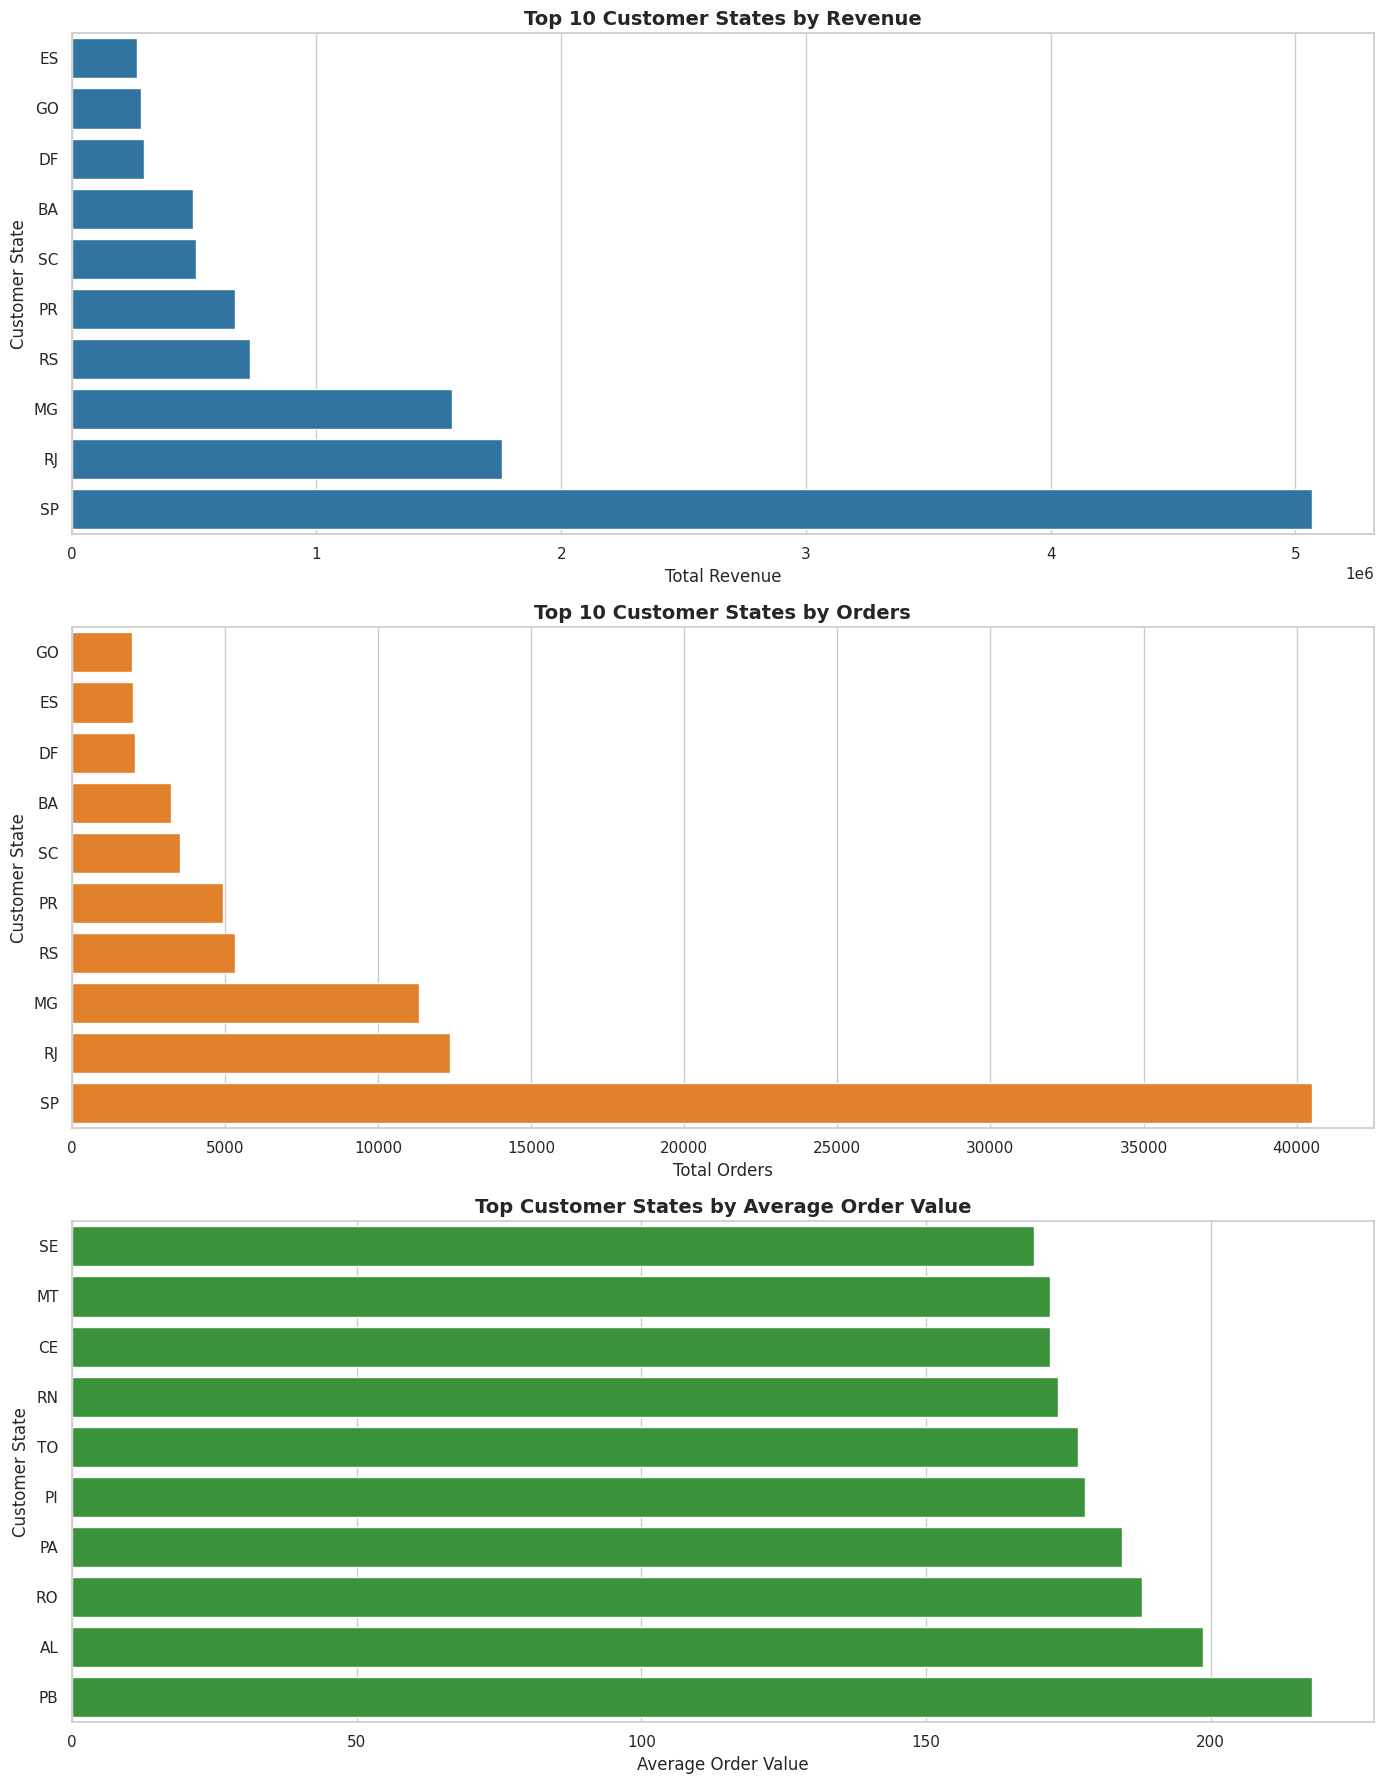

In [279]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 18)
)

# Grafik revenue
revenue_state_plot = (
    top_10_states_revenue
    .sort_values(
        'total_revenue',
        ascending=True
    )
)

sns.barplot(
    data=revenue_state_plot,
    x='total_revenue',
    y='customer_state_clean',
    color='#1f77b4',
    ax=axes[0]
)

axes[0].set_title(
    'Top 10 Customer States by Revenue',
    fontsize=14,
    fontweight='bold'
)
axes[0].set_xlabel('Total Revenue')
axes[0].set_ylabel('Customer State')

# Grafik order
orders_state_plot = (
    top_10_states_orders
    .sort_values(
        'total_orders',
        ascending=True
    )
)

sns.barplot(
    data=orders_state_plot,
    x='total_orders',
    y='customer_state_clean',
    color='#ff7f0e',
    ax=axes[1]
)

axes[1].set_title(
    'Top 10 Customer States by Orders',
    fontsize=14,
    fontweight='bold'
)
axes[1].set_xlabel('Total Orders')
axes[1].set_ylabel('Customer State')

# Grafik AOV
aov_state_plot = (
    top_10_states_aov
    .sort_values(
        'average_order_value',
        ascending=True
    )
)

sns.barplot(
    data=aov_state_plot,
    x='average_order_value',
    y='customer_state_clean',
    color='#2ca02c',
    ax=axes[2]
)

axes[2].set_title(
    'Top Customer States by Average Order Value',
    fontsize=14,
    fontweight='bold'
)
axes[2].set_xlabel('Average Order Value')
axes[2].set_ylabel('Customer State')

plt.tight_layout()
plt.show()

In [280]:
#Validasi geograpic performance
geographic_performance_validation = pd.DataFrame({
    'validation': [
        'Required geographic columns are available',
        'Order ID has no missing values',
        'Customer state has no missing values',
        'Customer state has no unknown values',
        'Order ID is unique',
        'Each order has only one customer state',
        'Geographic revenue reconciles with KPI overview',
        'Geographic orders reconcile with KPI overview',
        'Geographic units reconcile with KPI overview',
        'Revenue contribution sums to 100 percent',
        'Order contribution sums to 100 percent',
        'Unit contribution sums to 100 percent',
        'Geographic metrics contain no infinite values',
        'All geographic revenues are non-negative',
        'All geographic order counts are positive'
    ],
    'result': [
        len(missing_geographic_columns) == 0,

        df_geographic_analysis[
            'order_id'
        ].isnull().sum() == 0,

        df_geographic_analysis[
            'customer_state_clean'
        ].isnull().sum() == 0,

        (
            df_geographic_analysis[
                'customer_state_clean'
            ] == 'UNKNOWN'
        ).sum() == 0,

        ~df_geographic_analysis[
            'order_id'
        ].duplicated().any(),

        len(orders_with_multiple_states) == 0,

        np.isclose(
            geographic_performance[
                'total_revenue'
            ].sum(),
            total_revenue
        ),

        geographic_performance[
            'total_orders'
        ].sum() == total_orders,

        np.isclose(
            geographic_performance[
                'total_units_sold'
            ].sum(),
            total_items_sold
        ),

        np.isclose(
            geographic_performance[
                'revenue_contribution_pct'
            ].sum(),
            100
        ),

        np.isclose(
            geographic_performance[
                'order_contribution_pct'
            ].sum(),
            100
        ),

        np.isclose(
            geographic_performance[
                'unit_contribution_pct'
            ].sum(),
            100
        ),

        ~np.isinf(
            geographic_performance[
                [
                    'average_order_value',
                    'average_units_per_order',
                    'revenue_contribution_pct',
                    'order_contribution_pct',
                    'unit_contribution_pct'
                ]
            ]
        ).any().any(),

        geographic_performance[
            'total_revenue'
        ].ge(0).all(),

        geographic_performance[
            'total_orders'
        ].gt(0).all()
    ]
})

geographic_performance_validation[
    'status'
] = np.where(
    geographic_performance_validation['result'],
    'PASS',
    'CHECK'
)

print("GEOGRAPHIC PERFORMANCE VALIDATION")

display(geographic_performance_validation)

print(
    "\nAll Geographic Performance validation checks passed:",
    geographic_performance_validation[
        'result'
    ].all()
)

GEOGRAPHIC PERFORMANCE VALIDATION


,validation,result,status
0,Required geographic columns are available,True,PASS
1,Order ID has no missing values,True,PASS
2,Customer state has no missing values,True,PASS
3,Customer state has no unknown values,True,PASS
4,Order ID is unique,True,PASS
5,Each order has only one customer state,True,PASS
6,Geographic revenue reconciles with KPI overview,True,PASS
7,Geographic orders reconcile with KPI overview,True,PASS
8,Geographic units reconcile with KPI overview,True,PASS
9,Revenue contribution sums to 100 percent,True,PASS



All Geographic Performance validation checks passed: True


# EXPORT DATA FOR TABLEAU

In [281]:
# Menentukan kolom tanggal
date_columns_sales = [
    'order_purchase_timestamp',
    'order_date'
]

date_columns_order = [
    'order_date'
]

# Memastikan tipe data tanggal sudah benar
for column in date_columns_sales:
    df_sales_merged[column] = pd.to_datetime(
        df_sales_merged[column],
        errors='coerce'
    )

for column in date_columns_order:
    df_order_payment_merged[column] = pd.to_datetime(
        df_order_payment_merged[column],
        errors='coerce'
    )

# Export ke CSV
df_sales_merged.to_csv(
    '/content/olist_sales_item_level.csv',
    index=False,
    encoding='utf-8-sig'
)

df_order_payment_merged.to_csv(
    '/content/olist_sales_order_level.csv',
    index=False,
    encoding='utf-8-sig'
)

print('Kedua file CSV berhasil dibuat.')

Kedua file CSV berhasil dibuat.


In [282]:
import os

files_to_check = [
    '/content/olist_sales_item_level.csv',
    '/content/olist_sales_order_level.csv'
]

for file_path in files_to_check:
    file_size_mb = os.path.getsize(file_path) / (1024 ** 2)

    print(
        os.path.basename(file_path),
        ':',
        round(file_size_mb, 2),
        'MB'
    )

olist_sales_item_level.csv : 30.64 MB
olist_sales_order_level.csv : 17.26 MB


In [283]:
from google.colab import files

files.download('/content/olist_sales_item_level.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [284]:
files.download('/content/olist_sales_order_level.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>